# Factor analízis

✅ Data split successfully.
  - Training Data (Before 2021-10-01): (1699, 524)
  - Validation Data (2021-10-01 to 2023-04-01): (377, 524)
  - Testing Data (After 2023-04-01):   (772, 524)

Setting up the Orthogonal Factor Tournament (Training Set Only)...
Base Factors (Fixed Macro Pillars): ['SPY', 'GLD', 'TLT', 'USO', 'UUP']
Strict Thematic Candidates: 15
Total Stocks in Limited Tournament: 100

Starting orthogonal regression loop on Training Data...


/tmp/ipykernel_1586/66868874.py:168: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


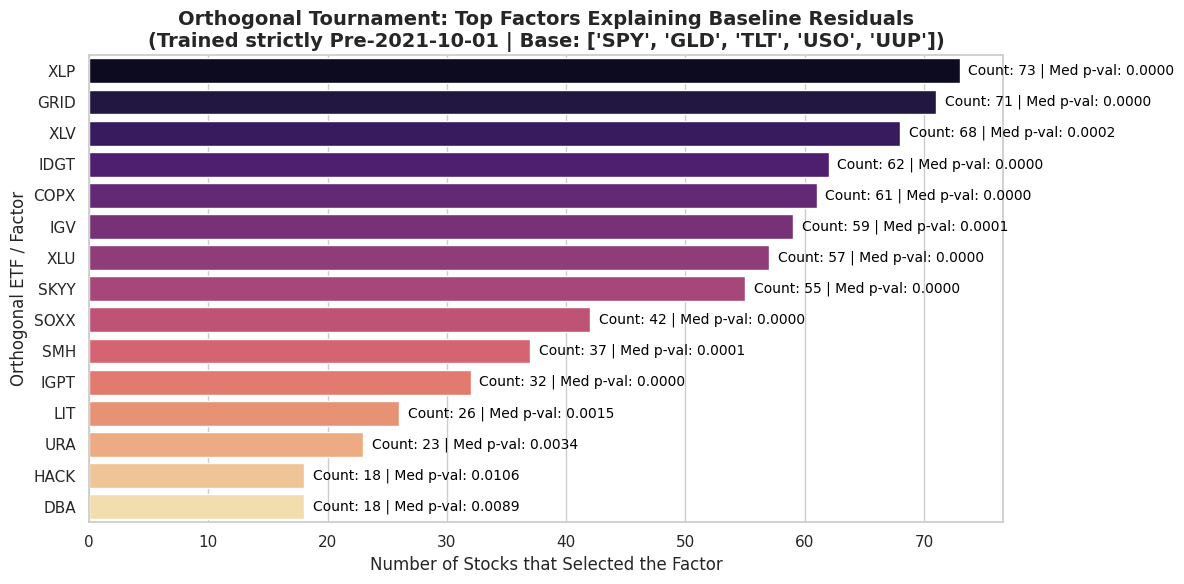


🏆 THE TOP FACTORS ADDING UNIQUE (ORTHOGONAL) ALPHA:
Factor  Selection_Count
   XLP               73
  GRID               71
   XLV               68
  IDGT               62
  COPX               61
   IGV               59
   XLU               57
  SKYY               55


In [ ]:
# ==========================================
# 0. DATA INGESTION & 3-WAY SPLIT
# ==========================================
val_cutoff_date = '2021-10-01'
test_cutoff_date = '2023-04-01'


val_date_obj = pd.to_datetime(val_cutoff_date)
test_date_obj = pd.to_datetime(test_cutoff_date)

# Create the 3 splits
df_train = df[df.index < val_date_obj]
df_val = df[(df.index >= val_date_obj) & (df.index < test_date_obj)]
df_test = df[df.index >= test_date_obj]

print(f"✅ Data split successfully.")
print(f"  - Training Data (Before {val_cutoff_date}): {df_train.shape}")
print(f"  - Validation Data ({val_cutoff_date} to {test_cutoff_date}): {df_val.shape}")
print(f"  - Testing Data (After {test_cutoff_date}):   {df_test.shape}\n")

print("Setting up the Orthogonal Factor Tournament (Training Set Only)...")

# ==========================================
# 1. CONFIGURE THE TOURNAMENT PARAMETERS
# ==========================================
# The 5 Orthogonal Macro Pillars
base_factors = ['SPY', 'GLD', 'TLT', 'USO', 'UUP']

# Your targeted 100-stock roster
limited_target_stocks = [
    # Core AI & Tech
    'AAPL', 'MSFT', 'NVDA', 'GOOGL', 'AMZN', 'META', 'AVGO', 'AMD', 'INTC', 'QCOM',
    'TSM', 'ASML', 'AMAT', 'LRCX', 'KLAC', 'MU', 'MRVL', 'SNPS', 'CDNS', 'ORCL',
    'IBM', 'CRM', 'NOW', 'ADBE', 'INTU',

    # Infrastructure, Data Centers, Networking
    'DLR', 'EQIX', 'AMT', 'CCI', 'ANET', 'CSCO', 'ETN', 'EMR', 'PWR', 'HUBB',
    'MOD', 'MSI', 'VRSN', 'AKAM', 'STX',

    # Utilities (Grid capex thesis)
    'AES', 'AEP', 'DUK', 'ED', 'EXC', 'NEE', 'PCG', 'PEG', 'SO', 'SRE',
    'XEL', 'AWK', 'ETR', 'EVRG', 'WEC',

    # Industrials, Materials, traditional Energy
    'CAT', 'DE', 'GE', 'HON', 'LMT', 'RTX', 'BA', 'UPS', 'UNP', 'URI',
    'PH', 'FCX', 'NEM', 'BHP', 'RIO', 'XOM', 'CVX', 'COP', 'SLB', 'HAL',

    # Controls (Financials, Health, Consumer)
    'JPM', 'BAC', 'GS', 'V', 'MA', 'JNJ', 'UNH', 'LLY', 'ABBV', 'PFE',
    'PG', 'KO', 'PEP', 'WMT', 'COST', 'MCD', 'DIS', 'NKE', 'HD', 'LOW',
    'SBUX', 'NFLX', 'TSLA', 'BX', 'C'
]

# The STRICT, Low-Correlation Thematic Predictors (Correlated Cousins Removed)
all_predictors = [
    # Utilities & Grid Infrastructure
    'XLU', 'UTES', 'GRID', 'PAVE',
    # Critical AI Materials (Copper, Uranium, Lithium)
    'COPX', 'COPP', 'COPA', 'URA', 'URNM', 'NUUR', 'LIT',
    # Uncorrelated Defensives & Agriculture (Controls)
    'XLP', 'XLV', 'DBA',
    # Tech, Data Centers, Cybersecurity & AI
    'SMH', 'SOXX', 'SOXQ', 'CHAT', 'THNQ', 'WTAI', 'IDGT', 'AIQ', 'SRVR',
    'IGV', 'SKYY', 'QTUM', 'IVES', 'IGPT', 'CIBR', 'HACK', 'BUG'
]

# Ensure targets and base factors actually exist in the dataframe
valid_targets = [s for s in limited_target_stocks if s in df_train.columns]
valid_base = [b for b in base_factors if b in df_train.columns]
candidate_predictors = [p for p in all_predictors if p in df_train.columns and p not in valid_base]

print(f"Base Factors (Fixed Macro Pillars): {valid_base}")
print(f"Strict Thematic Candidates: {len(candidate_predictors)}")
print(f"Total Stocks in Limited Tournament: {len(valid_targets)}")

# Pre-calculate log returns ONLY for the training set to avoid look-ahead bias
returns_train = np.log(df_train / df_train.shift(1)).dropna()

# ==========================================
# 2. SILENT STEPWISE FUNCTION (For Residuals)
# ==========================================
def silent_stepwise_residual(X, y_res, threshold_in=0.05, threshold_out=0.10):
    """ Stepwise algorithm optimized to find orthogonal factors explaining a residual """
    included = []
    while True:
        changed = False
        excluded = list(set(X.columns) - set(included))
        new_pval = pd.Series(index=excluded, dtype=float)

        # Forward Step
        for new_col in excluded:
            model = sm.OLS(y_res, sm.add_constant(X[included + [new_col]])).fit()
            new_pval[new_col] = model.pvalues[new_col]

        if not new_pval.empty:
            best_pval = new_pval.min()
            if best_pval < threshold_in:
                included.append(new_pval.idxmin())
                changed = True

        # Backward Step
        if included:
            model = sm.OLS(y_res, sm.add_constant(X[included])).fit()
            pvalues = model.pvalues.iloc[1:]
            if not pvalues.empty:
                worst_pval = pvalues.max()
                if worst_pval > threshold_out:
                    included.remove(pvalues.idxmax())
                    changed = True

        if not changed:
            break
    return included

# ==========================================
# 3. RUN THE ORTHOGONAL TOURNAMENT LOOP
# ==========================================
print("\nStarting orthogonal regression loop on Training Data...")
results_list = []

for stock in valid_targets:
    y_raw = returns_train[stock]

    # STEP A: Fit the Fixed Base Model (e.g., SPY + GLD)
    X_base = sm.add_constant(returns_train[valid_base])
    base_model = sm.OLS(y_raw, X_base).fit()

    # STEP B: Extract the Orthogonal Residual
    # This residual has exactly 0.0 correlation to SPY and GLD
    y_residual = base_model.resid

    # STEP C: Run Stepwise on the pure residual
    X_candidates = returns_train[candidate_predictors]
    selected_features = silent_stepwise_residual(X_candidates, y_residual)

    # If the algorithm found factors that significantly explain the residual
    if selected_features:
        final_res_model = sm.OLS(y_residual, sm.add_constant(X_candidates[selected_features])).fit()
        pvals = final_res_model.pvalues.iloc[1:]

        for factor in selected_features:
            results_list.append({
                'Stock': stock,
                'Factor': factor,
                'P_Value': pvals[factor]
            })

# ==========================================
# 4. AGGREGATE & VISUALIZE RESULTS
# ==========================================
if not results_list:
    print("❌ No additional factors met the threshold to explain the residuals.")
else:
    results_df = pd.DataFrame(results_list)

    # Group by Factor
    summary_df = results_df.groupby('Factor').agg(
        Selection_Count=('Stock', 'count'),
        Median_P_Value=('P_Value', 'median')
    ).reset_index()

    summary_df = summary_df.sort_values(by='Selection_Count', ascending=False)

    # Plotting
    plt.figure(figsize=(12, 6))
    sns.set_theme(style="whitegrid")

    ax = sns.barplot(
        data=summary_df,
        x='Selection_Count',
        y='Factor',
        palette="magma"
    )

    # Annotate bars
    for p in ax.patches:
        width = p.get_width()
        plt.text(
            width + (summary_df['Selection_Count'].max() * 0.01),
            p.get_y() + p.get_height() / 2,
            f"Count: {int(width)} | Med p-val: {summary_df[summary_df['Factor'] == summary_df.iloc[int(p.get_y())]['Factor']]['Median_P_Value'].values[0]:.4f}",
            va='center',
            fontsize=10,
            color='black'
        )

    plt.title(f"Orthogonal Tournament: Top Factors Explaining Baseline Residuals\n(Trained strictly Pre-{val_cutoff_date} | Base: {valid_base})", fontsize=14, fontweight='bold')
    plt.xlabel("Number of Stocks that Selected the Factor", fontsize=12)
    plt.ylabel("Orthogonal ETF / Factor", fontsize=12)
    plt.tight_layout()
    plt.show()

    print("\n🏆 THE TOP FACTORS ADDING UNIQUE (ORTHOGONAL) ALPHA:")
    print(summary_df.head(8)[['Factor', 'Selection_Count']].to_string(index=False))

# Cutoff date számolás

Loading data from /content/drive/MyDrive/Cleaned_AI_Factor_Data.csv...
🔒 Training Data Locked (Pre-2021-10-01): 1698 trading days.
Prepared 64 different factor combinations to test.
Scanning out-of-sample data across all combinations...

🏆 EXHAUSTIVE GRID SEARCH COMPLETE 🏆
Optimal Factor List  : SPY + GLD + TLT + UUP + USO + XLV
Optimal Break Date   : 2023-04-01
Maximum R² Drop      : 0.2258


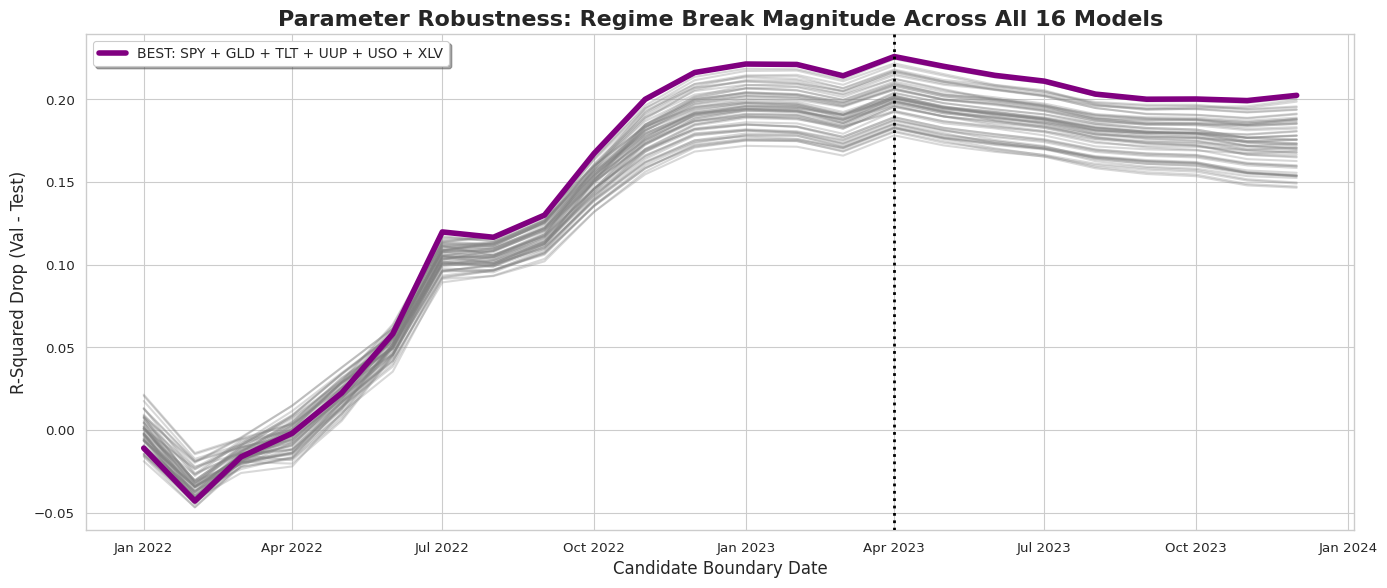

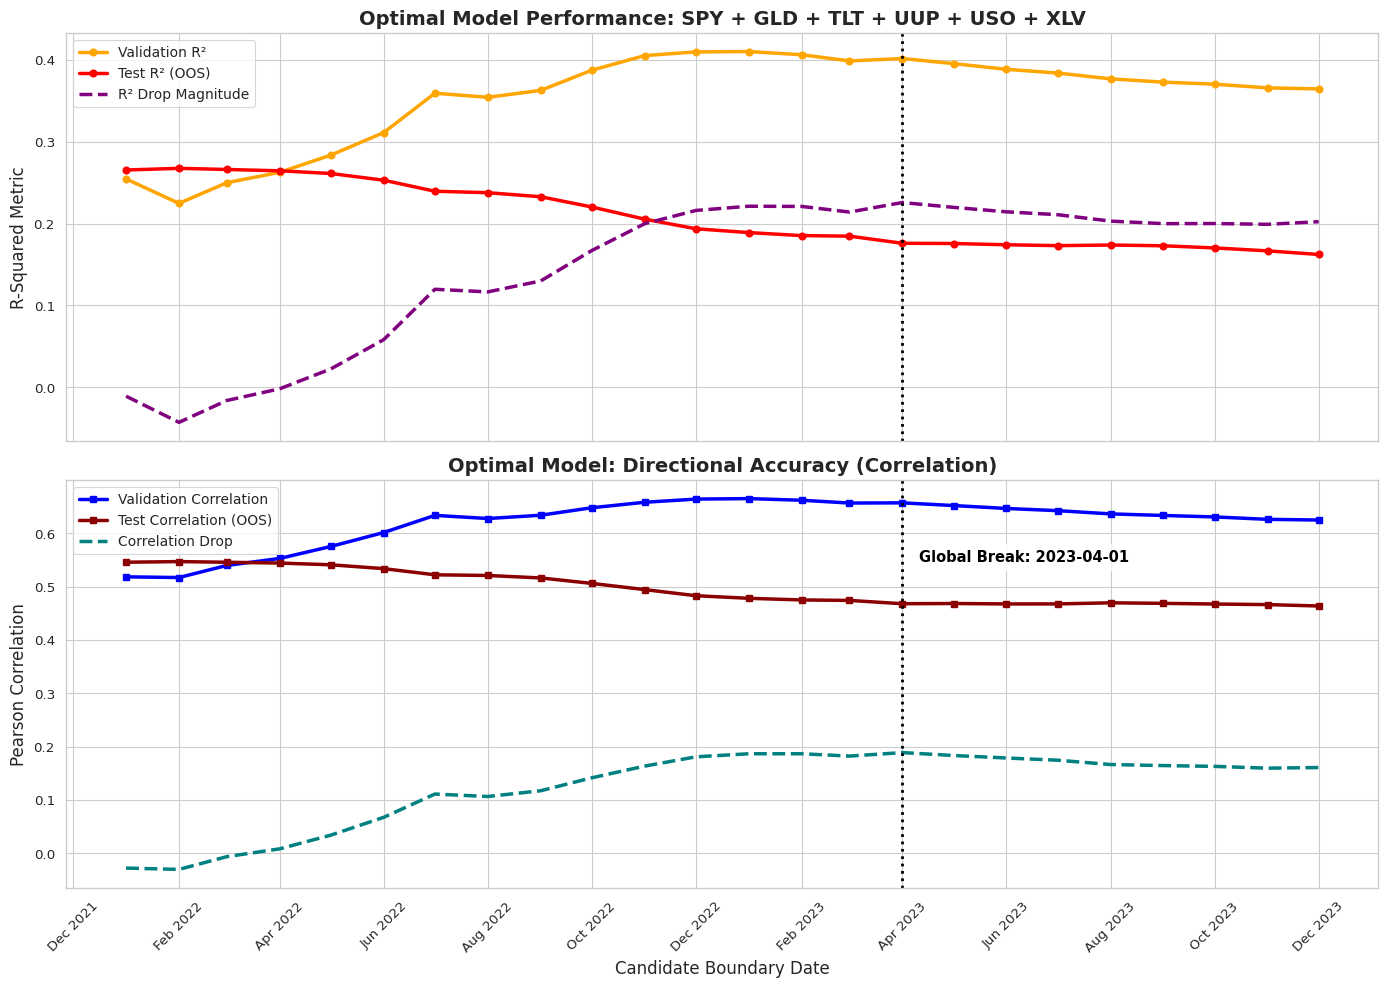

In [ ]:
# ==========================================
# 1. DATA INGESTION & FIXED TRAINING SPLIT
# ==========================================
file_path = '/content/drive/MyDrive/Cleaned_AI_Factor_Data.csv'
train_end_date = '2021-10-01'

print(f"Loading data from {file_path}...")
df = pd.read_csv(file_path, index_col=0, parse_dates=True)

# Calculate log returns globally
returns_df = np.log(df / df.shift(1)).dropna()

# Lock in the training data (Pre-2021-10-01)
train_data = returns_df[returns_df.index < pd.to_datetime(train_end_date)]
post_train_data = returns_df[returns_df.index >= pd.to_datetime(train_end_date)]

print(f"🔒 Training Data Locked (Pre-{train_end_date}): {len(train_data)} trading days.")

# ==========================================
# 2. UNIVERSE & COMBINATION SETUP
# ==========================================
target_stocks = [
    'AAPL', 'MSFT', 'NVDA', 'GOOGL', 'AMZN', 'META', 'AVGO', 'AMD', 'INTC', 'QCOM',
    'TSM', 'ASML', 'AMAT', 'LRCX', 'KLAC', 'MU', 'MRVL', 'SNPS', 'CDNS', 'ORCL',
    'IBM', 'CRM', 'NOW', 'ADBE', 'INTU',
    'DLR', 'EQIX', 'AMT', 'CCI', 'ANET', 'CSCO', 'ETN', 'EMR', 'PWR', 'HUBB',
    'MOD', 'MSI', 'VRSN', 'AKAM', 'STX',
    'AES', 'AEP', 'DUK', 'ED', 'EXC', 'NEE', 'PCG', 'PEG', 'SO', 'SRE',
    'XEL', 'AWK', 'ETR', 'EVRG', 'WEC',
    'CAT', 'DE', 'GE', 'HON', 'LMT', 'RTX', 'BA', 'UPS', 'UNP', 'URI',
    'PH', 'FCX', 'NEM', 'BHP', 'RIO', 'XOM', 'CVX', 'COP', 'SLB', 'HAL',
    'JPM', 'BAC', 'GS', 'V', 'MA', 'JNJ', 'UNH', 'LLY', 'ABBV', 'PFE',
    'PG', 'KO', 'PEP', 'WMT', 'COST', 'MCD', 'DIS', 'NKE', 'HD', 'LOW',
    'SBUX', 'NFLX', 'TSLA', 'BX', 'C'
]

valid_targets = [s for s in target_stocks if s in returns_df.columns]

# Define the fixed vs variable factors
fixed_factors = ['SPY', 'GLD', 'TLT', 'UUP']
variable_factors = ['USO', 'XLP', 'GRID', 'XLV', 'SOXX', 'SMH']

# Generate all possible combinations of the variable factors (length 0 to 4)
all_combinations = []
for r in range(len(variable_factors) + 1):
    for combo in combinations(variable_factors, r):
        all_combinations.append(list(combo))

print(f"Prepared {len(all_combinations)} different factor combinations to test.")

# ==========================================
# 3. OPTIMIZATION LOOP
# ==========================================
candidate_dates = pd.date_range(start='2022-01-01', end='2023-12-01', freq='MS')

# Storage for finding the absolute best
global_best_drop = -np.inf
global_best_combo_name = None
global_best_date = None
global_best_results_df = None
all_combo_results = {} # Store timelines for all cases

print("Scanning out-of-sample data across all combinations...")

for idx, combo in enumerate(all_combinations):
    current_factors = fixed_factors + combo
    combo_name = " + ".join(current_factors)

    # 1. Pre-train models for this specific combination (Saves immense compute time)
    X_train = sm.add_constant(train_data[current_factors])
    trained_models = {}
    sst_train_mean = {}

    for stock in valid_targets:
        trained_models[stock] = sm.OLS(train_data[stock], X_train).fit()
        sst_train_mean[stock] = train_data[stock].mean()

    combo_metrics = []

    for cutoff in candidate_dates:
        val_data = post_train_data[post_train_data.index < cutoff]
        test_data = post_train_data[post_train_data.index >= cutoff]

        if len(val_data) < 30 or len(test_data) < 30:
            continue

        val_r2_list, test_r2_list = [], []
        val_corr_list, test_corr_list = [], []

        X_val = sm.add_constant(val_data[current_factors], has_constant='add')
        X_test = sm.add_constant(test_data[current_factors], has_constant='add')

        for stock in valid_targets:
            model = trained_models[stock]
            hist_mean = sst_train_mean[stock]

            # Validation
            y_val = val_data[stock]
            y_val_pred = model.predict(X_val)
            ssr_val = ((y_val - y_val_pred) ** 2).sum()
            sst_val = ((y_val - hist_mean) ** 2).sum()
            val_r2_list.append(1 - (ssr_val / sst_val) if sst_val != 0 else 0)

            v_corr = pd.Series(y_val).corr(pd.Series(y_val_pred))
            val_corr_list.append(v_corr if pd.notna(v_corr) else 0)

            # Testing
            y_test = test_data[stock]
            y_test_pred = model.predict(X_test)
            ssr_test = ((y_test - y_test_pred) ** 2).sum()
            sst_test = ((y_test - hist_mean) ** 2).sum()
            test_r2_list.append(1 - (ssr_test / sst_test) if sst_test != 0 else 0)

            t_corr = pd.Series(y_test).corr(pd.Series(y_test_pred))
            test_corr_list.append(t_corr if pd.notna(t_corr) else 0)

        # Averages
        avg_val_r2 = np.mean(val_r2_list)
        avg_test_r2 = np.mean(test_r2_list)
        r2_drop = avg_val_r2 - avg_test_r2

        avg_val_corr = np.mean(val_corr_list)
        avg_test_corr = np.mean(test_corr_list)

        combo_metrics.append({
            'Cutoff_Date': cutoff,
            'Val_R2': avg_val_r2,
            'Test_R2': avg_test_r2,
            'R2_Drop': r2_drop,
            'Val_Corr': avg_val_corr,
            'Test_Corr': avg_test_corr,
            'Corr_Drop': avg_val_corr - avg_test_corr
        })

    combo_df = pd.DataFrame(combo_metrics)
    all_combo_results[combo_name] = combo_df

    # Check if this combination holds the global maximum drop
    if not combo_df.empty:
        max_drop_idx = combo_df['R2_Drop'].idxmax()
        if combo_df.loc[max_drop_idx, 'R2_Drop'] > global_best_drop:
            global_best_drop = combo_df.loc[max_drop_idx, 'R2_Drop']
            global_best_combo_name = combo_name
            global_best_date = combo_df.loc[max_drop_idx, 'Cutoff_Date'].strftime('%Y-%m-%d')
            global_best_results_df = combo_df.copy()

print("\n🏆 EXHAUSTIVE GRID SEARCH COMPLETE 🏆")
print(f"Optimal Factor List  : {global_best_combo_name}")
print(f"Optimal Break Date   : {global_best_date}")
print(f"Maximum R² Drop      : {global_best_drop:.4f}")

# ==========================================
# 4. VISUALIZATION
# ==========================================
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)

# --- PLOT 1: ROBUSTNESS OVERLAY (ALL COMBINATIONS) ---
plt.figure(figsize=(14, 6))
for name, c_df in all_combo_results.items():
    if name == global_best_combo_name:
        plt.plot(c_df['Cutoff_Date'], c_df['R2_Drop'], label=f'BEST: {name}', color='purple', linewidth=4, zorder=10)
    else:
        plt.plot(c_df['Cutoff_Date'], c_df['R2_Drop'], color='gray', alpha=0.3, linewidth=1.5)

plt.axvline(x=pd.to_datetime(global_best_date), color='black', linestyle=':', linewidth=2, zorder=11)
plt.title("Parameter Robustness: Regime Break Magnitude Across All 16 Models", fontsize=16, fontweight='bold')
plt.xlabel("Candidate Boundary Date", fontsize=12)
plt.ylabel("R-Squared Drop (Val - Test)", fontsize=12)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.legend(loc='upper left', fontsize=10, frameon=True, shadow=True)
plt.tight_layout()
plt.show()

# --- PLOT 2 & 3: DUAL-PANEL FOR THE ABSOLUTE BEST MODEL ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

# 2A: R-SQUARED
ax1.plot(global_best_results_df['Cutoff_Date'], global_best_results_df['Val_R2'], label='Validation R²', color='orange', linewidth=2.5, marker='o')
ax1.plot(global_best_results_df['Cutoff_Date'], global_best_results_df['Test_R2'], label='Test R² (OOS)', color='red', linewidth=2.5, marker='o')
ax1.plot(global_best_results_df['Cutoff_Date'], global_best_results_df['R2_Drop'], label='R² Drop Magnitude', color='purple', linestyle='--', linewidth=2.5)

ax1.axvline(x=pd.to_datetime(global_best_date), color='black', linestyle=':', linewidth=2)
ax1.set_title(f"Optimal Model Performance: {global_best_combo_name}", fontsize=14, fontweight='bold')
ax1.set_ylabel("R-Squared Metric", fontsize=12)
ax1.legend(loc='best', fontsize=10)

# 2B: CORRELATION
ax2.plot(global_best_results_df['Cutoff_Date'], global_best_results_df['Val_Corr'], label='Validation Correlation', color='blue', linewidth=2.5, marker='s')
ax2.plot(global_best_results_df['Cutoff_Date'], global_best_results_df['Test_Corr'], label='Test Correlation (OOS)', color='darkred', linewidth=2.5, marker='s')
ax2.plot(global_best_results_df['Cutoff_Date'], global_best_results_df['Corr_Drop'], label='Correlation Drop', color='teal', linestyle='--', linewidth=2.5)

ax2.axvline(x=pd.to_datetime(global_best_date), color='black', linestyle=':', linewidth=2)
ax2.text(pd.to_datetime(global_best_date) + pd.Timedelta(days=10), global_best_results_df['Test_Corr'].max(),
         f"Global Break: {global_best_date}", color='black', fontweight='bold', bbox=dict(facecolor='white', alpha=0.8))

ax2.set_title("Optimal Model: Directional Accuracy (Correlation)", fontsize=14, fontweight='bold')
ax2.set_ylabel("Pearson Correlation", fontsize=12)
ax2.set_xlabel("Candidate Boundary Date", fontsize=12)
ax2.legend(loc='best', fontsize=10)

# Format X-Axis
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax2.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# Összesített eremények

✅ Data Splits:
  - Train (Pre-2021-10-01): 1698 days
  - Val   (2021-10-01 to 2023-04-01): 377 days
  - Test  (Post-2023-04-01): 772 days

Evaluating model performance across all stocks...


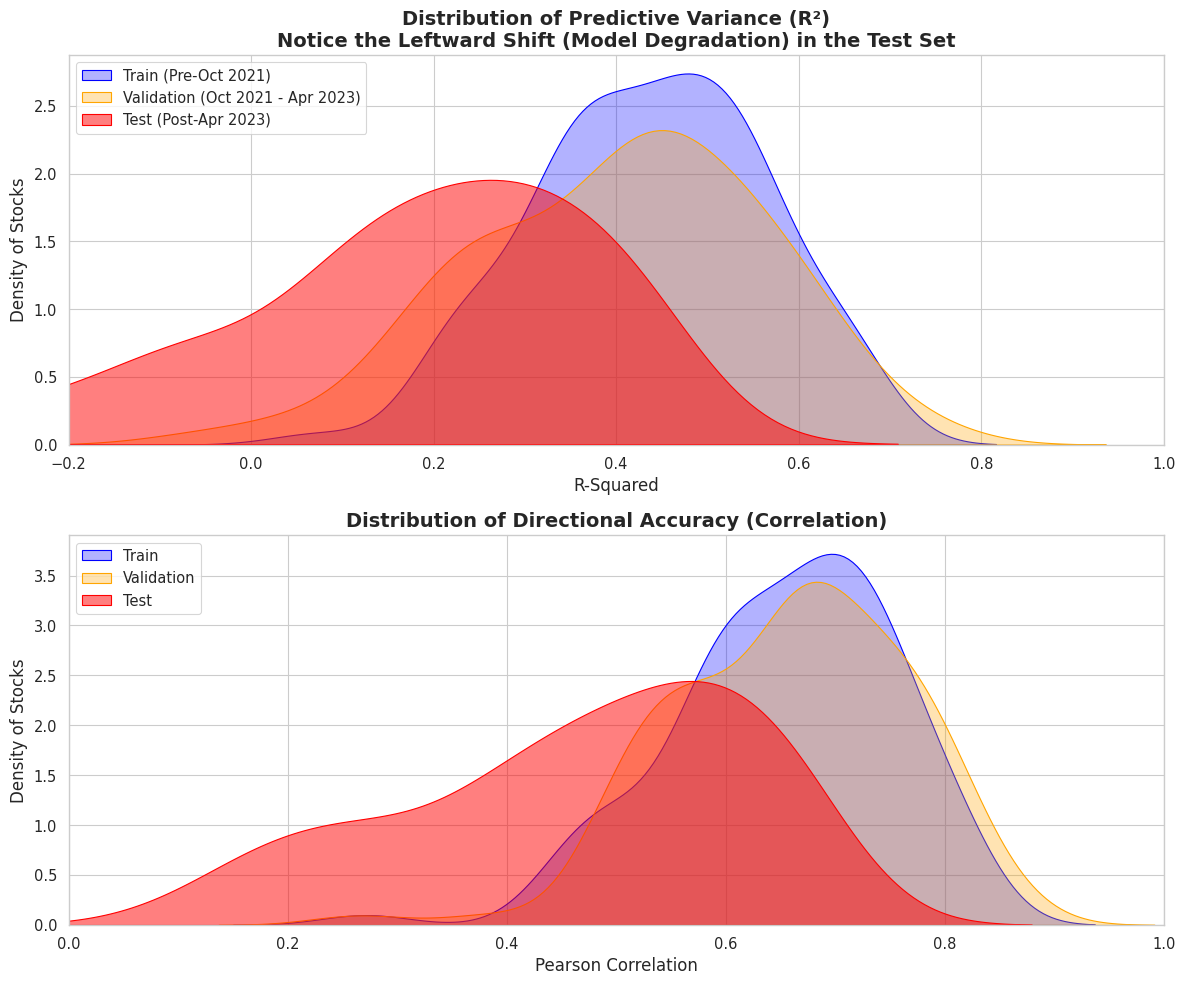

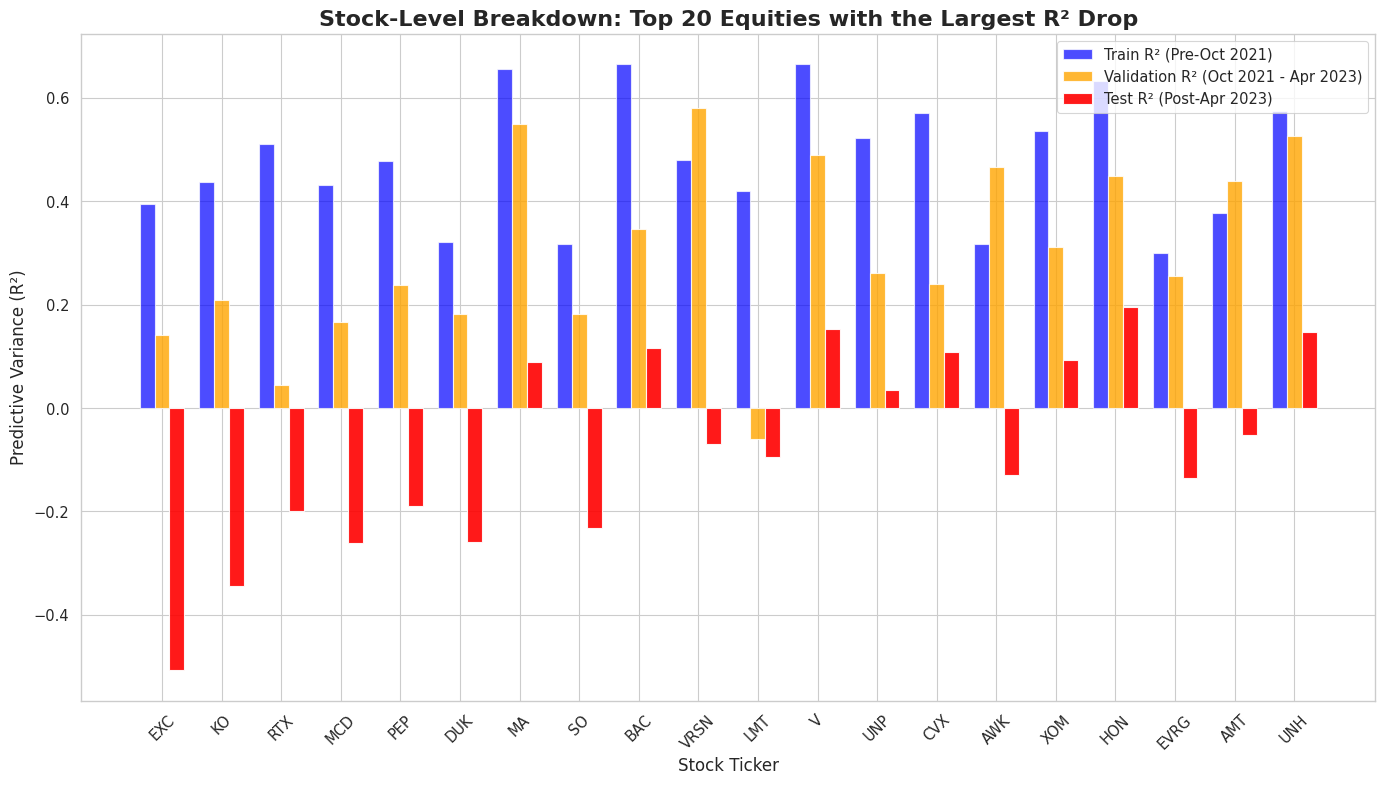

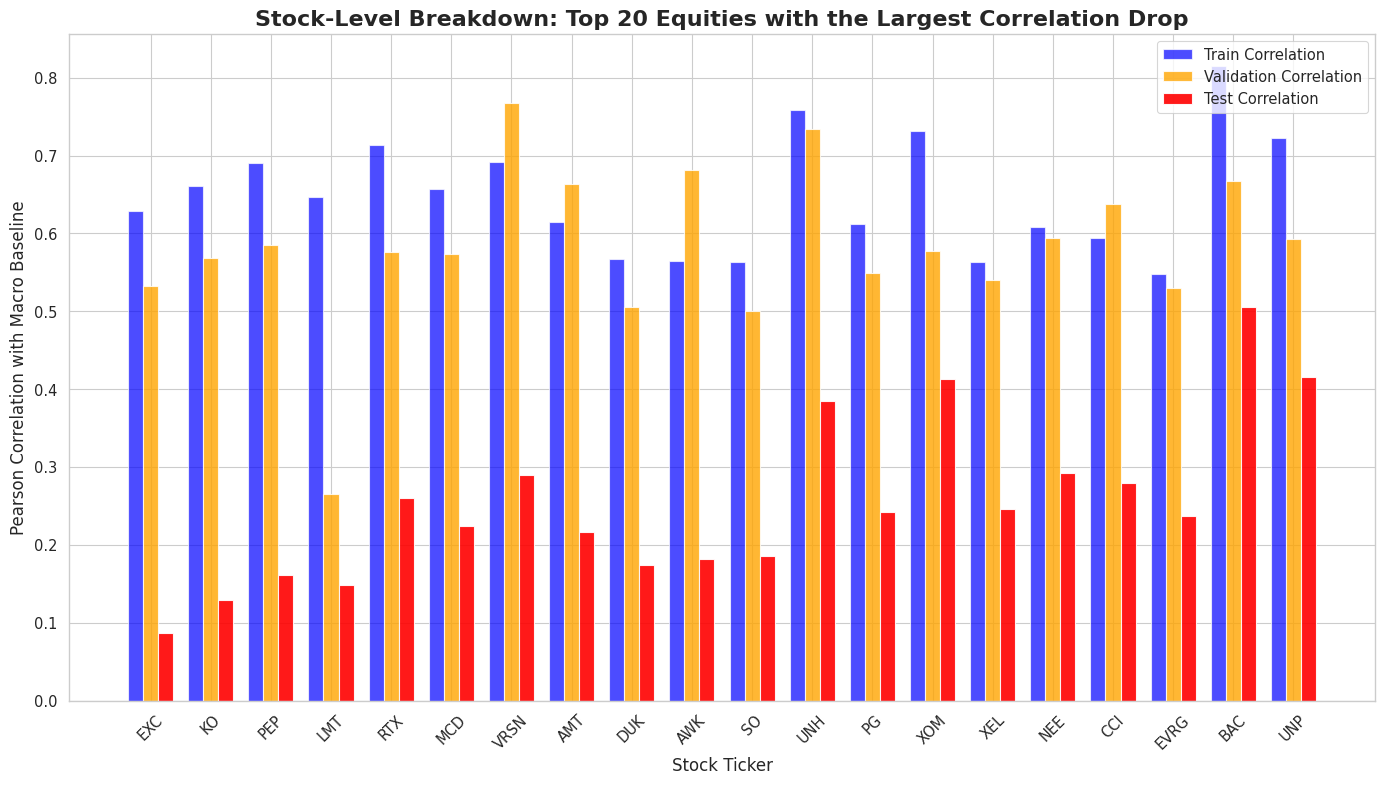


📊 QUICK SUMMARY OF THE REGIME SHIFT:
Average Train R²  : 0.4360
Average Val R²    : 0.4018
Average Test R²   : 0.1760
------------------------------
Average Train Corr: 0.6525
Average Val Corr  : 0.6571
Average Test Corr : 0.4681


In [ ]:
# ==========================================
# 1. DATA INGESTION & 3-WAY SPLIT
# ==========================================
train_end_date = '2021-10-01'
test_start_date = '2023-04-01'

returns_df = np.log(df / df.shift(1)).dropna()

# Create the 3 splits based on your exact dates
train_data = returns_df[returns_df.index < pd.to_datetime(train_end_date)]
val_data = returns_df[(returns_df.index >= pd.to_datetime(train_end_date)) & (returns_df.index < pd.to_datetime(test_start_date))]
test_data = returns_df[returns_df.index >= pd.to_datetime(test_start_date)]

print(f"✅ Data Splits:")
print(f"  - Train (Pre-{train_end_date}): {len(train_data)} days")
print(f"  - Val   ({train_end_date} to {test_start_date}): {len(val_data)} days")
print(f"  - Test  (Post-{test_start_date}): {len(test_data)} days")

# ==========================================
# 2. UNIVERSE & FINAL MODEL SETUP
# ==========================================
final_factors = ['SPY', 'GLD', 'TLT', 'USO', 'UUP', 'XLV']

target_stocks = [
    'AAPL', 'MSFT', 'NVDA', 'GOOGL', 'AMZN', 'META', 'AVGO', 'AMD', 'INTC', 'QCOM',
    'TSM', 'ASML', 'AMAT', 'LRCX', 'KLAC', 'MU', 'MRVL', 'SNPS', 'CDNS', 'ORCL',
    'IBM', 'CRM', 'NOW', 'ADBE', 'INTU',
    'DLR', 'EQIX', 'AMT', 'CCI', 'ANET', 'CSCO', 'ETN', 'EMR', 'PWR', 'HUBB',
    'MOD', 'MSI', 'VRSN', 'AKAM', 'STX',
    'AES', 'AEP', 'DUK', 'ED', 'EXC', 'NEE', 'PCG', 'PEG', 'SO', 'SRE',
    'XEL', 'AWK', 'ETR', 'EVRG', 'WEC',
    'CAT', 'DE', 'GE', 'HON', 'LMT', 'RTX', 'BA', 'UPS', 'UNP', 'URI',
    'PH', 'FCX', 'NEM', 'BHP', 'RIO', 'XOM', 'CVX', 'COP', 'SLB', 'HAL',
    'JPM', 'BAC', 'GS', 'V', 'MA', 'JNJ', 'UNH', 'LLY', 'ABBV', 'PFE',
    'PG', 'KO', 'PEP', 'WMT', 'COST', 'MCD', 'DIS', 'NKE', 'HD', 'LOW',
    'SBUX', 'NFLX', 'TSLA', 'BX', 'C'
]

valid_targets = [s for s in target_stocks if s in returns_df.columns]
valid_base = [b for b in final_factors if b in returns_df.columns]

# ==========================================
# 3. CALCULATE METRICS FOR EVERY STOCK
# ==========================================
print("\nEvaluating model performance across all stocks...")
results = []

X_train = sm.add_constant(train_data[valid_base])
X_val = sm.add_constant(val_data[valid_base], has_constant='add')
X_test = sm.add_constant(test_data[valid_base], has_constant='add')

for stock in valid_targets:
    y_train = train_data[stock]
    y_val = val_data[stock]
    y_test = test_data[stock]

    # Fit on Training Data
    model = sm.OLS(y_train, X_train).fit()

    # 1. Train Metrics
    y_train_pred = model.predict(X_train)
    train_r2 = model.rsquared
    train_corr = pd.Series(y_train).corr(pd.Series(y_train_pred))

    # 2. Validation Metrics
    y_val_pred = model.predict(X_val)
    ssr_val = ((y_val - y_val_pred) ** 2).sum()
    sst_val = ((y_val - y_train.mean()) ** 2).sum()
    val_r2 = 1 - (ssr_val / sst_val) if sst_val != 0 else 0
    val_corr = pd.Series(y_val).corr(pd.Series(y_val_pred))

    # 3. Test Metrics
    y_test_pred = model.predict(X_test)
    ssr_test = ((y_test - y_test_pred) ** 2).sum()
    sst_test = ((y_test - y_train.mean()) ** 2).sum()
    test_r2 = 1 - (ssr_test / sst_test) if sst_test != 0 else 0
    test_corr = pd.Series(y_test).corr(pd.Series(y_test_pred))

    results.append({
        'Stock': stock,
        'Train_R2': train_r2, 'Val_R2': val_r2, 'Test_R2': test_r2,
        'Train_Corr': train_corr, 'Val_Corr': val_corr, 'Test_Corr': test_corr,
        'R2_Drop': train_r2 - test_r2,
        'Corr_Drop': train_corr - test_corr
    })

results_df = pd.DataFrame(results).fillna(0)

# ==========================================
# 4. VISUALIZATION 1: DISTRIBUTION HISTOGRAMS
# ==========================================
sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10))

# Plot R2 Distribution
sns.kdeplot(results_df['Train_R2'], fill=True, color="blue", label="Train (Pre-Oct 2021)", ax=ax1, alpha=0.3)
sns.kdeplot(results_df['Val_R2'], fill=True, color="orange", label="Validation (Oct 2021 - Apr 2023)", ax=ax1, alpha=0.3)
sns.kdeplot(results_df['Test_R2'], fill=True, color="red", label="Test (Post-Apr 2023)", ax=ax1, alpha=0.5)

ax1.set_title("Distribution of Predictive Variance (R²)\nNotice the Leftward Shift (Model Degradation) in the Test Set", fontsize=14, fontweight='bold')
ax1.set_xlabel("R-Squared", fontsize=12)
ax1.set_ylabel("Density of Stocks", fontsize=12)
ax1.legend(loc='upper left')
ax1.set_xlim(-0.2, 1.0)

# Plot Correlation Distribution
sns.kdeplot(results_df['Train_Corr'], fill=True, color="blue", label="Train", ax=ax2, alpha=0.3)
sns.kdeplot(results_df['Val_Corr'], fill=True, color="orange", label="Validation", ax=ax2, alpha=0.3)
sns.kdeplot(results_df['Test_Corr'], fill=True, color="red", label="Test", ax=ax2, alpha=0.5)

ax2.set_title("Distribution of Directional Accuracy (Correlation)", fontsize=14, fontweight='bold')
ax2.set_xlabel("Pearson Correlation", fontsize=12)
ax2.set_ylabel("Density of Stocks", fontsize=12)
ax2.legend(loc='upper left')
ax2.set_xlim(0, 1.0)

plt.tight_layout()
plt.show()

# 5. VISUALIZATION 2: TOP DECOUPLING STOCKS (BAR CHARTS)
# ==========================================

# --- PLOT A: Top R-Squared Drops ---
# Sort by the largest drop in R2 from Train to Test
top_r2_droppers = results_df.sort_values(by='R2_Drop', ascending=False).head(20)

plt.figure(figsize=(14, 8))
bar_width = 0.25
x_r2 = np.arange(len(top_r2_droppers))

plt.bar(x_r2 - bar_width, top_r2_droppers['Train_R2'], width=bar_width, color='blue', label='Train R² (Pre-Oct 2021)', alpha=0.7)
plt.bar(x_r2, top_r2_droppers['Val_R2'], width=bar_width, color='orange', label='Validation R² (Oct 2021 - Apr 2023)', alpha=0.8)
plt.bar(x_r2 + bar_width, top_r2_droppers['Test_R2'], width=bar_width, color='red', label='Test R² (Post-Apr 2023)', alpha=0.9)

plt.title("Stock-Level Breakdown: Top 20 Equities with the Largest R² Drop", fontsize=16, fontweight='bold')
plt.xlabel("Stock Ticker", fontsize=12)
plt.ylabel("Predictive Variance (R²)", fontsize=12)
plt.xticks(x_r2, top_r2_droppers['Stock'], rotation=45)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


# --- PLOT B: Top Correlation Drops ---
# Sort by the largest drop in Correlation from Train to Test
top_corr_droppers = results_df.sort_values(by='Corr_Drop', ascending=False).head(20)

plt.figure(figsize=(14, 8))
x_corr = np.arange(len(top_corr_droppers))

plt.bar(x_corr - bar_width, top_corr_droppers['Train_Corr'], width=bar_width, color='blue', label='Train Correlation', alpha=0.7)
plt.bar(x_corr, top_corr_droppers['Val_Corr'], width=bar_width, color='orange', label='Validation Correlation', alpha=0.8)
plt.bar(x_corr + bar_width, top_corr_droppers['Test_Corr'], width=bar_width, color='red', label='Test Correlation', alpha=0.9)

plt.title("Stock-Level Breakdown: Top 20 Equities with the Largest Correlation Drop", fontsize=16, fontweight='bold')
plt.xlabel("Stock Ticker", fontsize=12)
plt.ylabel("Pearson Correlation with Macro Baseline", fontsize=12)
plt.xticks(x_corr, top_corr_droppers['Stock'], rotation=45)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

# --- QUICK SUMMARY PRINT ---
print("\n📊 QUICK SUMMARY OF THE REGIME SHIFT:")
print(f"Average Train R²  : {results_df['Train_R2'].mean():.4f}")
print(f"Average Val R²    : {results_df['Val_R2'].mean():.4f}")
print(f"Average Test R²   : {results_df['Test_R2'].mean():.4f}")
print("-" * 30)
print(f"Average Train Corr: {results_df['Train_Corr'].mean():.4f}")
print(f"Average Val Corr  : {results_df['Val_Corr'].mean():.4f}")
print(f"Average Test Corr : {results_df['Test_Corr'].mean():.4f}")

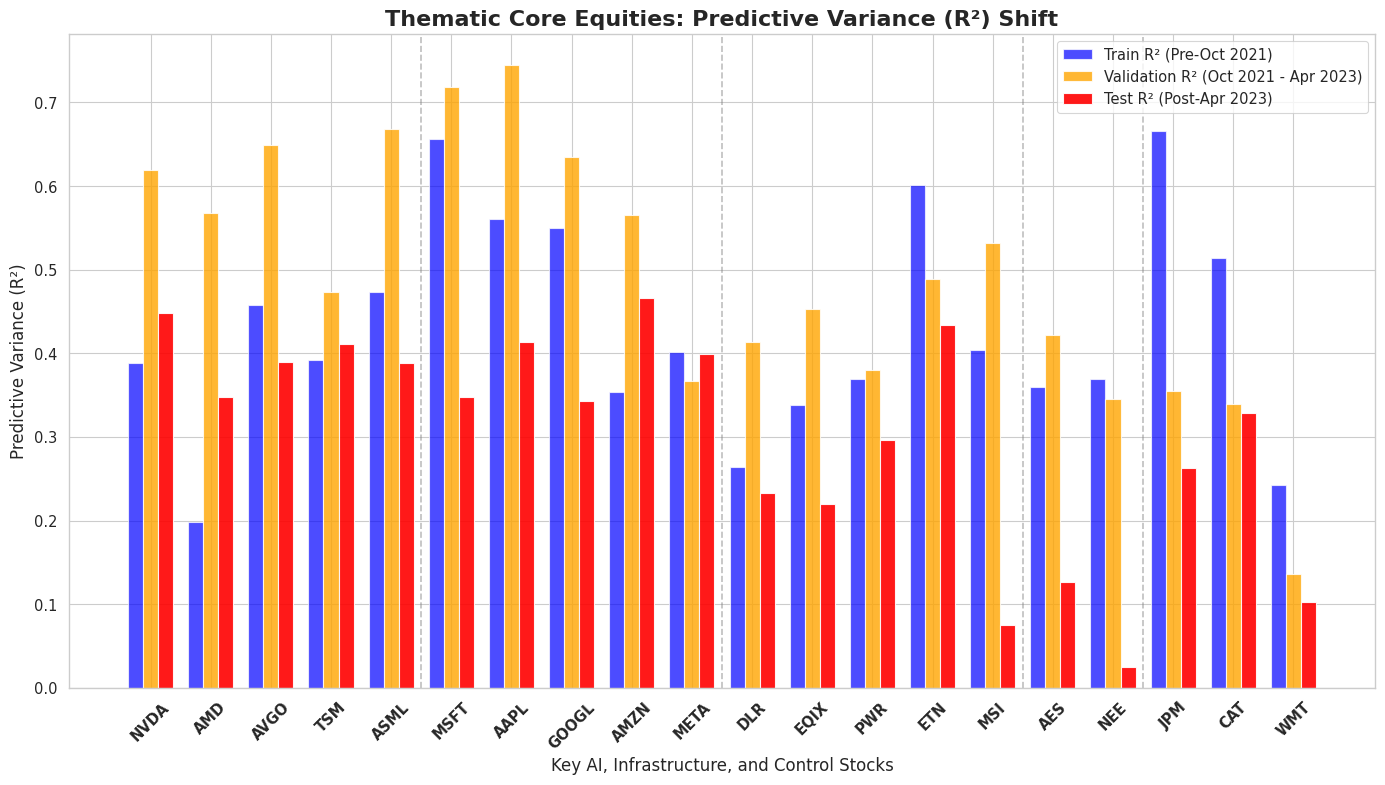

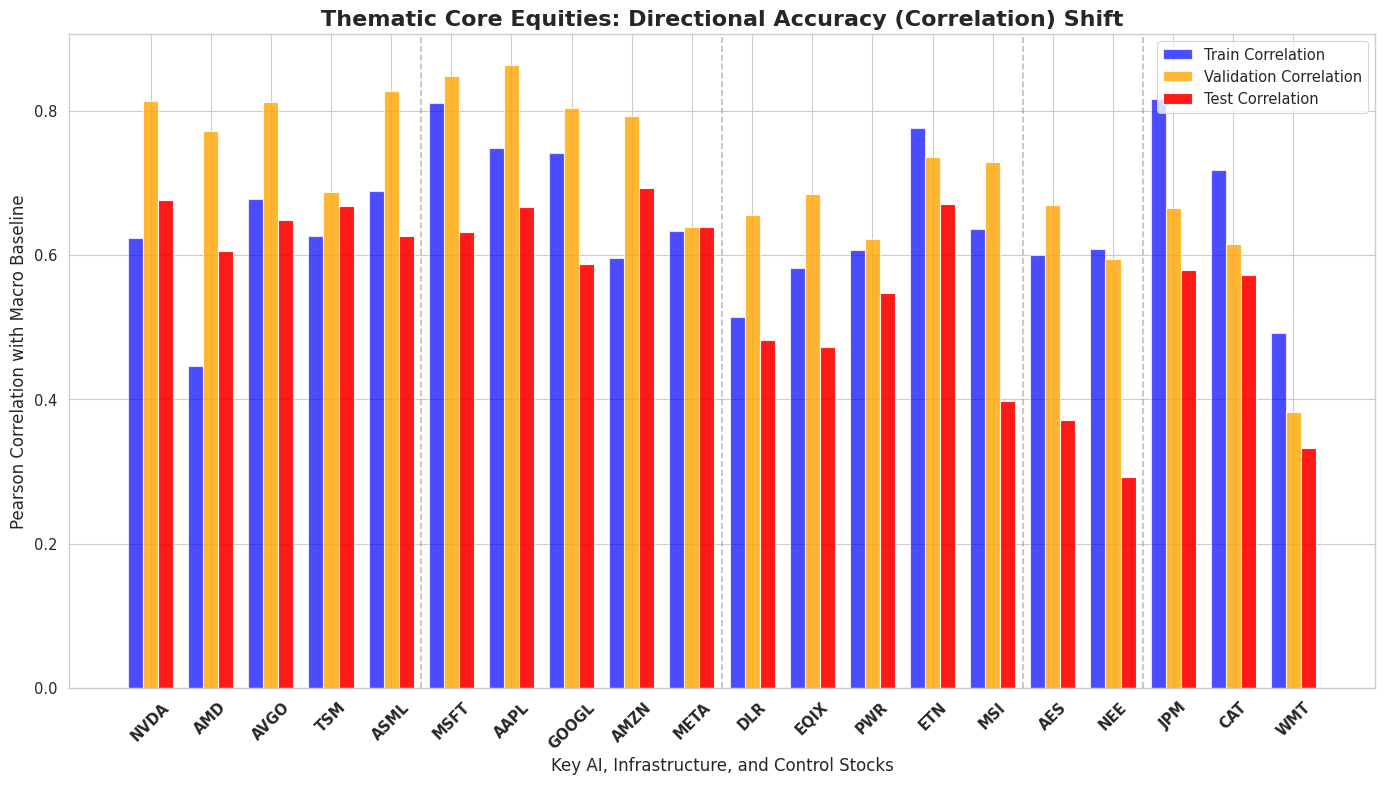

In [ ]:
# ==========================================
# 6. VISUALIZATION 3: "MARKET GENERALS" BREAKDOWN
# ==========================================

# Define your list of 20 "Most Important" stocks
# Mix of Mega-Cap Tech, Semiconductor, Data Center REITs, Utilities, and Controls
important_stocks = [
    'NVDA', 'AMD', 'AVGO', 'TSM', 'ASML', # Core AI Hardware
    'MSFT', 'AAPL', 'GOOGL', 'AMZN', 'META', # Mega-Cap Tech
    'DLR', 'EQIX', 'PWR', 'ETN', 'MSI', # Infrastructure / Data Centers
    'AES', 'NEE', # Power / Utilities
    'JPM', 'CAT', 'WMT' # Controls (Bank, Industrial, Consumer)
]

# Filter the results dataframe for only these specific stocks
core_results = results_df[results_df['Stock'].isin(important_stocks)].copy()

# Ensure they are plotted in the exact thematic order defined above
# (By setting 'Stock' as a categorical type with a specific order)
core_results['Stock'] = pd.Categorical(core_results['Stock'], categories=important_stocks, ordered=True)
core_results = core_results.sort_values('Stock')

# Set up the X-axis positions
x_core = np.arange(len(core_results))
bar_width = 0.25

# --- PLOT A: Core Stocks R-Squared ---
plt.figure(figsize=(14, 8))
plt.bar(x_core - bar_width, core_results['Train_R2'], width=bar_width, color='blue', label='Train R² (Pre-Oct 2021)', alpha=0.7)
plt.bar(x_core, core_results['Val_R2'], width=bar_width, color='orange', label='Validation R² (Oct 2021 - Apr 2023)', alpha=0.8)
plt.bar(x_core + bar_width, core_results['Test_R2'], width=bar_width, color='red', label='Test R² (Post-Apr 2023)', alpha=0.9)

plt.title("Thematic Core Equities: Predictive Variance (R²) Shift", fontsize=16, fontweight='bold')
plt.xlabel("Key AI, Infrastructure, and Control Stocks", fontsize=12)
plt.ylabel("Predictive Variance (R²)", fontsize=12)
plt.xticks(x_core, core_results['Stock'], rotation=45, fontweight='bold')

# Add subtle vertical lines to separate the themes visually
plt.axvline(x=4.5, color='gray', linestyle='--', alpha=0.5) # After ASML
plt.axvline(x=9.5, color='gray', linestyle='--', alpha=0.5) # After META
plt.axvline(x=14.5, color='gray', linestyle='--', alpha=0.5) # After MSI
plt.axvline(x=16.5, color='gray', linestyle='--', alpha=0.5) # After NEE

plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


# --- PLOT B: Core Stocks Correlation ---
plt.figure(figsize=(14, 8))
plt.bar(x_core - bar_width, core_results['Train_Corr'], width=bar_width, color='blue', label='Train Correlation', alpha=0.7)
plt.bar(x_core, core_results['Val_Corr'], width=bar_width, color='orange', label='Validation Correlation', alpha=0.8)
plt.bar(x_core + bar_width, core_results['Test_Corr'], width=bar_width, color='red', label='Test Correlation', alpha=0.9)

plt.title("Thematic Core Equities: Directional Accuracy (Correlation) Shift", fontsize=16, fontweight='bold')
plt.xlabel("Key AI, Infrastructure, and Control Stocks", fontsize=12)
plt.ylabel("Pearson Correlation with Macro Baseline", fontsize=12)
plt.xticks(x_core, core_results['Stock'], rotation=45, fontweight='bold')

# Add subtle vertical lines to separate the themes visually
plt.axvline(x=4.5, color='gray', linestyle='--', alpha=0.5)
plt.axvline(x=9.5, color='gray', linestyle='--', alpha=0.5)
plt.axvline(x=14.5, color='gray', linestyle='--', alpha=0.5)
plt.axvline(x=16.5, color='gray', linestyle='--', alpha=0.5)

plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

# Residuális analízis


Calculating residuals for the post-breakpoint period (Test Set)...
✅ Post-Breakpoint Residuals Calculated!

⚠️ Top 5 Stocks with Highest Post-Breakpoint Residual Volatility (Highest Decoupling):
  - MOD: 0.5489
  - INTC: 0.5160
  - MRVL: 0.4967
  - TSLA: 0.4709
  - MU: 0.4420


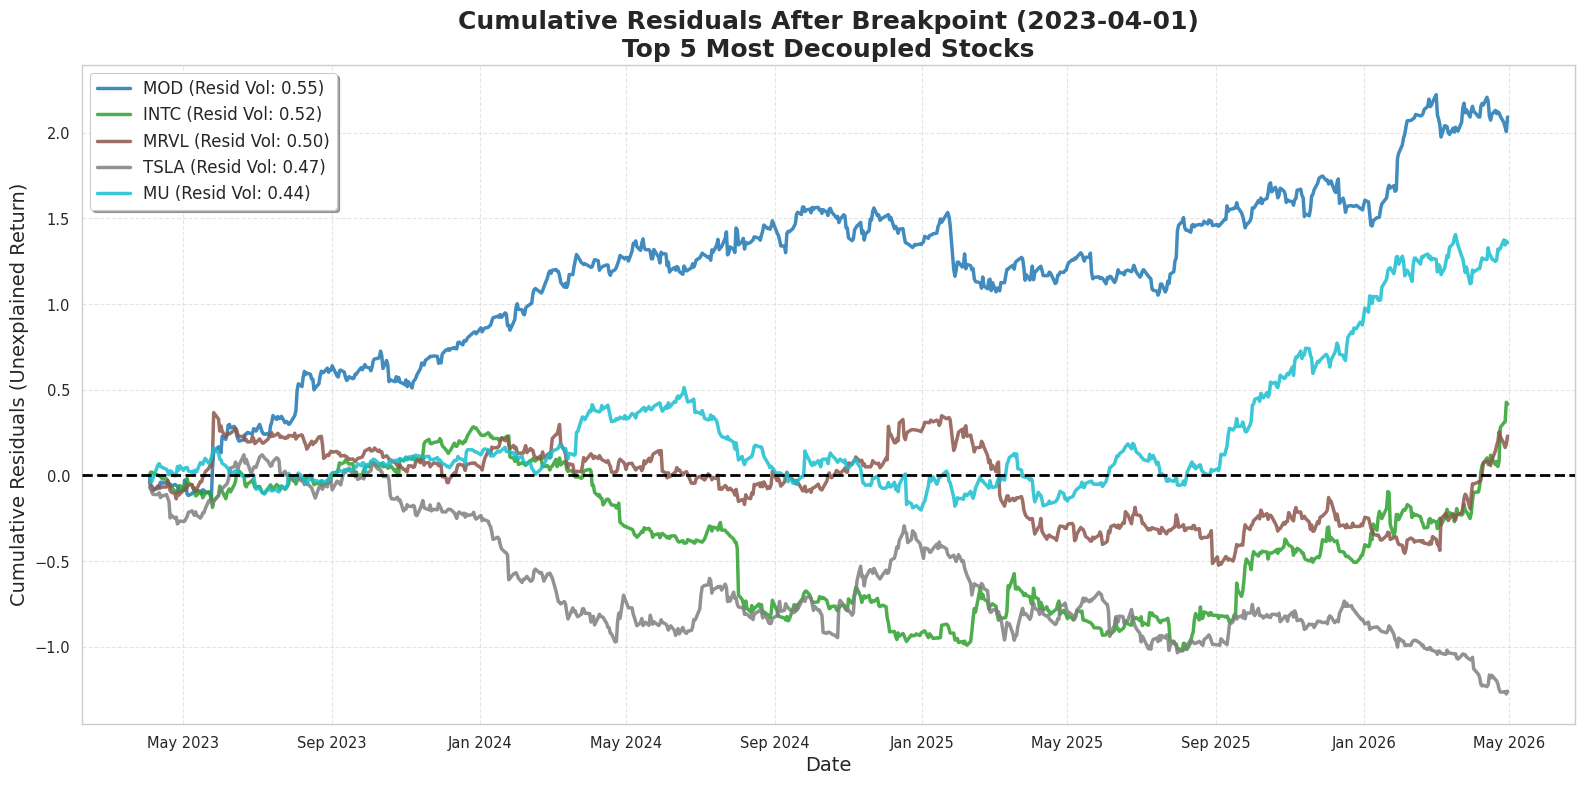

In [ ]:
# ==========================================
# POST-BREAKPOINT RESIDUAL ANALYSIS & MULTI-STOCK VISUALIZATION
# ==========================================

# Initialize a DataFrame to store the out-of-sample residuals
post_break_residuals = pd.DataFrame(index=test_data.index)

# Ensure X_train and X_test are ready (from previous cells)
X_train = sm.add_constant(train_data[valid_base])
X_test = sm.add_constant(test_data[valid_base], has_constant='add')

print("Calculating residuals for the post-breakpoint period (Test Set)...")

for stock in valid_targets:
    # 1. Fit the model on the training data (Pre-Breakpoint)
    model = sm.OLS(train_data[stock], X_train).fit()

    # 2. Predict on the test data (Post-Breakpoint)
    y_test_pred = model.predict(X_test)
    y_test_actual = test_data[stock]

    # 3. Calculate and store the residuals
    residuals = y_test_actual - y_test_pred
    post_break_residuals[stock] = residuals

print("✅ Post-Breakpoint Residuals Calculated!")

# ==========================================
# METRICS: FIND TOP DECOUPLED STOCKS
# ==========================================
# Calculate the annualized volatility of the residuals post-breakpoint
residual_volatility = post_break_residuals.std() * np.sqrt(252)

# Select how many top stocks you want to visualize
top_n = 5
top_stocks = residual_volatility.sort_values(ascending=False).head(top_n).index.tolist()

print(f"\n⚠️ Top {top_n} Stocks with Highest Post-Breakpoint Residual Volatility (Highest Decoupling):")
for stock in top_stocks:
    print(f"  - {stock}: {residual_volatility[stock]:.4f}")

# ==========================================
# VISUALIZATION: CUMULATIVE RESIDUALS (MULTI-STOCK)
# ==========================================
plt.figure(figsize=(16, 8))

# Generate a color palette so they are easily distinguishable
colors = plt.cm.tab10(np.linspace(0, 1, top_n))

# Plot cumulative residuals for the top N most volatile stocks
for idx, stock in enumerate(top_stocks):
    cum_residuals = post_break_residuals[stock].cumsum()
    plt.plot(cum_residuals.index, cum_residuals, label=f'{stock} (Resid Vol: {residual_volatility[stock]:.2f})',
             color=colors[idx], linewidth=2.5, alpha=0.85)

# Add a flat baseline at 0 to show where a "perfect" model would sit
plt.axhline(0, color='black', linestyle='--', linewidth=2, zorder=10)

plt.title(f'Cumulative Residuals After Breakpoint ({test_start_date})\nTop {top_n} Most Decoupled Stocks', fontsize=18, fontweight='bold')
plt.xlabel('Date', fontsize=14)
plt.ylabel('Cumulative Residuals (Unexplained Return)', fontsize=14)
plt.legend(loc='upper left', fontsize=12, frameon=True, shadow=True)
plt.grid(True, linestyle='--', alpha=0.5)

# Format the X-axis for better readability
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

Analyzing the explaining power of the following factors on the residuals:
Candidates: ['SPY', 'GLD', 'TLT', 'UUP', 'USO', 'XLP', 'GRID', 'XLV', 'SMH', 'SOXX']

✅ Analysis Complete! Ranking factors by their ability to explain the residuals:


,Factor,Average_R2,Type
8,SMH,0.123434,AI-Adjacent
9,SOXX,0.113076,AI-Adjacent
0,SPY,0.068646,Traditional / Non-AI
6,GRID,0.062254,Traditional / Non-AI
5,XLP,0.028885,Traditional / Non-AI
7,XLV,0.011727,Traditional / Non-AI
2,TLT,0.011375,Traditional / Non-AI
1,GLD,0.008231,Traditional / Non-AI
4,USO,0.007803,Traditional / Non-AI
3,UUP,0.004786,Traditional / Non-AI


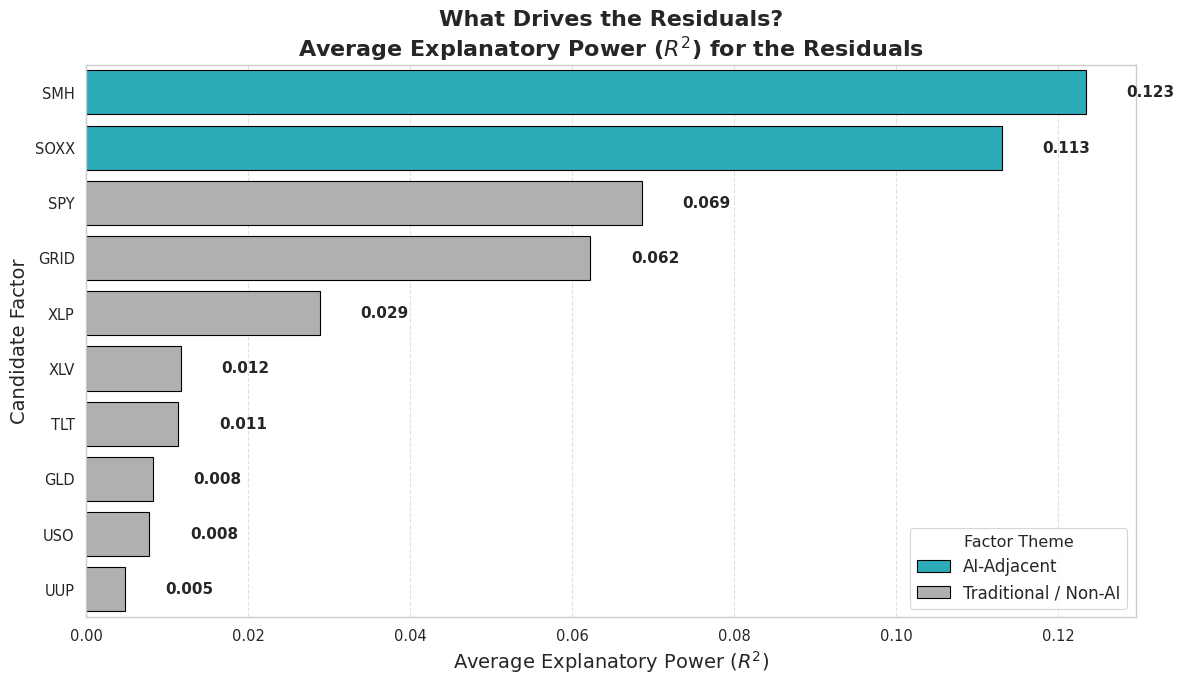

In [ ]:
# Define our two camps of factors based on your dataset
ai_factors = ['SMH', 'SOXX']
non_ai_factors =['SPY', 'GLD', 'TLT', 'UUP', 'USO', 'XLP', 'GRID', 'XLV']

# Ensure they exist in the test_data
all_candidates =  non_ai_factors + ai_factors
available_candidates = [f for f in all_candidates if f in test_data.columns]

print("Analyzing the explaining power of the following factors on the residuals:")
print(f"Candidates: {available_candidates}\n")

# Get the Top 10 most decoupled stocks to focus our analysis on the biggest breaks
if 'residual_volatility' not in locals():
    residual_volatility = post_break_residuals.std() * np.sqrt(252)

top_10_decoupled = residual_volatility.sort_values(ascending=False).head(10).index.tolist()

factor_results = []

# Perform univariate OLS: Residuals ~ Factor
for factor in available_candidates:
    X_factor = sm.add_constant(test_data[factor])
    r2_scores = []

    for stock in post_break_residuals  :
        y_resid = post_break_residuals[stock]

        # Fit OLS to see how well this single factor explains the stock's residual
        model = sm.OLS(y_resid, X_factor).fit()
        r2_scores.append(model.rsquared)

    # Average the explanatory power across the top 10 stocks
    avg_r2 = np.mean(r2_scores)
    factor_type = 'AI-Adjacent' if factor in ai_factors else 'Traditional / Non-AI'

    factor_results.append({
        'Factor': factor,
        'Average_R2': avg_r2,
        'Type': factor_type
    })

# Convert to DataFrame and sort by highest explaining value
driver_df = pd.DataFrame(factor_results).sort_values(by='Average_R2', ascending=False)

print("✅ Analysis Complete! Ranking factors by their ability to explain the residuals:")
display(driver_df)

# ==========================================
# VISUALIZATION: EXPLANATORY POWER RANKING
# ==========================================
plt.figure(figsize=(12, 7))

# Assign colors based on factor type
palette = {'AI-Adjacent': '#1f77b4', 'Traditional / Non-AI': '#gray'}
colors = [palette.get(x, '#gray') for x in driver_df['Type']]
if 'Traditional / Non-AI' in palette: # Fixing seaborn categorical color warning
    colors = ['#ff7f0e' if t == 'AI-Adjacent' else '#7f7f7f' for t in driver_df['Type']]

sns.barplot(
    data=driver_df,
    x='Average_R2',
    y='Factor',
    hue='Type',
    dodge=False,
    palette={'AI-Adjacent': '#17becf', 'Traditional / Non-AI': '#b0b0b0'},
    edgecolor='black'
)

plt.title('What Drives the Residuals?\nAverage Explanatory Power ($R^2$) for the Residuals', fontsize=16, fontweight='bold')
plt.xlabel('Average Explanatory Power ($R^2$)', fontsize=14)
plt.ylabel('Candidate Factor', fontsize=14)
plt.legend(title='Factor Theme', loc='lower right', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.6)

# Add data labels
for index, value in enumerate(driver_df['Average_R2']):
    plt.text(value + 0.005, index, f"{value:.3f}", va='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# STEPWISE SELECTION ON POST-BREAKPOINT RESIDUALS
# ==========================================
# We use the 'stepwise_selection' function defined in Cell 6 of your notebook.

# 1. Define the candidate factors (AI vs Unused Non-AI)
candidate_factors = ['SMH', 'SOXX', 'XLP', 'GRID']

# Ensure candidates are available in the test set
available_candidates = [f for f in candidate_factors if f in test_data.columns]
X_candidates = test_data[available_candidates]

print(f"Running Original Stepwise Selection on Post-Break Residuals.")
print(f"Candidate Factors: {available_candidates}\n")

# 2. Re-use the top decoupled stocks calculated previously
if 'residual_volatility' not in locals():
    residual_volatility = post_break_residuals.std() * np.sqrt(252)

top_n = 5
top_stocks = residual_volatility.sort_values(ascending=False).head(top_n).index.tolist()

selected_factors_tally = {factor: 0 for factor in available_candidates}

for stock in top_stocks:
    y_resid = post_break_residuals[stock].dropna()

    # Align indices to ensure no mismatched rows
    X_aligned, y_aligned = X_candidates.align(y_resid, join='inner', axis=0)

    print(f"\n=====================================")
    print(f" Analyzing Residuals for: {stock}")
    print(f"=====================================")

    # 3. Use your ORIGINAL stepwise function to select the best factors
    selected = stepwise_selection(
        X=X_aligned,
        y=y_aligned,
        target_stock=stock,
        threshold_in=0.10,
        threshold_out=0.15,
        show_model_params=True
    )

    # Tally the results
    for factor in selected:
        selected_factors_tally[factor] += 1

    if not selected:
        print(f"❌ No factors met the threshold to explain the residual for {stock}.")

# ==========================================
# SUMMARY OF SELECTED FACTORS
# ==========================================
print("\n======================================================")
print(f"🏆 FINAL TALLY: Factors Chosen by Stepwise Selection")
print(f"To explain the residuals for the top {top_n} decoupled stocks")
print("======================================================")

# Sort by most frequently selected
sorted_tally = sorted(selected_factors_tally.items(), key=lambda x: x[1], reverse=True)

for factor, count in sorted_tally:
    theme = "AI-Adjacent" if factor in ['SMH', 'SOXX'] else "Unused Non-AI"
    print(f"  - {factor:5} ({theme:13}): Selected {count} out of {top_n} times")

Running Original Stepwise Selection on Post-Break Residuals.
Candidate Factors: ['SMH', 'SOXX', 'XLP', 'GRID']


 Analyzing Residuals for: MOD
--- Training Phase: Stepwise Selection for MOD ---
Added  GRID  | p-value: 7.887600e-34
Added  XLP   | p-value: 6.662081e-07

 Analyzing Residuals for: INTC
--- Training Phase: Stepwise Selection for INTC ---
Added  SOXX  | p-value: 2.176011e-18
Added  SMH   | p-value: 2.513554e-08
Added  GRID  | p-value: 1.138063e-03

 Analyzing Residuals for: MRVL
--- Training Phase: Stepwise Selection for MRVL ---
Added  SOXX  | p-value: 8.690841e-53
Added  XLP   | p-value: 5.545549e-06
Added  SMH   | p-value: 2.305985e-02
Added  GRID  | p-value: 8.154488e-02

 Analyzing Residuals for: TSLA
--- Training Phase: Stepwise Selection for TSLA ---
Added  GRID  | p-value: 1.395717e-06

 Analyzing Residuals for: MU
--- Training Phase: Stepwise Selection for MU ---
Added  SOXX  | p-value: 1.234782e-38
Added  GRID  | p-value: 4.058841e-08
Added  XLP   | p-value: 1.3950

Modeling Residuals for: NVDA
Candidate Predictors: ['SMH', 'SOXX', 'XLP', 'GRID']

--- Training Phase: Stepwise Selection for NVDA_Residuals ---
Added  SMH   | p-value: 3.333933e-44
Added  SOXX  | p-value: 6.745124e-94
Added  GRID  | p-value: 2.115491e-33
Added  XLP   | p-value: 3.708345e-12

✅ Stepwise Selection chose: ['SMH', 'SOXX', 'GRID', 'XLP'] to explain the residuals.
📈 FINAL OLS MODEL SUMMARY FOR NVDA RESIDUALS
                            OLS Regression Results                            
Dep. Variable:                   NVDA   R-squared:                       0.652
Model:                            OLS   Adj. R-squared:                  0.650
Method:                 Least Squares   F-statistic:                     358.7
Date:                Wed, 10 Jun 2026   Prob (F-statistic):          5.84e-174
Time:                        09:48:44   Log-Likelihood:                 2243.4
No. Observations:                 772   AIC:                            -4477.
Df Residuals:          

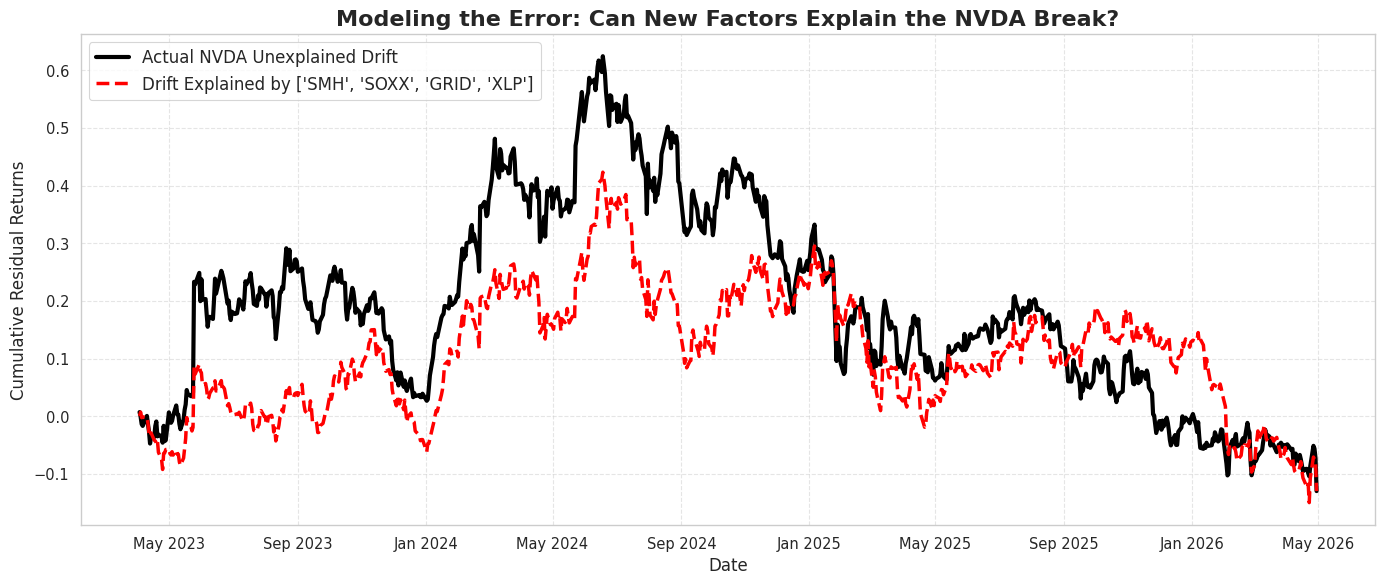

In [ ]:
# ==========================================
# APPLYING STEPWISE SELECTION TO RESIDUALS
# ==========================================
# We use your existing `stepwise_selection` function to see which factors
# are mathematically chosen to model the unexplained variance (residuals).

# Let's pick the stock that decoupled the hardest from our previous analysis
if 'top_stocks' in locals():
    target_stock = 'NVDA'
else:
    target_stock = 'NVDA' # Fallback

# Define our mixed candidate pool (AI vs Unused Non-AI)
candidate_factors = ['SMH', 'SOXX', 'XLP', 'GRID']
valid_candidates = [f for f in candidate_factors if f in test_data.columns]

print(f"Modeling Residuals for: {target_stock}")
print(f"Candidate Predictors: {valid_candidates}\n")

# Isolate the X (candidates) and y (residuals) for the Test Period
X_candidates = test_data[valid_candidates]
y_residuals = post_break_residuals[target_stock]

# ---------------------------------------------------------
# Run YOUR original stepwise selection function!
# ---------------------------------------------------------
final_resid_features = stepwise_selection(
    X=X_candidates,
    y=y_residuals,
    target_stock=f"{target_stock}_Residuals",
    threshold_in=0.10,
    threshold_out=0.15,
    show_model_params=True
)

if final_resid_features:
    print(f"\n✅ Stepwise Selection chose: {final_resid_features} to explain the residuals.")

    # Fit the final OLS model just like in `model_for_stock`
    X_final = sm.add_constant(X_candidates[final_resid_features])
    resid_model = sm.OLS(y_residuals, X_final).fit()

    print("======================================================")
    print(f"📈 FINAL OLS MODEL SUMMARY FOR {target_stock} RESIDUALS")
    print("======================================================")
    print(resid_model.summary())
    print("======================================================\n")

    # ---------------------------------------------------------
    # VISUALIZATION: Actual Drift vs Explained Drift
    # ---------------------------------------------------------
    y_resid_pred = resid_model.predict(X_final)

    plt.figure(figsize=(14, 6))

    # The actual unexplained error from the original model
    plt.plot(y_residuals.cumsum().index, y_residuals.cumsum(),
             label=f'Actual {target_stock} Unexplained Drift', color='black', linewidth=3)

    # The error that is now explained by the new factors
    plt.plot(y_resid_pred.cumsum().index, y_resid_pred.cumsum(),
             label=f'Drift Explained by {final_resid_features}', color='red', linestyle='--', linewidth=2.5)

    plt.title(f"Modeling the Error: Can New Factors Explain the {target_stock} Break?", fontsize=16, fontweight='bold')
    plt.xlabel('Date', fontsize=12)
    plt.ylabel('Cumulative Residual Returns', fontsize=12)
    plt.legend(loc='upper left', fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.5)

    # Format X-axis
    import matplotlib.dates as mdates
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

    plt.tight_layout()
    plt.show()
else:
    print(f"❌ None of the candidate factors met the threshold to explain {target_stock}'s residuals.")

# Új

Running stepwise selection on all 100 stocks...
Candidate Predictors for Residuals: ['SMH', 'SOXX', 'SPY', 'GLD', 'TLT', 'UUP', 'USO', 'XLP', 'GRID', 'XLV']

(Note: Stepwise progress headers will print, but detailed step logs are hidden for speed...)
--- Training Phase: Stepwise Selection for AAPL ---
--- Training Phase: Stepwise Selection for MSFT ---
--- Training Phase: Stepwise Selection for NVDA ---
--- Training Phase: Stepwise Selection for GOOGL ---
--- Training Phase: Stepwise Selection for AMZN ---
--- Training Phase: Stepwise Selection for META ---
--- Training Phase: Stepwise Selection for AVGO ---
--- Training Phase: Stepwise Selection for AMD ---
--- Training Phase: Stepwise Selection for INTC ---
--- Training Phase: Stepwise Selection for QCOM ---
--- Training Phase: Stepwise Selection for TSM ---
--- Training Phase: Stepwise Selection for ASML ---
--- Training Phase: Stepwise Selection for AMAT ---
--- Training Phase: Stepwise Selection for LRCX ---
--- Training Phase: St

/tmp/ipykernel_1586/1174559723.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


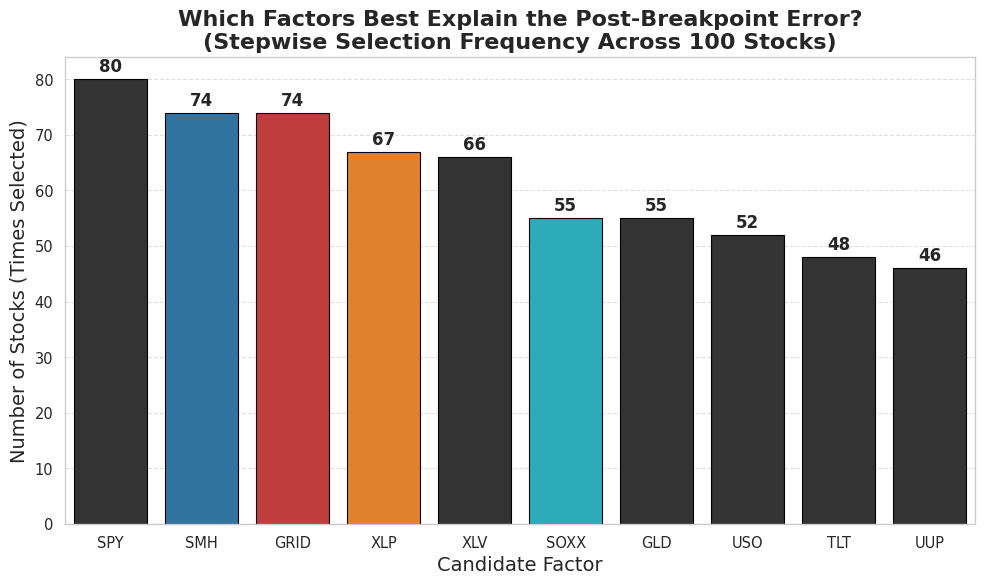


📋 Sample of Stock-by-Stock Selections:


,Stock,Selected_Factors
0,AAPL,"SMH, SOXX, GRID, SPY, UUP, GLD"
1,MSFT,"GRID, XLV, TLT, UUP, SPY, XLP, SOXX, SMH, USO"
2,NVDA,"SMH, SOXX, SPY, TLT, USO, XLV, GRID, UUP, GLD,..."
3,GOOGL,"XLP, GLD, TLT"
4,AMZN,"TLT, SPY, GRID, XLP, XLV, SMH, USO"
5,META,"XLP, SPY, GRID, SOXX, SMH, XLV, USO, TLT, UUP"
6,AVGO,"SMH, SPY, XLP"
7,AMD,"SOXX, SPY, GRID"
8,INTC,"SOXX, SPY, SMH, XLV"
9,QCOM,"SOXX, SPY, XLV, SMH, UUP, GLD, USO"


In [ ]:
# Define our mixed candidate pool
candidate_factors = ['SMH', 'SOXX', 'SPY', 'GLD', 'TLT', 'UUP', 'USO', 'XLP', 'GRID', 'XLV']
valid_candidates = [f for f in candidate_factors if f in test_data.columns]
X_candidates = test_data[valid_candidates]

print(f"Running stepwise selection on all {len(valid_targets)} stocks...")
print(f"Candidate Predictors for Residuals: {valid_candidates}\n")
print("(Note: Stepwise progress headers will print, but detailed step logs are hidden for speed...)")

# Dictionary to keep track of how many times each factor is chosen
selection_counts = {factor: 0 for factor in valid_candidates}
stocks_with_no_factors = 0

# We will also track exactly which factors were picked for which stock for a detailed view
detailed_results = []

# Run loop over ALL valid targets
for stock in valid_targets:
    y_residuals = post_break_residuals[stock]

    # Run stepwise selection silently (hides the feature-by-feature additions)
    selected_features = stepwise_selection(
        X=X_candidates,
        y=y_residuals,
        target_stock=stock,
        threshold_in=0.10,
        threshold_out=0.15,
        show_model_params=False
    )

    if selected_features:
        for feature in selected_features:
            selection_counts[feature] += 1
        detailed_results.append({'Stock': stock, 'Selected_Factors': ", ".join(selected_features)})
    else:
        stocks_with_no_factors += 1
        detailed_results.append({'Stock': stock, 'Selected_Factors': "None"})

print(f"\n✅ Scan Complete! {stocks_with_no_factors} stocks had residuals that could not be explained by these factors.")

# Convert results to DataFrame for easy viewing
counts_df = pd.DataFrame(list(selection_counts.items()), columns=['Factor', 'Times_Selected']).sort_values(by='Times_Selected', ascending=False)

# ==========================================
# VISUALIZATION: SELECTION FREQUENCY
# ==========================================
plt.figure(figsize=(10, 6))

# Assign distinct colors to easily separate AI vs Non-AI
palette = {'SMH': '#1f77b4', 'SOXX': '#17becf', 'XLP': '#ff7f0e', 'GRID': '#d62728'}
colors = [palette.get(f, '#333333') for f in counts_df['Factor']]

ax = sns.barplot(
    data=counts_df,
    x='Factor',
    y='Times_Selected',
    palette=colors,
    edgecolor='black'
)

plt.title(f'Which Factors Best Explain the Post-Breakpoint Error?\n(Stepwise Selection Frequency Across {len(valid_targets)} Stocks)', fontsize=16, fontweight='bold')
plt.xlabel('Candidate Factor', fontsize=14)
plt.ylabel('Number of Stocks (Times Selected)', fontsize=14)
plt.grid(axis='y', linestyle='--', alpha=0.6)

# Add numeric labels on top of the bars
for p in ax.patches:
    ax.annotate(format(p.get_height(), '.0f'),
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha = 'center', va = 'center',
                xytext = (0, 9),
                textcoords = 'offset points',
                fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

# Optional: Display the top 10 stocks and what was selected for them
print("\n📋 Sample of Stock-by-Stock Selections:")
display(pd.DataFrame(detailed_results).head(10))

In [ ]:
top_20_cumulative = post_break_residuals.sum().abs().sort_values(ascending=False).head(20)

print("Top 20 stocks by absolute cumulative residual:")
print(top_20_cumulative)

Top 20 stocks by absolute cumulative residual:
MOD     2.092108
STX     1.781787
ADBE    1.669929
NKE     1.646190
MU      1.358009
TSLA    1.258950
GE      1.241429
INTU    1.192059
NOW     1.157300
CRM     1.131528
AES     1.125143
FCX     0.956253
UPS     0.914814
SNPS    0.892295
CCI     0.868370
NEM     0.865668
AMD     0.775878
CDNS    0.775724
AVGO    0.775235
MSFT    0.765315
dtype: float64


In [ ]:
import json
import pandas as pd

# Az általad megadott JSON szöveg
json_text = """
{
  "project_name": "Factor Hunting for AI Equities",
  "industry_blocks": [
    {
      "name": "AI_Compute_and_Core_Semiconductors",
      "example_tickers": ["NVDA", "AMD", "AVGO", "ARM", "INTC", "QCOM", "MRVL", "MU", "MPWR", "ALAB", "CRDO"],
      "etf_proxies": ["SMH", "SOXX", "CHAT", "THNQ", "WTAI", "SOXQ"]
    },
    {
      "name": "Semiconductor_Equipment_and_Lithography",
      "example_tickers": ["ASML", "AMAT", "LRCX", "KLAC", "TER", "CAMT", "RMBS"],
      "etf_proxies": ["SMH", "SOXX", "SOXQ"]
    },
    {
      "name": "Foundries_Packaging_and_Memory",
      "example_tickers": ["TSM", "GFS", "UMC", "ASX", "MU", "AMKR"],
      "etf_proxies": ["SMH", "SOXX"]
    },
    {
      "name": "Networking_and_Optical_Interconnect",
      "example_tickers": ["ANET", "CSCO", "MRVL", "AVGO", "CIEN", "COHR", "LITE", "FN", "GLW"],
      "etf_proxies": ["IDGT"]
    },
    {
      "name": "Servers_and_System_Integrators",
      "example_tickers": ["SMCI", "DELL", "HPE", "IBM", "CLS"]
    },
    {
      "name": "Hyperscalers_and_AI_Platforms",
      "example_tickers": ["MSFT", "AMZN", "GOOGL", "META", "ORCL"],
      "etf_proxies": ["AIQ"]
    },
    {
      "name": "Data_Center_Owners_and_Digital_Infrastructure",
      "example_tickers": ["EQIX", "DLR", "IRM", "AMT", "GDS", "BIP", "CCI"],
      "etf_proxies": ["SRVR", "IDGT"]
    },
    {
      "name": "Power_Cooling_and_Electrical_Equipment",
      "example_tickers": ["VRT", "ETN", "ABB", "GEV", "JCI", "CARR", "TT", "GNRC", "MOD", "FIX", "EME"],
      "etf_proxies": ["GRID"]
    },
    {
      "name": "Utilities_and_Power_Producers",
      "example_tickers": ["NEE", "DUK", "SO", "EXC", "AEP", "CEG", "VST", "PEG", "AWK"],
      "etf_proxies": ["XLU", "UTES"]
    },
    {
      "name": "Grid_Capex_Transmission_and_Transformers",
      "example_tickers": ["PWR", "ETN", "ABB", "PRYMY", "NEXNY"],
      "etf_proxies": ["GRID"]
    },
    {
      "name": "Critical_Materials_and_Mining",
      "sub_blocks": [
        {"example_tickers": ["FCX", "SCCO", "TECK", "BHP", "RIO", "HBM"], "etf_proxies": ["COPX", "COPP", "COPA"]},
        {"example_tickers": ["CCJ", "UEC", "NXE"], "etf_proxies": ["URA", "URNM", "NUUR"]},
        {"example_tickers": ["ALB", "SQM"], "etf_proxies": ["LIT"]}
      ]
    },
    {
      "name": "Construction_and_Infrastructure_Buildout",
      "example_tickers": ["FLR", "ACM", "J", "MTZ", "PWR", "STRL"],
      "etf_proxies": ["PAVE"]
    },
    {
      "name": "Data_Management_Storage_and_Pipelines",
      "example_tickers": ["SNOW", "MDB", "PSTG", "NTAP", "WDC", "STX", "ESTC"],
      "etf_proxies": ["IGV"]
    },
    {
      "name": "AI_Software_and_Enterprise_Applications",
      "example_tickers": ["PLTR", "NOW", "CRM", "WDAY", "ADBE", "DDOG"],
      "etf_proxies": ["IGV", "SKYY", "QTUM", "IVES", "IGPT"]
    },
    {
      "name": "Cybersecurity_and_Model_Protection",
      "example_tickers": ["CRWD", "PANW", "ZS", "CYBR", "FTNT", "NET"],
      "etf_proxies": ["CIBR", "HACK", "BUG"]
    },
    {
      "name": "Edge_AI_and_Consumer_Hardware",
      "example_tickers": ["AAPL", "HPQ", "LNVGY", "QCOM", "INTC"]
    }
  ]
}
"""

# 1. JSON beolvasása és egy Ticker -> Szektor szótár (dictionary) létrehozása
sector_data = json.loads(json_text)
ticker_to_sector = {}

for block in sector_data["industry_blocks"]:
    sector_name = block["name"]

    # Ha közvetlen tickerek vannak
    if "example_tickers" in block:
        for ticker in block["example_tickers"]:
            ticker_to_sector[ticker] = sector_name

    # Ha alblokkok vannak (pl. a Critical_Materials_and_Mining esetében)
    if "sub_blocks" in block:
        for sub in block["sub_blocks"]:
            if "example_tickers" in sub:
                for ticker in sub["example_tickers"]:
                    ticker_to_sector[ticker] = sector_name

# 2. Legnagyobb eltérés kiszámítása
# (Itt az első módszert használjuk: összegezzük az eltéréseket, majd abszolút értéket vonunk)
deviations = post_break_residuals.sum().abs()

# Ha inkább minden napra az abszolút eltérést akarod összegezni, cseréld le a fenti sort erre:
# deviations = post_break_residuals.abs().sum()

# Csökkenő sorrend és a top 20 kiválasztása
top_20 = deviations.sort_values(ascending=False).head(20)

# 3. Végső táblázat összeállítása
results = []
for ticker, deviation in top_20.items():
    # Szektor kikeresése. Ha nincs a JSON-ben, "Egyéb / Ismeretlen" értéket kap.
    sector = ticker_to_sector.get(ticker, "Egyéb / Ismeretlen")

    results.append({
        "Ticker": ticker,
        "Szektor": sector,
        "Összesített Eltérés (Abszolút)": deviation
    })

# Formázás DataFrame-be és kiíratás
top_20_df = pd.DataFrame(results)

print("A TOP 20 CÉG A LEGNAGYOBB MODELL ELTÉRÉSSEL:")
print("-" * 60)
top_20_df

A TOP 20 CÉG A LEGNAGYOBB MODELL ELTÉRÉSSEL:
------------------------------------------------------------


,Ticker,Szektor,Összesített Eltérés (Abszolút)
0,MOD,Power_Cooling_and_Electrical_Equipment,2.092108
1,STX,Data_Management_Storage_and_Pipelines,1.781787
2,ADBE,AI_Software_and_Enterprise_Applications,1.669929
3,NKE,Egyéb / Ismeretlen,1.646190
4,MU,Foundries_Packaging_and_Memory,1.358009
5,TSLA,Egyéb / Ismeretlen,1.258950
6,GE,Egyéb / Ismeretlen,1.241429
7,INTU,Egyéb / Ismeretlen,1.192059
8,NOW,AI_Software_and_Enterprise_Applications,1.157300
9,CRM,AI_Software_and_Enterprise_Applications,1.131528


In [ ]:
# ==========================================
# INDIVIDUAL RESIDUAL DRIVER ANALYSIS (TOP 20 STOCKS)
# ==========================================
import statsmodels.api as sm
import pandas as pd
import numpy as np

# Define our two camps of factors based on your dataset
ai_factors = ['SMH', 'SOXX']
non_ai_factors = ['SPY', 'GLD', 'TLT', 'UUP', 'USO', 'XLP', 'GRID', 'XLV']

# Ensure they exist in the test_data
all_candidates = non_ai_factors + ai_factors
available_candidates = [f for f in all_candidates if f in test_data.columns]

print("Analyzing the best individual explaining factor from the following candidates:")
print(f"Candidates: {available_candidates}\n")

# 1. Identify the Top 20 most decoupled stocks (using residual volatility)
if 'residual_volatility' not in locals():
    residual_volatility = post_break_residuals.std() * np.sqrt(252)

top_20_stocks = residual_volatility.sort_values(ascending=False).head(20).index.tolist()

results = []

print("Kiszámítjuk a legjobb magyarázó faktort minden egyes Top 20 részvényre...\n")

# 2. Iterate through each of the Top 20 stocks
for stock in top_20_stocks:
    y_resid = post_break_residuals[stock]

    best_factor = "None"
    best_r2 = -1

    # 3. Test each candidate factor individually to find the best fit
    for factor in available_candidates:
        X_factor = sm.add_constant(test_data[factor])
        model = sm.OLS(y_resid, X_factor).fit()

        # If this factor has a higher R-squared, it becomes the new best factor
        if model.rsquared > best_r2:
            best_r2 = model.rsquared
            best_factor = factor

    # Determine the theme of the winning factor
    factor_type = 'AI-Adjacent' if best_factor in ai_factors else 'Traditional / Non-AI'

    # Store the results
    results.append({
        'Ticker': stock,
        'Legjobb Faktor (Best Factor)': best_factor,
        'Magyarázó Erő (R²)': f"{best_r2 * 100:.2f}%",
        'Faktor Típusa (Theme)': factor_type
    })

# 4. Convert to DataFrame and display
top_20_drivers_df = pd.DataFrame(results)

print("✅ A TOP 20 CÉG EGYEDI FAKTOR-ELEMZÉSE (Legjobb illeszkedés alapján):")
print("-" * 80)
display(top_20_drivers_df)

Analyzing the best individual explaining factor from the following candidates:
Candidates: ['SPY', 'GLD', 'TLT', 'UUP', 'USO', 'XLP', 'GRID', 'XLV', 'SMH', 'SOXX']

Kiszámítjuk a legjobb magyarázó faktort minden egyes Top 20 részvényre...

✅ A TOP 20 CÉG EGYEDI FAKTOR-ELEMZÉSE (Legjobb illeszkedés alapján):
--------------------------------------------------------------------------------


,Ticker,Legjobb Faktor (Best Factor),Magyarázó Erő (R²),Faktor Típusa (Theme)
0,MOD,GRID,17.39%,Traditional / Non-AI
1,INTC,SOXX,9.47%,AI-Adjacent
2,MRVL,SOXX,26.20%,AI-Adjacent
3,TSLA,SPY,3.64%,Traditional / Non-AI
4,MU,SOXX,19.72%,AI-Adjacent
5,AMD,SOXX,20.41%,AI-Adjacent
6,ANET,SMH,16.77%,AI-Adjacent
7,STX,SOXX,7.13%,AI-Adjacent
8,ORCL,GRID,5.58%,Traditional / Non-AI
9,SNPS,SMH,7.06%,AI-Adjacent


In [ ]:

# ==========================================
# CÉGNEVEK ÉS SZEKTOROK HOZZÁADÁSA A TOP 20 TÁBLÁZATHOZ
# ==========================================
import yfinance as yf
import pandas as pd

print("⏳ Cégnevek lekérése a Yahoo Finance-ről (ez eltarthat néhány másodpercig)...")

company_names = []
sectors = []

# Végigmegyünk a már kiszámolt Top 20 táblázat tickerein
for ticker in top_20_drivers_df['Ticker']:

    # 1. Szektor kikeresése a korábban megírt JSON alapú szótárból (ticker_to_sector)
    sector = ticker_to_sector.get(ticker, "Egyéb / Ismeretlen")
    sectors.append(sector)

    # 2. Valós cégnév lekérése a yfinance segítségével
    try:
        # Lekérjük a cég adatait (ha a 'shortName' nem elérhető, megpróbálja a 'longName'-t)
        stock_data = yf.Ticker(ticker).info
        name = stock_data.get('shortName', stock_data.get('longName', ticker))
        company_names.append(name)
    except Exception as e:
        # Ha valamiért nem sikerül lekérni (pl. hálózati hiba), berakjuk a tickert névként
        company_names.append(ticker)

# Hozzáadjuk az új oszlopokat a DataFrame-hez
top_20_drivers_df['Company Name'] = company_names
top_20_drivers_df['Sector / Industry'] = sectors

# Átrendezzük az oszlopokat, hogy a logikus sorrendben jelenjenek meg (Név és Szektor előre kerüljön)
final_columns = [
    'Ticker',
    'Company Name',
    'Sector / Industry',
    'Legjobb Faktor (Best Factor)',
    'Magyarázó Erő (R²)',
    'Faktor Típusa (Theme)',
    'Legnagyobb Eltérés Dátuma (Max Dev Date)'
]

# Létrehozzuk a végső, formázott táblázatot
final_top_20_df = top_20_drivers_df[final_columns].copy()

print("✅ Táblázat sikeresen összeállítva a valós adataiddal!\n")
display(final_top_20_df)

⏳ Cégnevek lekérése a Yahoo Finance-ről (ez eltarthat néhány másodpercig)...
✅ Táblázat sikeresen összeállítva a valós adataiddal!



,Ticker,Company Name,Sector / Industry,Legjobb Faktor (Best Factor),Magyarázó Erő (R²),Faktor Típusa (Theme),Legnagyobb Eltérés Dátuma (Max Dev Date)
0,MOD,Modine Manufacturing Company,Power_Cooling_and_Electrical_Equipment,GRID,17.39%,Traditional / Non-AI,2025-01-27
1,INTC,Intel Corporation,Edge_AI_and_Consumer_Hardware,SOXX,9.47%,AI-Adjacent,2024-08-02
2,MRVL,"Marvell Technology, Inc.",Networking_and_Optical_Interconnect,SOXX,26.20%,AI-Adjacent,2023-05-26
3,TSLA,"Tesla, Inc.",Egyéb / Ismeretlen,SPY,3.64%,Traditional / Non-AI,2024-10-24
4,MU,"Micron Technology, Inc.",Foundries_Packaging_and_Memory,SOXX,19.72%,AI-Adjacent,2024-12-19
5,AMD,"Advanced Micro Devices, Inc.",AI_Compute_and_Core_Semiconductors,SOXX,20.41%,AI-Adjacent,2025-10-06
6,ANET,"Arista Networks, Inc.",Networking_and_Optical_Interconnect,SMH,16.77%,AI-Adjacent,2025-01-27
7,STX,Seagate Technology Holdings PLC,Data_Management_Storage_and_Pipelines,SOXX,7.13%,AI-Adjacent,2026-01-28
8,ORCL,Oracle Corporation,Hyperscalers_and_AI_Platforms,GRID,5.58%,Traditional / Non-AI,2025-09-10
9,SNPS,"Synopsys, Inc.",Egyéb / Ismeretlen,SMH,7.06%,AI-Adjacent,2025-09-10


⏳ ÉLŐ SZÁMÍTÁS: A Top 20 legjobban eltérő részvény elemzése...
✅ Sikeresen azonosítottuk a 3 legerősebben AI-vezérelt részvényt: ['MRVL', 'LRCX', 'AVGO', 'NVDA', 'AMD', 'MU', 'ANET', 'INTC', 'STX', 'SNPS']


🔍 MÉLYELEMZÉS: MRVL
--------------------------------------------------
--- Training Phase: Stepwise Selection for MRVL_Resid ---
Added  SOXX  | p-value: 8.690841e-53
Added  SPY   | p-value: 2.059994e-13
Added  USO   | p-value: 1.797889e-02

✅ Végső faktorok: ['SOXX', 'SPY', 'USO']
--- OLS ÖSSZEFOGLALÓ ---


,Koefficiens,P-érték,Szignifikáns?
const,-0.000561,5.490468e-01,False
SOXX,1.160662,4.092082e-51,True
SPY,-1.266619,9.077120e-14,True
USO,0.103200,1.797889e-02,True


Modell Magyarázó Ereje (R²): 31.71%



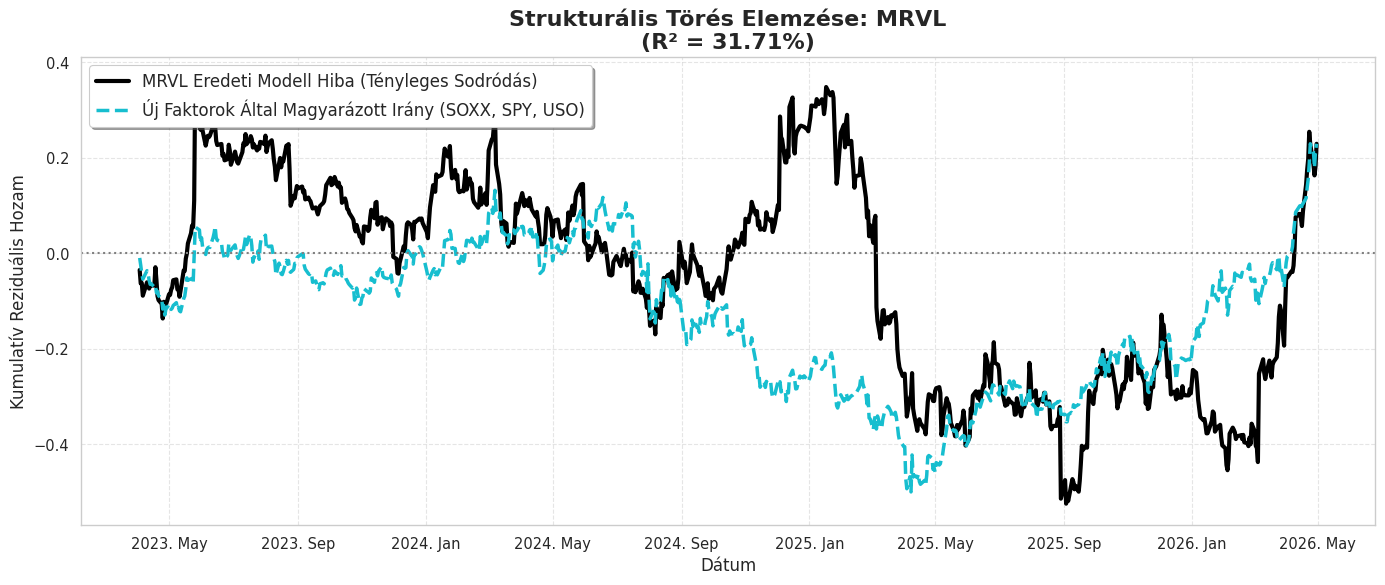


▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰


🔍 MÉLYELEMZÉS: LRCX
--------------------------------------------------
--- Training Phase: Stepwise Selection for LRCX_Resid ---
Added  SOXX  | p-value: 3.780772e-51
Added  SPY   | p-value: 5.363768e-82
Added  XLV   | p-value: 7.120963e-15
Added  SMH   | p-value: 1.182901e-02
Added  TLT   | p-value: 6.865758e-02

✅ Végső faktorok: ['SOXX', 'SPY', 'XLV', 'SMH', 'TLT']
--- OLS ÖSSZEFOGLALÓ ---


,Koefficiens,P-érték,Szignifikáns?
const,0.000076,8.765707e-01,False
SOXX,0.991955,2.104433e-17,True
SPY,-2.501030,2.158315e-89,True
XLV,0.625382,8.084503e-17,True
SMH,0.296607,1.460225e-02,True
TLT,-0.102413,6.865758e-02,False


Modell Magyarázó Ereje (R²): 57.87%



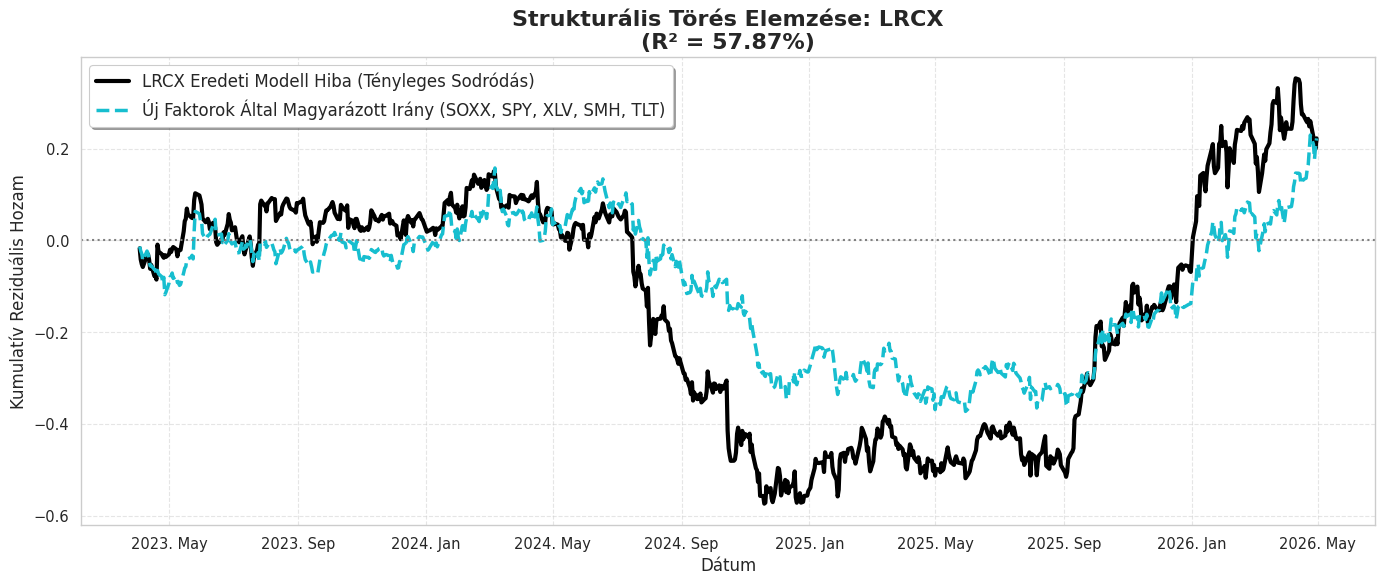


▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰


🔍 MÉLYELEMZÉS: AVGO
--------------------------------------------------
--- Training Phase: Stepwise Selection for AVGO_Resid ---
Added  SMH   | p-value: 9.149944e-50
Added  SPY   | p-value: 6.548906e-31
Added  XLP   | p-value: 2.886604e-02

✅ Végső faktorok: ['SMH', 'SPY', 'XLP']
--- OLS ÖSSZEFOGLALÓ ---


,Koefficiens,P-érték,Szignifikáns?
const,0.000288,6.681075e-01,False
SMH,1.005754,3.424312e-54,True
SPY,-1.280710,3.302048e-18,True
XLP,-0.230582,2.886604e-02,True


Modell Magyarázó Ereje (R²): 37.25%



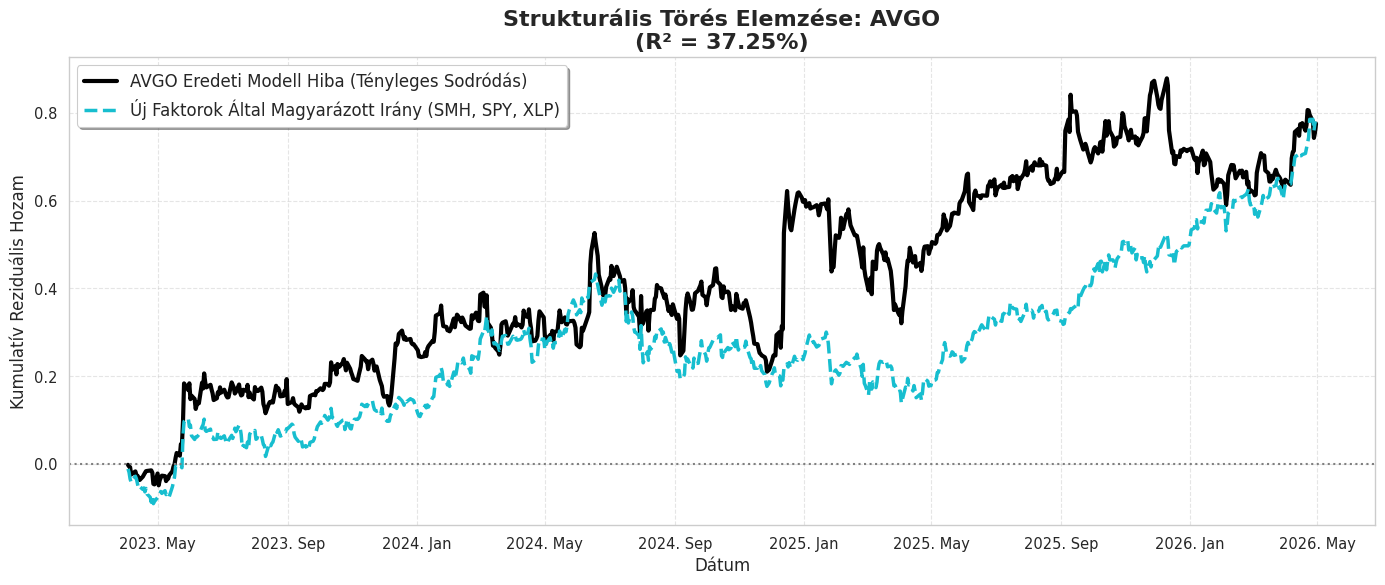


▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰


🔍 MÉLYELEMZÉS: NVDA
--------------------------------------------------
--- Training Phase: Stepwise Selection for NVDA_Resid ---
Added  SMH   | p-value: 3.333933e-44
Added  SOXX  | p-value: 6.745124e-94
Added  SPY   | p-value: 5.457358e-82
Added  TLT   | p-value: 3.083493e-05
Added  USO   | p-value: 1.226010e-03
Added  XLV   | p-value: 8.068075e-04
Added  GRID  | p-value: 1.212612e-02
Added  UUP   | p-value: 3.991971e-04
Added  GLD   | p-value: 6.713702e-02
Added  XLP   | p-value: 9.008307e-02

✅ Végső faktorok: ['SMH', 'SOXX', 'SPY', 'TLT', 'USO', 'XLV', 'GRID', 'UUP', 'GLD', 'XLP']
--- OLS ÖSSZEFOGLALÓ ---


,Koefficiens,P-érték,Szignifikáns?
const,-0.001465,4.600191e-04,True
SMH,3.822215,1.432030e-168,True
SOXX,-2.647273,6.048439e-114,True
SPY,-1.581988,7.959989e-41,True
TLT,-0.209774,3.135110e-05,True
USO,0.078731,1.022568e-04,True
XLV,0.235371,3.999408e-04,True
GRID,-0.248005,7.315060e-04,True
UUP,-0.483241,4.800620e-05,True
GLD,-0.066430,7.430946e-02,False


Modell Magyarázó Ereje (R²): 74.48%



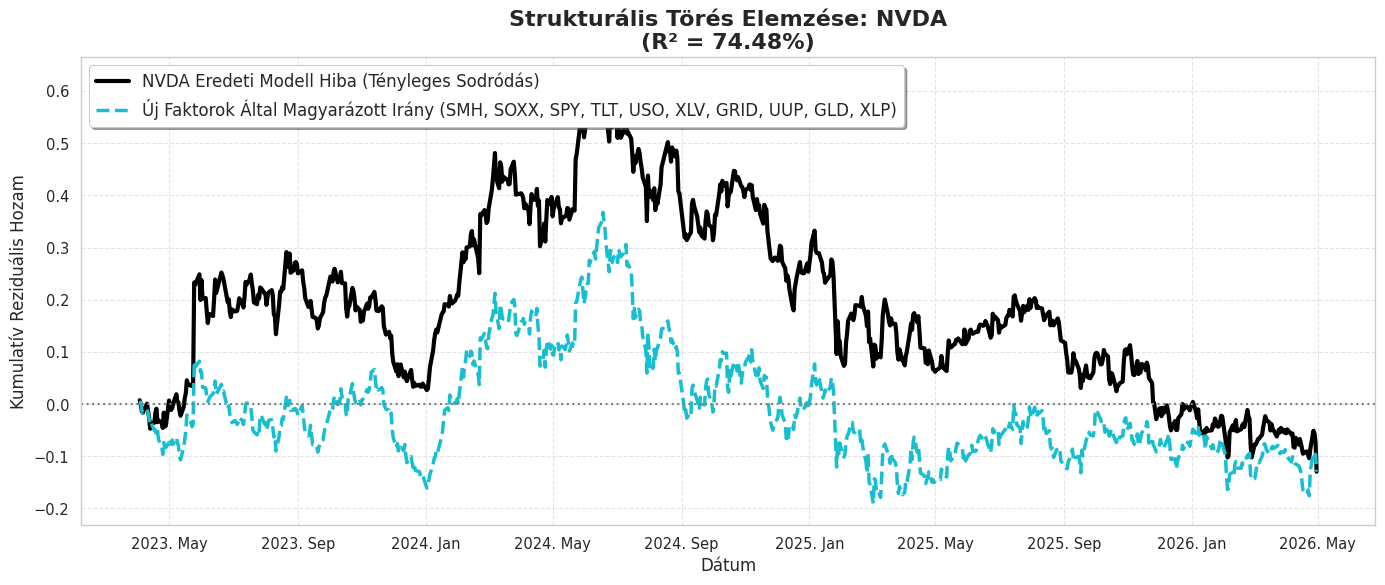


▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰


🔍 MÉLYELEMZÉS: AMD
--------------------------------------------------
--- Training Phase: Stepwise Selection for AMD_Resid ---
Added  SOXX  | p-value: 4.280748e-40
Added  SPY   | p-value: 1.996505e-31
Added  GRID  | p-value: 7.003504e-02

✅ Végső faktorok: ['SOXX', 'SPY', 'GRID']
--- OLS ÖSSZEFOGLALÓ ---


,Koefficiens,P-érték,Szignifikáns?
const,-0.001365,8.807610e-02,False
SOXX,1.198741,7.440688e-63,True
SPY,-1.573766,1.470125e-19,True
GRID,-0.230132,7.003504e-02,False


Modell Magyarázó Ereje (R²): 33.60%



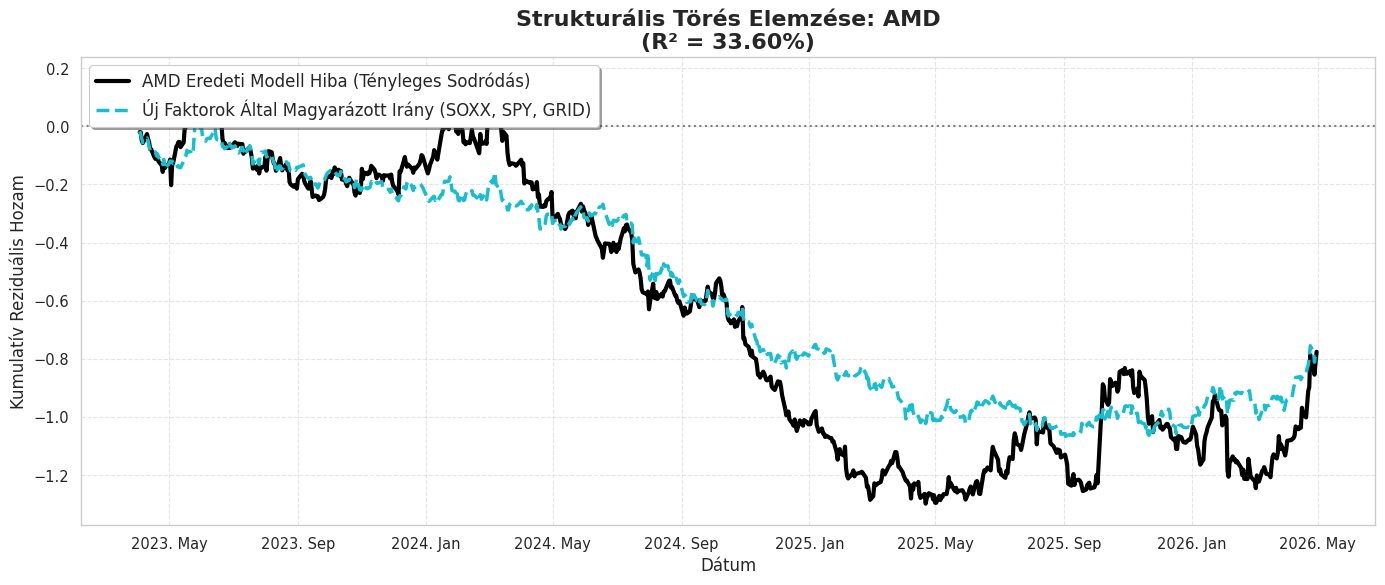


▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰


🔍 MÉLYELEMZÉS: MU
--------------------------------------------------
--- Training Phase: Stepwise Selection for MU_Resid ---
Added  SOXX  | p-value: 1.234782e-38
Added  SPY   | p-value: 1.167779e-34
Added  XLV   | p-value: 7.757383e-06
Added  SMH   | p-value: 1.360822e-02
Added  USO   | p-value: 5.818470e-02
Added  GLD   | p-value: 9.330281e-02

✅ Végső faktorok: ['SOXX', 'SPY', 'XLV', 'SMH', 'USO', 'GLD']
--- OLS ÖSSZEFOGLALÓ ---


,Koefficiens,P-érték,Szignifikáns?
const,0.001179,1.449110e-01,False
SOXX,0.830874,1.030452e-05,True
SPY,-2.460934,2.253855e-38,True
XLV,0.623576,3.906564e-07,True
SMH,0.525418,8.299134e-03,True
USO,0.065703,8.646082e-02,False
GLD,0.110172,9.330281e-02,False


Modell Magyarázó Ereje (R²): 36.76%



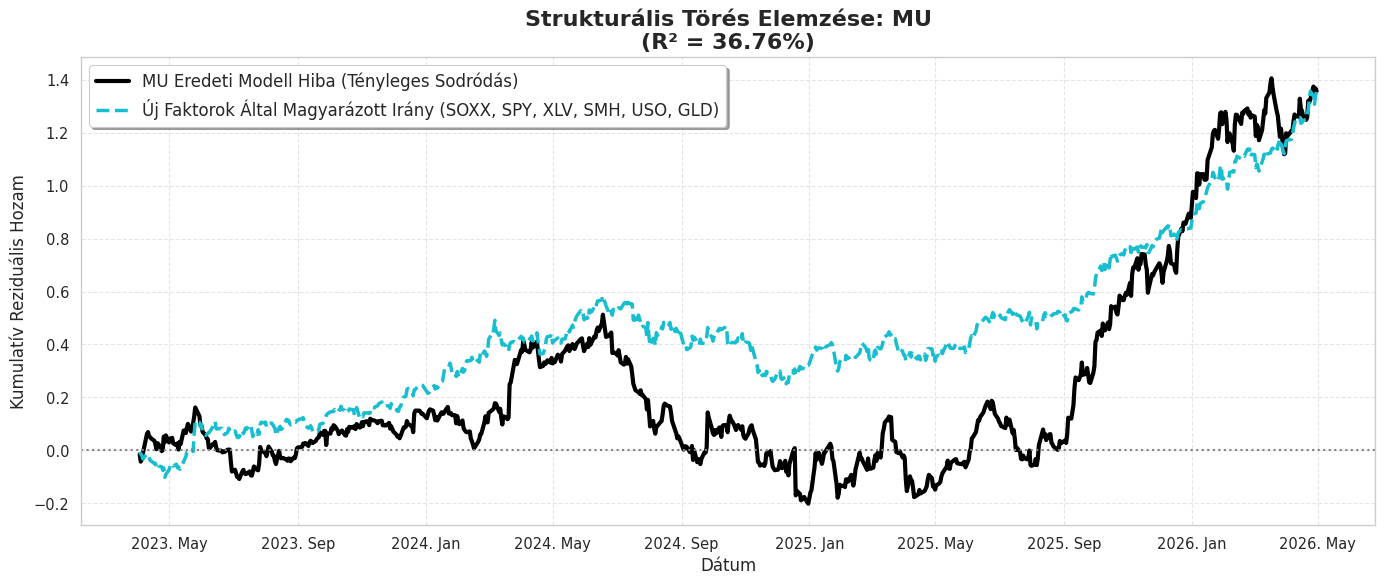


▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰


🔍 MÉLYELEMZÉS: ANET
--------------------------------------------------
--- Training Phase: Stepwise Selection for ANET_Resid ---
Added  SMH   | p-value: 1.401628e-32
Added  XLP   | p-value: 1.832375e-10
Added  XLV   | p-value: 1.010461e-03
Added  GRID  | p-value: 1.195337e-03
Added  SOXX  | p-value: 6.644606e-03
Added  TLT   | p-value: 3.651684e-02

✅ Végső faktorok: ['SMH', 'XLP', 'XLV', 'GRID', 'SOXX', 'TLT']
--- OLS ÖSSZEFOGLALÓ ---


,Koefficiens,P-érték,Szignifikáns?
const,-0.000461,0.590434,False
SMH,0.916771,0.000012,True
XLP,-0.544967,0.000120,True
XLV,-0.430172,0.000600,True
GRID,0.482036,0.000145,True
SOXX,-0.553320,0.005986,True
TLT,-0.208107,0.036517,True


Modell Magyarázó Ereje (R²): 24.39%



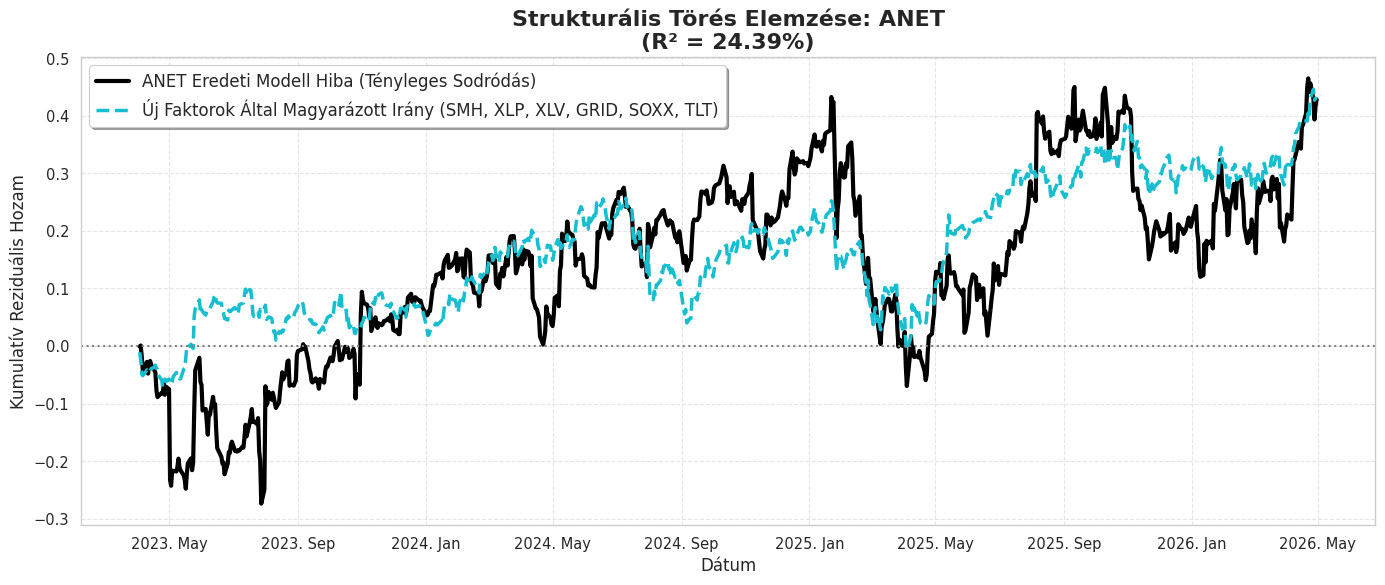


▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰


🔍 MÉLYELEMZÉS: INTC
--------------------------------------------------
--- Training Phase: Stepwise Selection for INTC_Resid ---
Added  SOXX  | p-value: 2.176011e-18
Added  SPY   | p-value: 1.310890e-09
Added  SMH   | p-value: 1.498956e-06
Added  XLV   | p-value: 9.071570e-03

✅ Végső faktorok: ['SOXX', 'SPY', 'SMH', 'XLV']
--- OLS ÖSSZEFOGLALÓ ---


,Koefficiens,P-érték,Szignifikáns?
const,0.000569,5.966470e-01,False
SOXX,1.907752,5.808435e-14,True
SPY,-1.411552,3.922228e-09,True
SMH,-1.066188,6.104358e-05,True
XLV,0.415892,9.071570e-03,True


Modell Magyarázó Ereje (R²): 17.00%



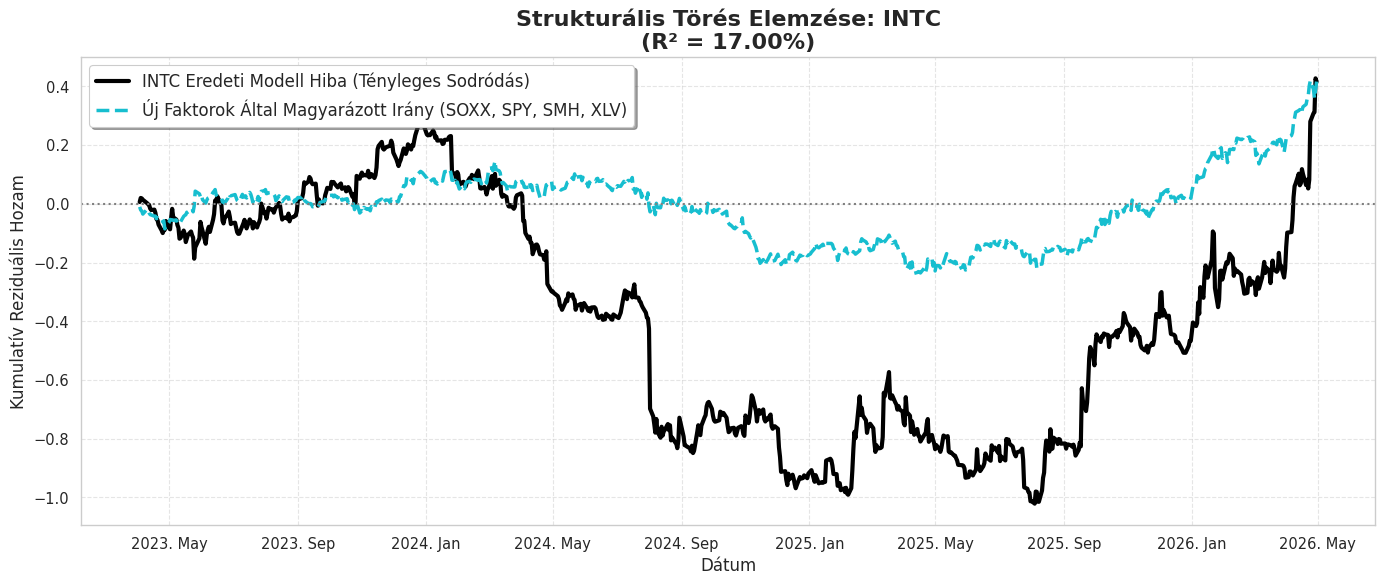


▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰


🔍 MÉLYELEMZÉS: STX
--------------------------------------------------
--- Training Phase: Stepwise Selection for STX_Resid ---
Added  SOXX  | p-value: 4.550855e-14
Added  SPY   | p-value: 2.097347e-08
Added  SMH   | p-value: 6.399818e-05
Added  GLD   | p-value: 5.919138e-03
Added  XLV   | p-value: 2.852949e-02

✅ Végső faktorok: ['SOXX', 'SPY', 'SMH', 'GLD', 'XLV']
--- OLS ÖSSZEFOGLALÓ ---


,Koefficiens,P-érték,Szignifikáns?
const,0.002156,1.298462e-02,True
SOXX,1.268512,4.250769e-10,True
SPY,-1.036571,6.878444e-08,True
SMH,-0.680516,1.412802e-03,True
GLD,0.182132,9.364360e-03,True
XLV,0.280665,2.852949e-02,True


Modell Magyarázó Ereje (R²): 14.08%



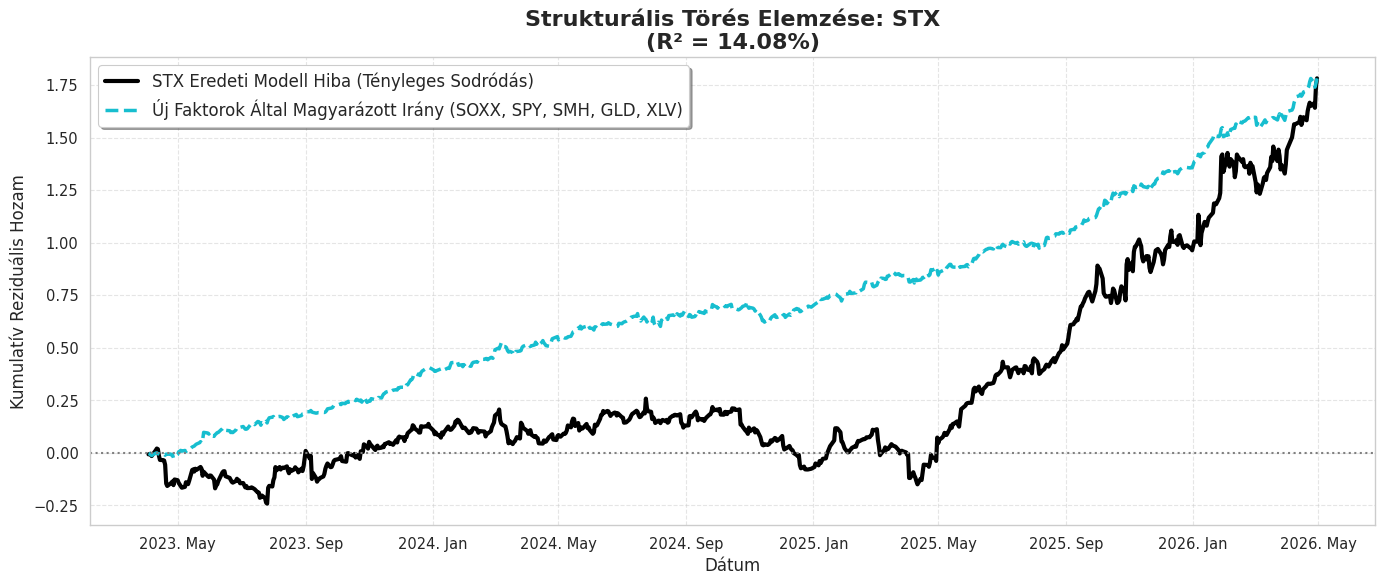


▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰


🔍 MÉLYELEMZÉS: SNPS
--------------------------------------------------
--- Training Phase: Stepwise Selection for SNPS_Resid ---
Added  SMH   | p-value: 6.099197e-14
Added  GRID  | p-value: 1.742236e-10
Added  SOXX  | p-value: 8.978756e-07
Added  TLT   | p-value: 3.982109e-02
Added  UUP   | p-value: 6.969921e-02
Added  XLV   | p-value: 6.652428e-02
Added  SPY   | p-value: 6.747661e-02
Dropped UUP   | p-value: 1.556386e-01

✅ Végső faktorok: ['SMH', 'GRID', 'SOXX', 'TLT', 'XLV', 'SPY']
--- OLS ÖSSZEFOGLALÓ ---


,Koefficiens,P-érték,Szignifikáns?
const,-0.001900,2.263713e-02,True
SMH,1.688798,7.018967e-16,True
GRID,-0.493096,2.392739e-04,True
SOXX,-1.019937,2.037339e-07,True
TLT,-0.223121,2.079011e-02,True
XLV,0.327154,8.474541e-03,True
SPY,-0.456835,2.662020e-02,True


Modell Magyarázó Ereje (R²): 15.94%



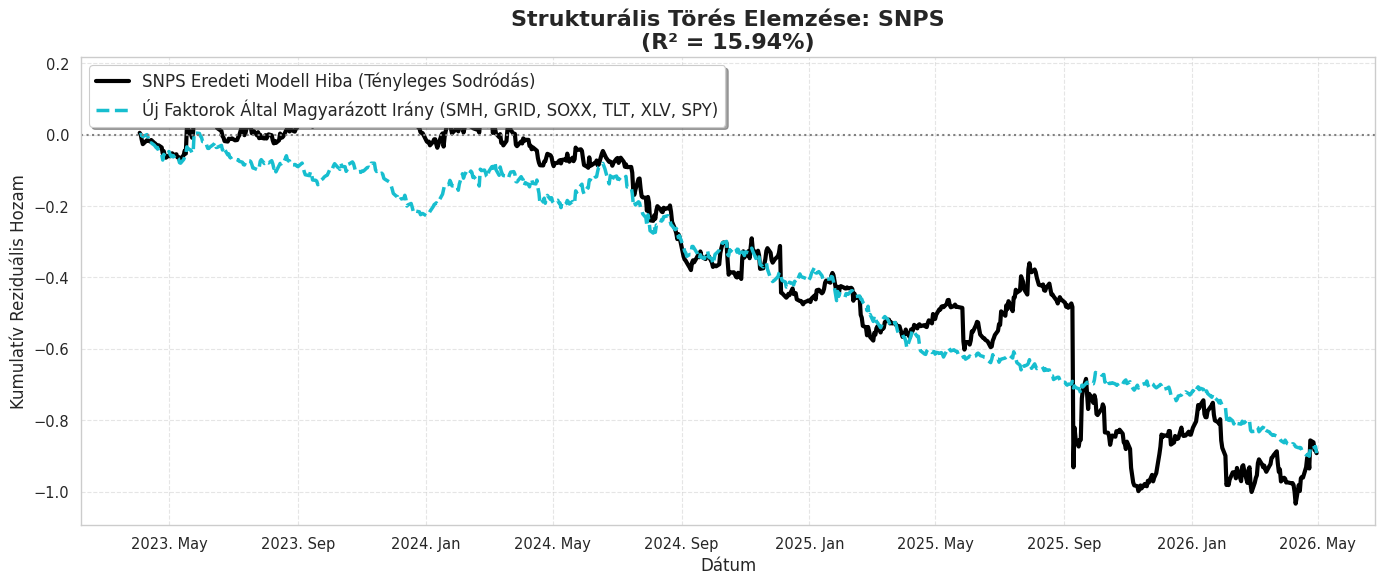


▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰▰



In [ ]:
# ==========================================
# 1. ÉLŐ TOP 20 AI-FAKTOR SZÁMÍTÁS ÉS KIVÁLASZTÁS
# ==========================================
import statsmodels.api as sm
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Faktor kandidátusok beállítása
ai_factors = ['SMH', 'SOXX']
non_ai_factors = ['SPY', 'GLD', 'TLT', 'UUP', 'USO', 'XLP', 'GRID', 'XLV']
all_candidates = non_ai_factors + ai_factors
valid_candidates = [f for f in all_candidates if f in test_data.columns]

print("⏳ ÉLŐ SZÁMÍTÁS: A Top 20 legjobban eltérő részvény elemzése...")

# Legnagyobb eltérésű (volatilitású) 20 részvény kiválasztása
residual_volatility = post_break_residuals.std() * np.sqrt(252)
top_20_stocks = residual_volatility.sort_values(ascending=False).head(20).index.tolist()

results = []

# Végigmegyünk a Top 20-on, és élőben kiszámoljuk a legjobb OLS illeszkedést
for stock in top_20_stocks:
    y_resid = post_break_residuals[stock]
    best_factor = "None"
    best_r2 = -1

    for factor in valid_candidates:
        X_factor = sm.add_constant(test_data[factor])
        model = sm.OLS(y_resid, X_factor).fit()

        if model.rsquared > best_r2:
            best_r2 = model.rsquared
            best_factor = factor

    theme = 'AI-Adjacent' if best_factor in ai_factors else 'Traditional / Non-AI'
    results.append({'Ticker': stock, 'Best_Factor': best_factor, 'R2': best_r2, 'Theme': theme})

# DataFrame-be rakjuk az élő eredményeket
live_top_20_df = pd.DataFrame(results)

# Kiszűrjük azokat, ahol az AI ETF a legjobb, majd R2 alapján csökkenőbe rendezzük
ai_driven = live_top_20_df[live_top_20_df['Theme'] == 'AI-Adjacent']
top_ai_stocks = ai_driven.sort_values(by='R2', ascending=False).head(10)['Ticker'].tolist()

print(f"✅ Sikeresen azonosítottuk a 3 legerősebben AI-vezérelt részvényt: {top_ai_stocks}\n")
print("=" * 80)

# ==========================================
# 2. MÉLYELEMZÉS ÉS VIZUALIZÁCIÓ FÜGGVÉNY (A TE STEPWISE KÓDODDAL)
# ==========================================
def analyze_residual_for_stock(ticker):
    print(f"\n🔍 MÉLYELEMZÉS: {ticker}")
    print("-" * 50)

    y_residuals = post_break_residuals[ticker]
    X_candidates = test_data[valid_candidates]

    # Lefuttatjuk a TE stepwise függvényedet!
    selected_features = stepwise_selection(
        X=X_candidates,
        y=y_residuals,
        target_stock=f"{ticker}_Resid",
        threshold_in=0.10,
        threshold_out=0.15,
        show_model_params=True
    )

    if not selected_features:
        print(f"⚠️ Nem található szignifikáns faktor a(z) {ticker} számára.")
        return

    print(f"\n✅ Végső faktorok: {selected_features}")

    # Végső modell illesztése
    X_final = sm.add_constant(X_candidates[selected_features])
    resid_model = sm.OLS(y_residuals, X_final).fit()

    print("--- OLS ÖSSZEFOGLALÓ ---")
    summary_df = pd.DataFrame({
        'Koefficiens': resid_model.params,
        'P-érték': resid_model.pvalues
    })
    summary_df['Szignifikáns?'] = summary_df['P-érték'] < 0.05
    display(summary_df)
    print(f"Modell Magyarázó Ereje (R²): {resid_model.rsquared * 100:.2f}%\n")

    # Vizualizáció
    y_resid_pred = resid_model.predict(X_final)
    plt.figure(figsize=(14, 6))

    cum_actual_resid = y_residuals.cumsum()
    plt.plot(cum_actual_resid.index, cum_actual_resid,
             label=f'{ticker} Eredeti Modell Hiba (Tényleges Sodródás)', color='black', linewidth=3)

    cum_pred_resid = y_resid_pred.cumsum()
    line_color = '#17becf' if any(f in selected_features for f in ai_factors) else '#ff7f0e'

    plt.plot(cum_pred_resid.index, cum_pred_resid,
             label=f'Új Faktorok Által Magyarázott Irány ({", ".join(selected_features)})',
             color=line_color, linestyle='--', linewidth=2.5)

    plt.title(f"Strukturális Törés Elemzése: {ticker}\n(R² = {resid_model.rsquared * 100:.2f}%)", fontsize=16, fontweight='bold')
    plt.xlabel('Dátum', fontsize=12)
    plt.ylabel('Kumulatív Reziduális Hozam', fontsize=12)
    plt.axhline(0, color='gray', linestyle=':', linewidth=1.5)
    plt.legend(loc='upper left', fontsize=12, frameon=True, shadow=True)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y. %b'))
    plt.tight_layout()
    plt.show()

# ==========================================
# 3. FUTTATÁS A KIVÁLASZTOTT RÉSZVÉNYEKRE
# ==========================================
for ticker in top_ai_stocks:
    analyze_residual_for_stock(ticker)
    print("\n" + "▰" * 80 + "\n")


📊 SCATTERPLOT: MRVL (Napi hibák magyarázata)
--------------------------------------------------
--- Training Phase: Stepwise Selection for MRVL_Resid ---


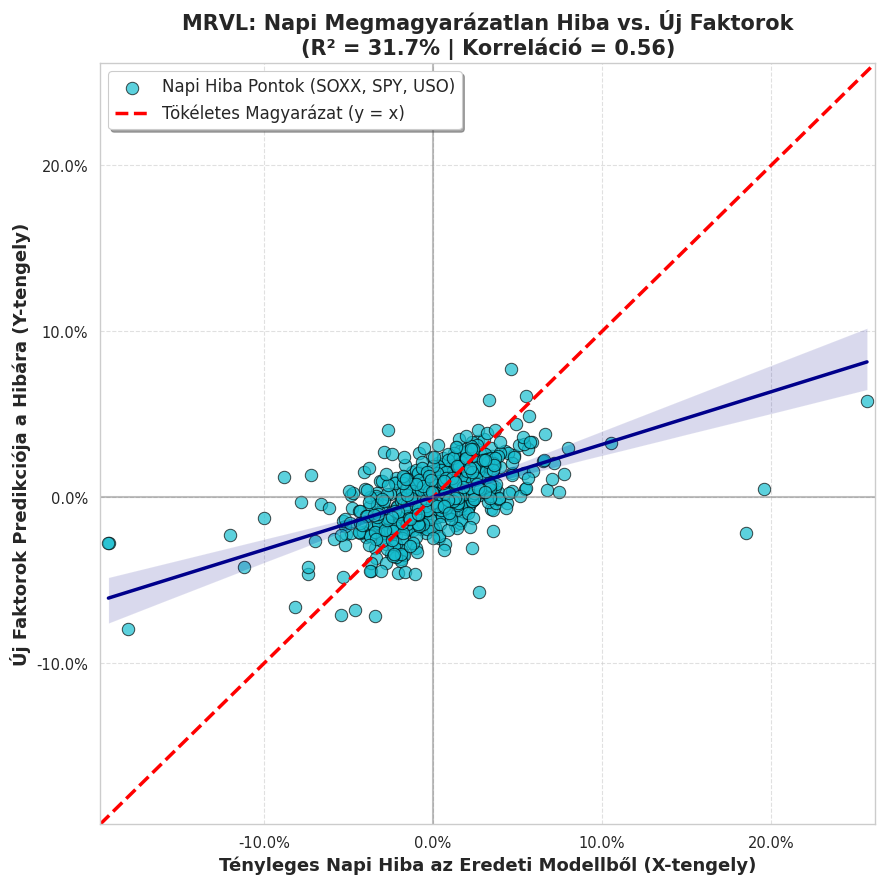


📊 SCATTERPLOT: LRCX (Napi hibák magyarázata)
--------------------------------------------------
--- Training Phase: Stepwise Selection for LRCX_Resid ---


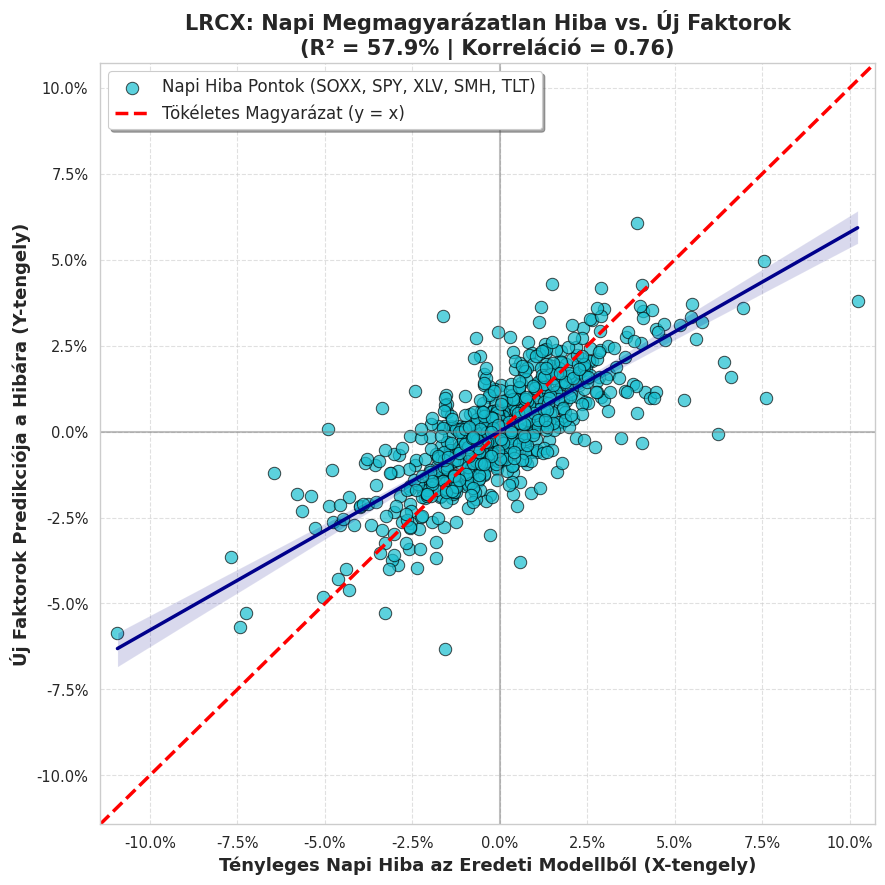


📊 SCATTERPLOT: AVGO (Napi hibák magyarázata)
--------------------------------------------------
--- Training Phase: Stepwise Selection for AVGO_Resid ---


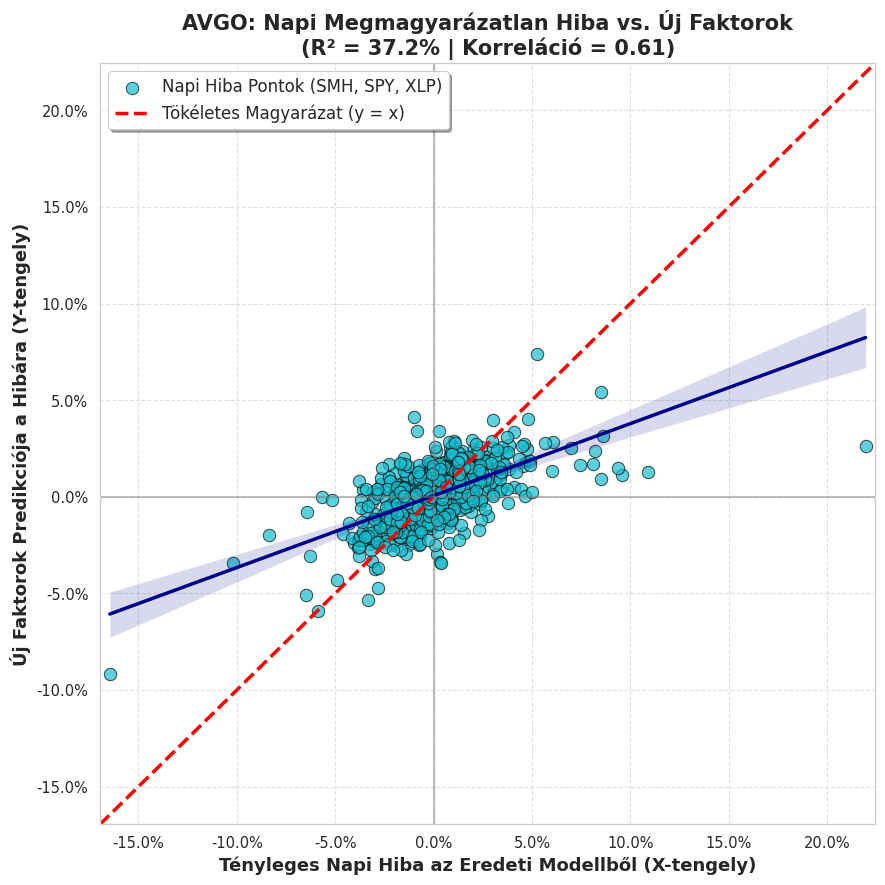


📊 SCATTERPLOT: NVDA (Napi hibák magyarázata)
--------------------------------------------------
--- Training Phase: Stepwise Selection for NVDA_Resid ---


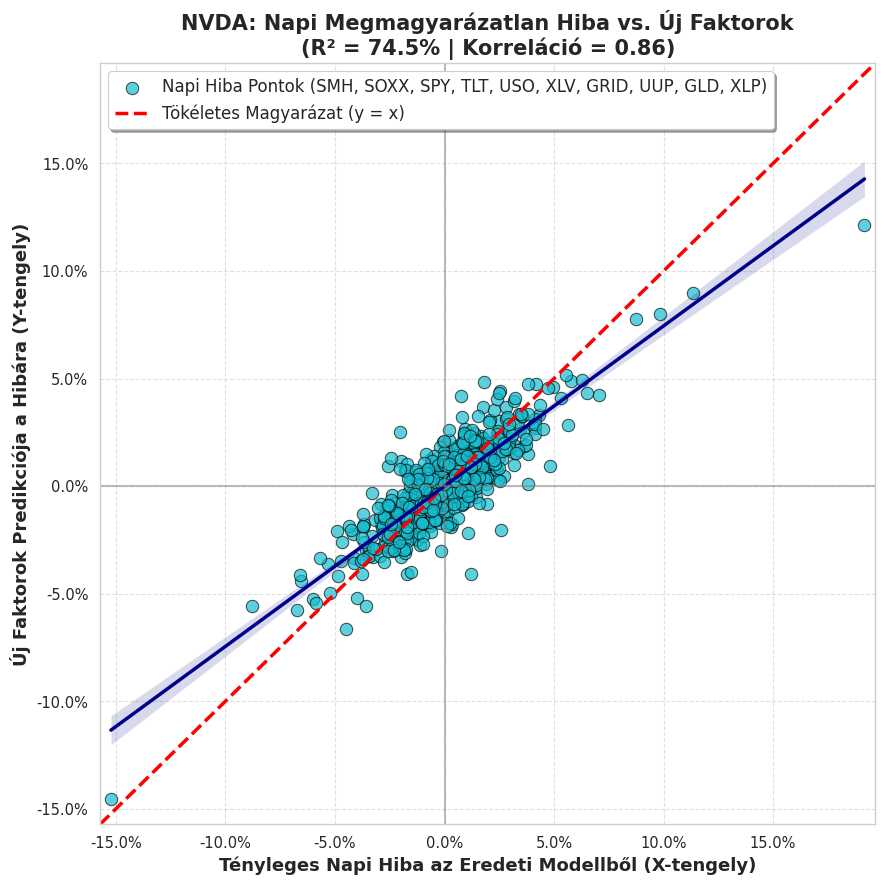


📊 SCATTERPLOT: AMD (Napi hibák magyarázata)
--------------------------------------------------
--- Training Phase: Stepwise Selection for AMD_Resid ---


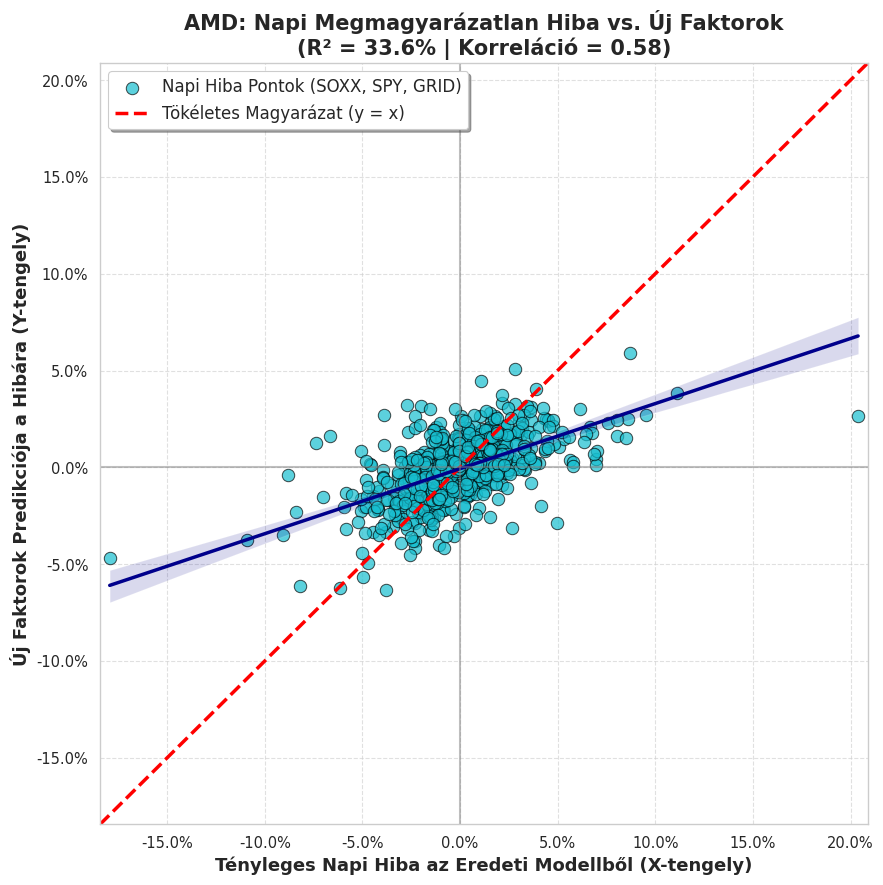


📊 SCATTERPLOT: MU (Napi hibák magyarázata)
--------------------------------------------------
--- Training Phase: Stepwise Selection for MU_Resid ---


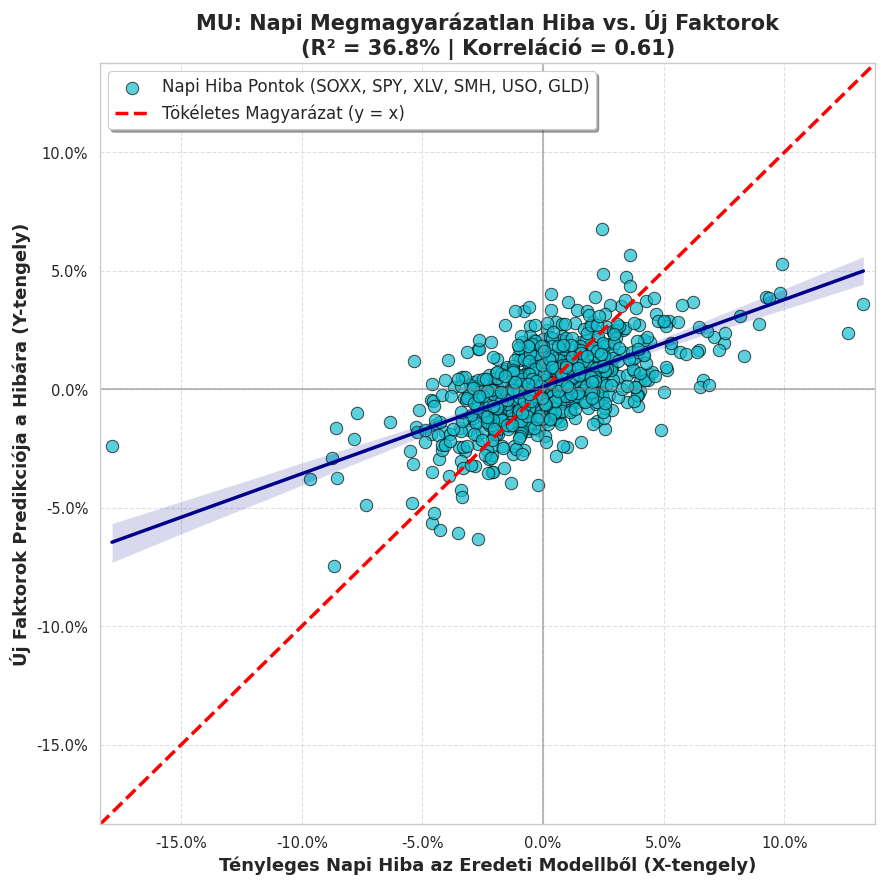


📊 SCATTERPLOT: ANET (Napi hibák magyarázata)
--------------------------------------------------
--- Training Phase: Stepwise Selection for ANET_Resid ---


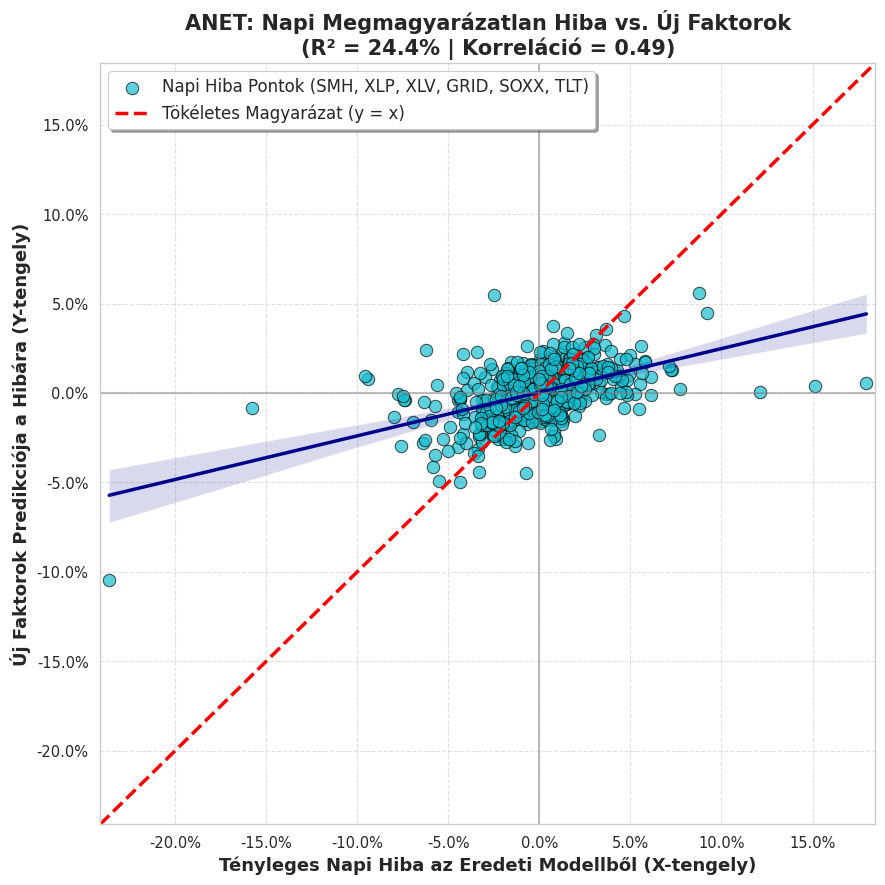


📊 SCATTERPLOT: INTC (Napi hibák magyarázata)
--------------------------------------------------
--- Training Phase: Stepwise Selection for INTC_Resid ---


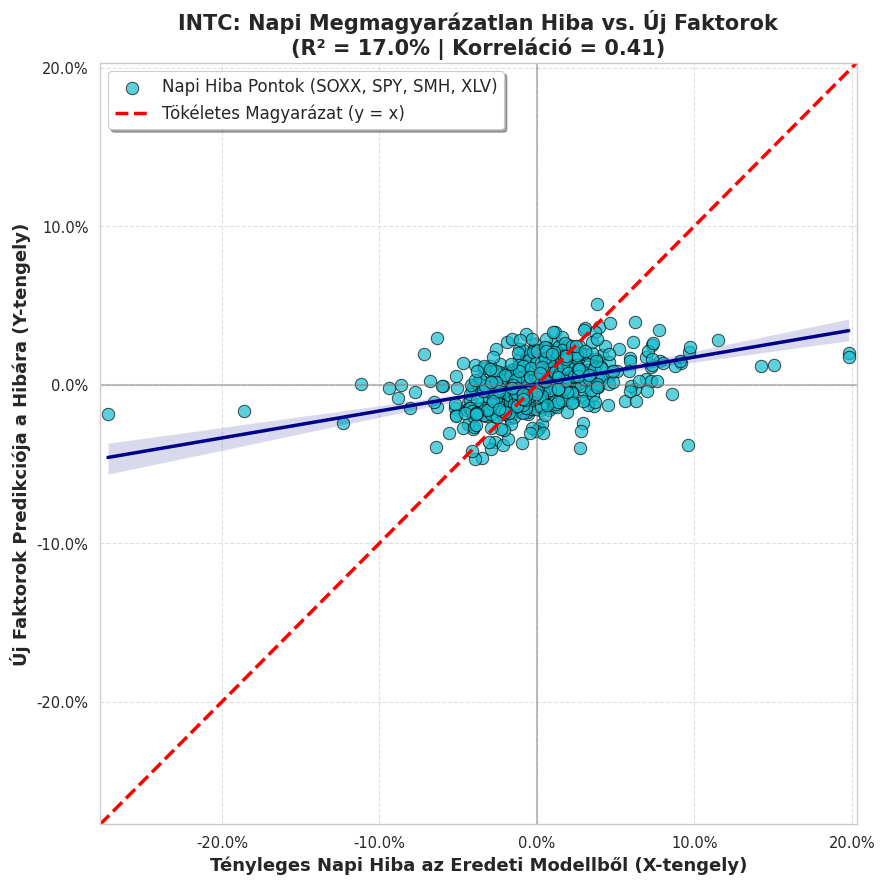


📊 SCATTERPLOT: STX (Napi hibák magyarázata)
--------------------------------------------------
--- Training Phase: Stepwise Selection for STX_Resid ---


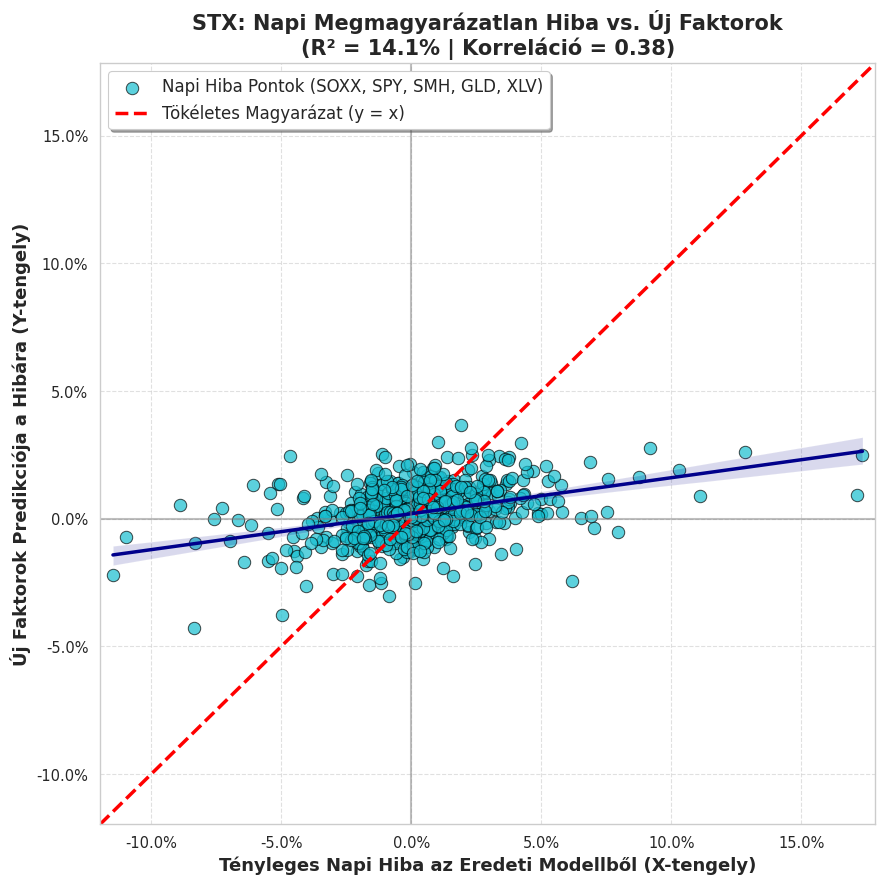


📊 SCATTERPLOT: SNPS (Napi hibák magyarázata)
--------------------------------------------------
--- Training Phase: Stepwise Selection for SNPS_Resid ---


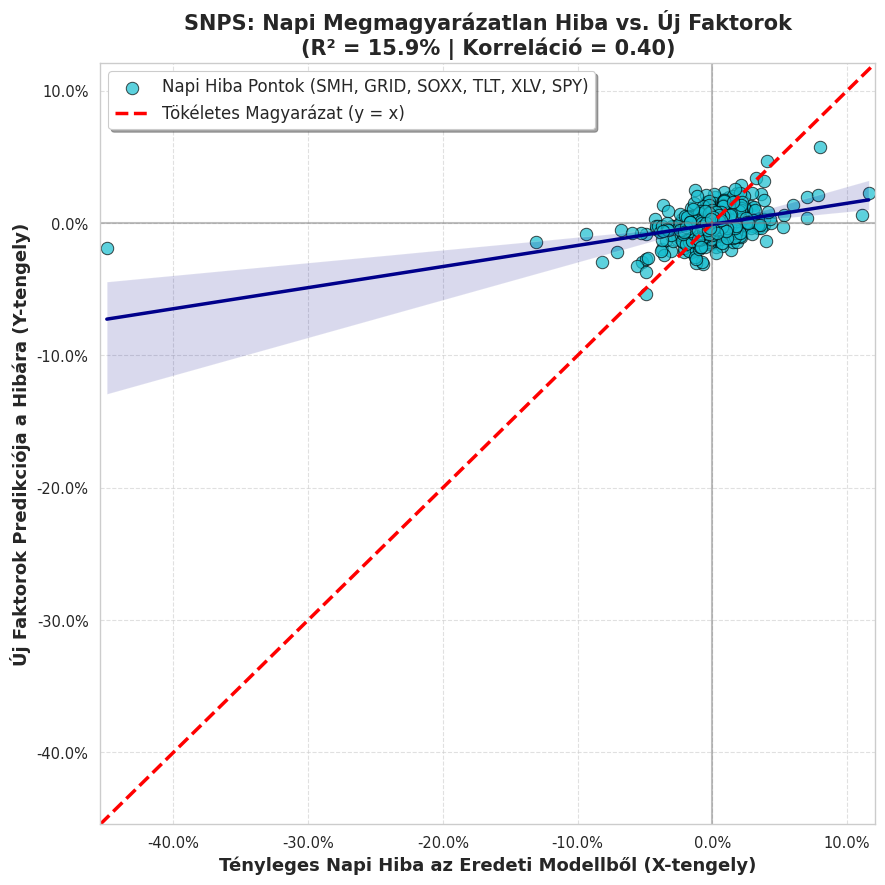

In [ ]:
# ==========================================
# SCATTERPLOT: RESIDUAL ERROR VS. AI-FACTOR PREDICTION
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import numpy as np
from matplotlib.ticker import FuncFormatter

def plot_residual_scatter(ticker):
    """
    Creates a scatterplot showing the actual daily residual error vs.
    what the newly built AI-factor model predicts that error should be.
    """
    if ticker not in post_break_residuals.columns:
        print(f"❌ {ticker} nem található a reziduális adatok között.")
        return

    print(f"\n📊 SCATTERPLOT: {ticker} (Napi hibák magyarázata)")
    print("-" * 50)

    # 1. Grab the actual unexplained error (residuals)
    y_residuals = post_break_residuals[ticker]
    X_candidates = test_data[valid_candidates]

    # 2. Use your existing stepwise logic to quickly grab the "already built" model features
    selected_features = stepwise_selection(
        X=X_candidates,
        y=y_residuals,
        target_stock=f"{ticker}_Resid",
        threshold_in=0.10,
        threshold_out=0.15,
        show_model_params=False
    )

    if not selected_features:
        print(f"⚠️ Nincs szignifikáns magyarázó faktor.")
        return

    # 3. Fit the OLS on the residuals to get the daily predictions
    X_final = sm.add_constant(X_candidates[selected_features])
    resid_model = sm.OLS(y_residuals, X_final).fit()
    y_resid_pred = resid_model.predict(X_final)

    corr = np.corrcoef(y_residuals, y_resid_pred)[0, 1]

    # ==========================================
    # 4. VISUALIZATION: SCATTER PLOT
    # ==========================================
    plt.figure(figsize=(9, 9)) # Square aspect ratio for a true 1:1 visual

    # Check if an AI factor was used to color the dots blue, otherwise orange
    dot_color = '#17becf' if any(f in selected_features for f in ai_factors) else '#ff7f0e'

    # Plot the daily points
    sns.scatterplot(
        x=y_residuals,
        y=y_resid_pred,
        alpha=0.7,
        color=dot_color,
        edgecolor='black',
        s=80,
        label=f'Napi Hiba Pontok ({", ".join(selected_features)})'
    )

    # Determine the boundaries so the chart is a perfect square
    min_val = min(y_residuals.min(), y_resid_pred.min()) - 0.005
    max_val = max(y_residuals.max(), y_resid_pred.max()) + 0.005

    # The "Perfect Explanation" line (y = x)
    plt.plot([min_val, max_val], [min_val, max_val],
             color='red', linestyle='--', linewidth=2.5, label='Tökéletes Magyarázat (y = x)')

    # The actual regression trend of the correction
    sns.regplot(
        x=y_residuals,
        y=y_resid_pred,
        scatter=False,
        color='darkblue',
        line_kws={'linewidth': 2.5, 'label': 'Tényleges Illeszkedési Trend'}
    )

    # Origin lines (0,0)
    plt.axhline(0, color='gray', linewidth=1.5, alpha=0.5)
    plt.axvline(0, color='gray', linewidth=1.5, alpha=0.5)

    # Format axes as percentages
    formatter = FuncFormatter(lambda y, _: '{:.1%}'.format(y))
    plt.gca().xaxis.set_major_formatter(formatter)
    plt.gca().yaxis.set_major_formatter(formatter)

    # Titles and labels
    plt.title(f"{ticker}: Napi Megmagyarázatlan Hiba vs. Új Faktorok\n(R² = {resid_model.rsquared*100:.1f}% | Korreláció = {corr:.2f})", fontsize=15, fontweight='bold')
    plt.xlabel('Tényleges Napi Hiba az Eredeti Modellből (X-tengely)', fontsize=13, fontweight='bold')
    plt.ylabel(f'Új Faktorok Predikciója a Hibára (Y-tengely)', fontsize=13, fontweight='bold')

    # Lock axes limits to guarantee a 45-degree angle for the y=x line
    plt.xlim(min_val, max_val)
    plt.ylim(min_val, max_val)

    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend(loc='upper left', fontsize=12, frameon=True, shadow=True)
    plt.tight_layout()
    plt.show()

# ==========================================
# EXECUTE ON THE PREVIOUSLY ANALYZED TOP AI STOCKS
# ==========================================
# We use the 'top_ai_stocks' list we generated dynamically in the last step
if 'top_ai_stocks' in locals() and len(top_ai_stocks) > 0:
    for ticker in top_ai_stocks:
        plot_residual_scatter(ticker)
else:
    # Fallback just in case the variable didn't carry over
    fallback_stocks = ['NVDA', 'AMAT', 'LRCX']
    print(f"⚠️ A 'top_ai_stocks' változó nem található, futtatás a manuális Top 3-ra: {fallback_stocks}")
    for ticker in fallback_stocks:
        plot_residual_scatter(ticker)

# Új modelfüggvény

🏗️ SZEKVENCIÁLIS MODELL ÉPÍTÉS: NVDA
Lépés 1 | Hozzáadva: SMH   | P-érték: 4.9094e-198 | Magyarázott Hiba (R²): 69.00%
Lépés 2 | Hozzáadva: XLP   | P-érték: 1.7906e-09 | Magyarázott Hiba (R²): 4.59%
Lépés 3 | Hozzáadva: SOXX  | P-érték: 1.9198e-04 | Magyarázott Hiba (R²): 1.79%
Lépés 4 | Hozzáadva: SPY   | P-érték: 2.2157e-04 | Magyarázott Hiba (R²): 1.76%
------------------------------------------------------------
✅ Végső Faktor Láncolat: SMH -> XLP -> SOXX -> SPY



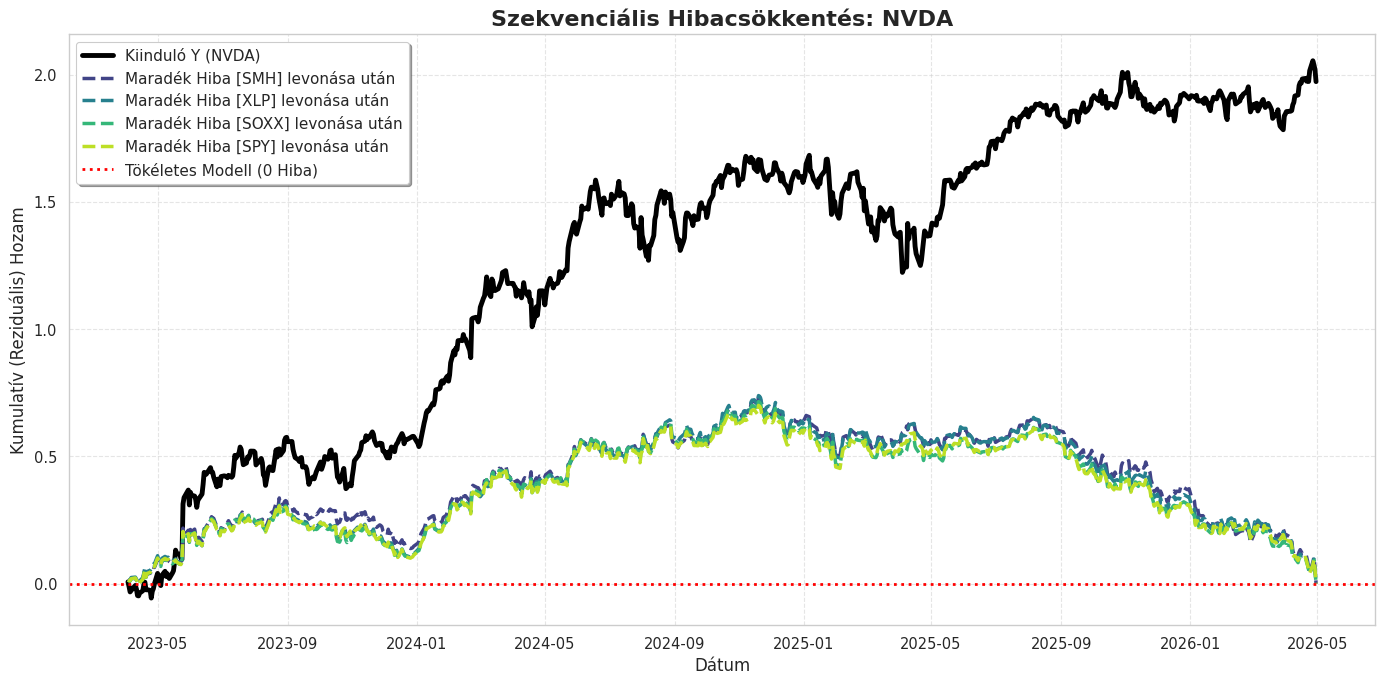

In [ ]:
# ==========================================
# 4. SEQUENTIAL (STAGEWISE) RESIDUAL BUILDER
# ==========================================
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

def stepwise_residual_builder(X, y, target_stock, max_steps=5, pval_threshold=0.05, show_plot=True):
    """
    Épít egy modellt szekvenciálisan:
    1. Lépés: Megkeresi a legjobb egyetlen faktort az Y-ra. Kiszámolja a reziduálist.
    2. Lépés: Megkeresi a legjobb faktort az ÚJ reziduálisra. Kiszámolja a következő reziduálist.
    Ezt ismétli, amíg el nem éri a max lépésszámot, vagy nincs több szignifikáns faktor.
    """
    available_factors = list(X.columns)
    selected_factors = []
    step_models = []

    # A célváltozó kezdetben maga a nyers hozam (vagy az eredeti hiba, amit vizsgálsz)
    current_residual = y.copy()
    current_residual.name = f"{target_stock}_Base"

    # Nyomon követjük a reziduálisok alakulását a vizualizációhoz
    residual_history = [current_residual.copy()]

    print("=" * 60)
    print(f"🏗️ SZEKVENCIÁLIS MODELL ÉPÍTÉS: {target_stock}")
    print("=" * 60)

    for step in range(1, max_steps + 1):
        best_pval = 1.0
        best_factor = None
        best_model = None

        # Teszteljük az összes MÉG ELÉRHETŐ faktort a JELENLEGI reziduálisra
        for factor in available_factors:
            X_factor = sm.add_constant(X[factor])
            model = sm.OLS(current_residual, X_factor).fit()

            pval = model.pvalues[factor]

            if pval < best_pval:
                best_pval = pval
                best_factor = factor
                best_model = model

        # Ha a legjobb faktor elég szignifikáns, hozzáadjuk a lánchoz
        if best_pval < pval_threshold and best_factor is not None:
            selected_factors.append(best_factor)
            step_models.append(best_model)

            r2_step = best_model.rsquared
            print(f"Lépés {step} | Hozzáadva: {best_factor:5} | P-érték: {best_pval:.4e} | Magyarázott Hiba (R²): {r2_step*100:.2f}%")

            # FRISSÍTJÜK A REZIDUÁLIST: Kivonjuk belőle azt, amit a mostani faktor megmagyarázott
            predictions = best_model.predict(sm.add_constant(X[best_factor]))
            current_residual = current_residual - predictions
            current_residual.name = f"{target_stock}_Resid_Step_{step}"

            residual_history.append(current_residual.copy())

            # Kivesszük a faktort a listából, hogy ne válasszuk ki újra
            available_factors.remove(best_factor)
        else:
            print(f"🛑 Leállás a {step}. lépésnél: Nincs több faktor, ami elérné a p < {pval_threshold} küszöböt.")
            break

    print("-" * 60)
    print(f"✅ Végső Faktor Láncolat: {' -> '.join(selected_factors)}\n")

    # ==========================================
    # VIZUALIZÁCIÓ: A hiba "lefaragása" lépésről lépésre
    # ==========================================
    if show_plot and len(selected_factors) > 0:
        plt.figure(figsize=(14, 7))

        # Eredeti kiindulási pont (Legvastagabb fekete vonal)
        cum_base = residual_history[0].cumsum()
        plt.plot(cum_base.index, cum_base, label=f'Kiinduló Y ({target_stock})', color='black', linewidth=3.5)

        # Színskála a lépésekhez (Egyre világosodó kék/lila színek)
        colors = plt.cm.viridis(np.linspace(0.2, 0.9, len(selected_factors)))

        for i, factor in enumerate(selected_factors):
            # A reziduális a faktor levonása UTÁN
            cum_resid = residual_history[i+1].cumsum()
            plt.plot(cum_resid.index, cum_resid,
                     label=f'Maradék Hiba [{factor}] levonása után',
                     color=colors[i], linewidth=2.5, linestyle='--')

        plt.axhline(0, color='red', linestyle=':', linewidth=2, label='Tökéletes Modell (0 Hiba)')

        plt.title(f"Szekvenciális Hibacsökkentés: {target_stock}", fontsize=16, fontweight='bold')
        plt.xlabel('Dátum', fontsize=12)
        plt.ylabel('Kumulatív (Reziduális) Hozam', fontsize=12)
        plt.legend(loc='best', fontsize=11, frameon=True, shadow=True)
        plt.grid(True, linestyle='--', alpha=0.5)
        plt.tight_layout()
        plt.show()

    return selected_factors, step_models, current_residual

# ==========================================
# TESZTELJÜK LE A FÜGGVÉNYT!
# ==========================================
# Példa futtatás: Célzottan az NVDA-n nézzük meg a teszt időszakban
ticker_to_test = 'NVDA'

# Jelöltek (AI + Hagyományos ETF-ek)
all_candidates = ['SPY', 'GLD', 'TLT', 'UUP', 'USO', 'XLP', 'GRID', 'XLV', 'SMH', 'SOXX']
valid_candidates = [c for c in all_candidates if c in test_data.columns]

if ticker_to_test in test_data.columns:
    X_test_candidates = test_data[valid_candidates]
    y_target = test_data[ticker_to_test] # Ide teheted a `post_break_residuals[ticker_to_test]`-t is!

    # Futtatás (Maximum 4 lépésig engedjük)
    chain, models, final_resid = stepwise_residual_builder(
        X=X_test_candidates,
        y=y_target,
        target_stock=ticker_to_test,
        max_steps=4,
        pval_threshold=0.05
    )

🏗️ SZEKVENCIÁLIS BÁZISMODELL ÉPÍTÉS (TRAIN ADATOK): GOOGL
Lépés 1 | Hozzáadva: SPY   | P-érték: 2.8941e-288 | Ezen réteg R²-je: 54.00%
Lépés 2 | Hozzáadva: XLP   | P-érték: 1.9716e-05 | Ezen réteg R²-je: 1.07%
Lépés 3 | Hozzáadva: TLT   | P-érték: 8.5497e-03 | Ezen réteg R²-je: 0.41%
Lépés 4 | Hozzáadva: XLV   | P-érték: 4.3965e-03 | Ezen réteg R²-je: 0.48%
Lépés 5 | Hozzáadva: USO   | P-érték: 1.5333e-02 | Ezen réteg R²-je: 0.35%
----------------------------------------------------------------------
✅ Végső Bázismodell Faktor Láncolata: SPY -> XLP -> TLT -> XLV -> USO



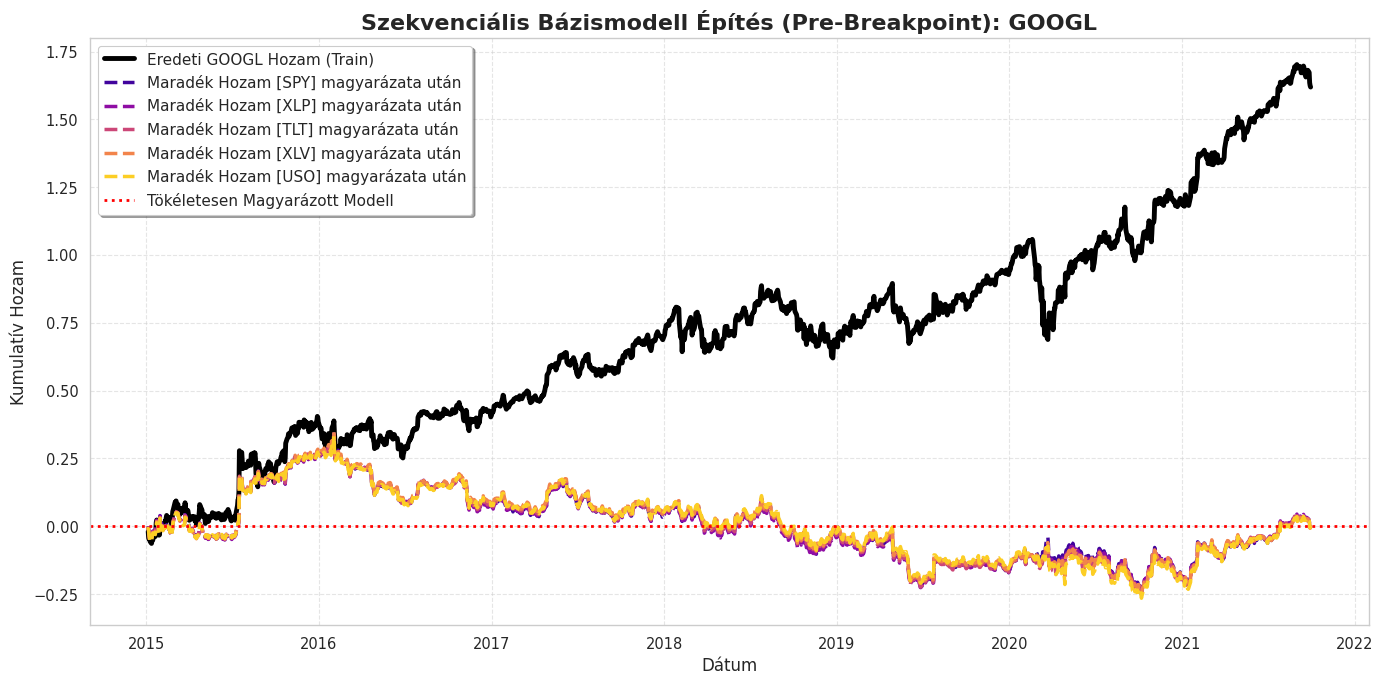

In [ ]:
# ==========================================
# 5. STAGEWISE (SEQUENTIAL) BASE MODEL BUILDER
# ==========================================
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

def stagewise_base_builder(X_train, y_train, target_stock, max_steps=5, pval_threshold=0.05, show_plot=True):
    """
    Szekvenciálisan építi fel az eredeti bázismodellt a tanuló (Train) adatokon.
    Minden lépésben a legszignifikánsabb faktort választja, majd a maradék hozamra keres tovább.

    Bemenet:
    - X_train: A faktorok DataFrame-je a tanuló időszakra (Pre-Breakpoint).
    - y_train: A célrészvény hozamsora a tanuló időszakra.
    - max_steps: Maximum hány faktort engedünk bevonni.
    - pval_threshold: Milyen p-érték alatt fogadunk el egy faktort.

    Kimenet:
    - selected_factors: A kiválasztott faktorok listája sorrendben.
    - step_models: A lépésenkénti OLS modellek listája.
    - final_residual: A tanuló időszak legvégső megmagyarázatlan hibája.
    """
    available_factors = list(X_train.columns)
    selected_factors = []
    step_models = []

    # A kiindulási pont a részvény tényleges napi hozama a Train időszakban
    current_target = y_train.copy()
    current_target.name = f"{target_stock}_Raw_Returns"

    # Nyomon követjük a hozamok/reziduálisok alakulását a vizualizációhoz
    residual_history = [current_target.copy()]

    print("=" * 70)
    print(f"🏗️ SZEKVENCIÁLIS BÁZISMODELL ÉPÍTÉS (TRAIN ADATOK): {target_stock}")
    print("=" * 70)

    for step in range(1, max_steps + 1):
        best_pval = 1.0
        best_factor = None
        best_model = None

        # Végignézzük a még be nem vont faktorokat
        for factor in available_factors:
            X_factor = sm.add_constant(X_train[factor])
            model = sm.OLS(current_target, X_factor).fit()

            pval = model.pvalues[factor]

            if pval < best_pval:
                best_pval = pval
                best_factor = factor
                best_model = model

        # Ha statisztikailag szignifikáns, bevonjuk a modellbe
        if best_pval < pval_threshold and best_factor is not None:
            selected_factors.append(best_factor)
            step_models.append(best_model)

            r2_step = best_model.rsquared
            print(f"Lépés {step} | Hozzáadva: {best_factor:5} | P-érték: {best_pval:.4e} | Ezen réteg R²-je: {r2_step*100:.2f}%")

            # FRISSÍTÉS: Kivonjuk a hozamból azt, amit a faktor most megmagyarázott (így kapjuk az új reziduálist)
            predictions = best_model.predict(sm.add_constant(X_train[best_factor]))
            current_target = current_target - predictions
            current_target.name = f"{target_stock}_Resid_Step_{step}"

            residual_history.append(current_target.copy())
            available_factors.remove(best_factor)
        else:
            print(f"🛑 Leállás a {step}. lépésnél: Nincs több szignifikáns faktor (p < {pval_threshold}).")
            break

    print("-" * 70)
    print(f"✅ Végső Bázismodell Faktor Láncolata: {' -> '.join(selected_factors)}\n")

    # ==========================================
    # VIZUALIZÁCIÓ: A részvényhozam "lefaragása" a bázis időszakban
    # ==========================================
    if show_plot and len(selected_factors) > 0:
        plt.figure(figsize=(14, 7))

        # Eredeti nyers hozam a Train időszakban (Fekete vonal)
        cum_base = residual_history[0].cumsum()
        plt.plot(cum_base.index, cum_base, label=f'Eredeti {target_stock} Hozam (Train)', color='black', linewidth=3.5)

        # Színskála a lépésekhez
        colors = plt.cm.plasma(np.linspace(0.1, 0.9, len(selected_factors)))

        for i, factor in enumerate(selected_factors):
            # A hozam a faktor levonása UTÁN (ez az egyre tisztuló hiba)
            cum_resid = residual_history[i+1].cumsum()
            plt.plot(cum_resid.index, cum_resid,
                     label=f'Maradék Hozam [{factor}] magyarázata után',
                     color=colors[i], linewidth=2.5, linestyle='--')

        plt.axhline(0, color='red', linestyle=':', linewidth=2, label='Tökéletesen Magyarázott Modell')

        plt.title(f"Szekvenciális Bázismodell Építés (Pre-Breakpoint): {target_stock}", fontsize=16, fontweight='bold')
        plt.xlabel('Dátum', fontsize=12)
        plt.ylabel('Kumulatív Hozam', fontsize=12)
        plt.legend(loc='best', fontsize=11, frameon=True, shadow=True)
        plt.grid(True, linestyle='--', alpha=0.5)
        plt.tight_layout()
        plt.show()

    return selected_factors, step_models, current_target

# ==========================================
# TESZTELJÜK LE A BÁZISMODELL ÉPÍTŐT!
# ==========================================
# Válasszunk egy részvényt és használjuk a TRAIN (Pre-2021) adatokat
ticker_to_test = 'GOOGL'

# Az eredeti bázis faktorjelöltjeid (a te korábbi kódodból, pl. fixált makró ETF-ek)
base_candidates = ['SPY', 'GLD', 'TLT', 'USO', 'UUP', 'XLP', 'XLV']
valid_train_candidates = [c for c in base_candidates if c in train_data.columns]

if ticker_to_test in train_data.columns:
    X_train_candidates = train_data[valid_train_candidates]
    y_train_target = train_data[ticker_to_test]

    # Futtatás
    chain, models, final_train_resid = stagewise_base_builder(
        X_train=X_train_candidates,
        y_train=y_train_target,
        target_stock=ticker_to_test,
        max_steps=5,
        pval_threshold=0.05
    )

# Havi futtatás

🔄 Indul a gördülő havi analízis: AAPL...
✅ Kész! 52 hónap idősoros fejlődése kielemezve.



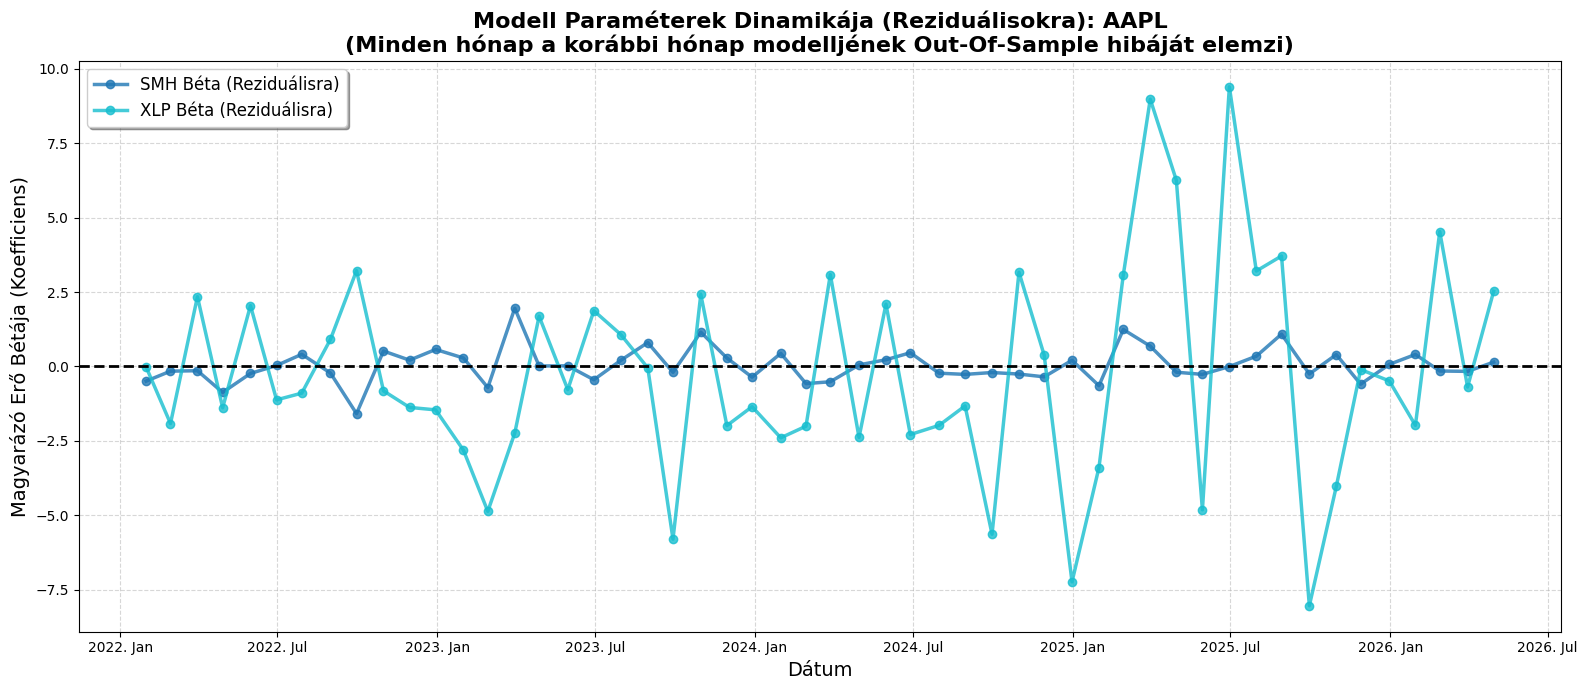

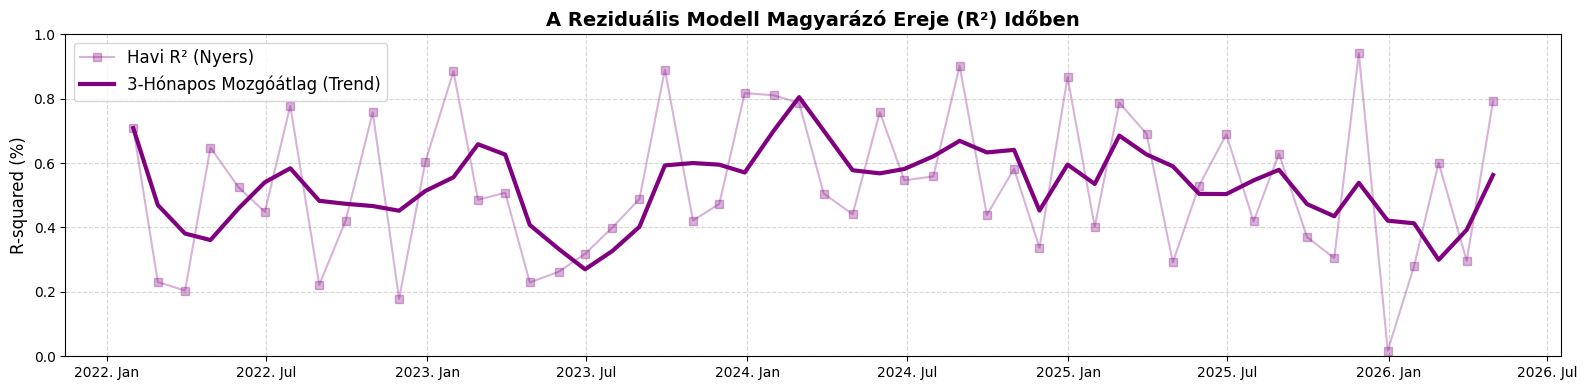

In [ ]:
# ==========================================
# GÖRDÜLŐ (ROLLING) HAVI REZIDUÁLIS MODELL
# ==========================================
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

def rolling_monthly_residual_analysis(df_returns, target_stock, base_factors, residual_candidates, start_date):
    """
    Végigmegy az adatsoron havi lépésekben.
    A 'T' hónapon betanítja a bázismodellt, a 'T+1' hónapon kiértékeli (reziduálisok).
    Ezután a 'T+1' hónap reziduálisaira ráilleszti a residual_candidates faktorokat,
    és rögzíti a paraméterek (béták) változását az idő múlásával.
    """
    # Dátum index biztosítása
    df = df_returns.copy()
    df.index = pd.to_datetime(df.index)

    # Szűrünk a kezdődátum - 1 hónapra, hogy legyen miből tanulni az első teszt hónaphoz
    start_dt = pd.to_datetime(start_date) - pd.DateOffset(months=1)
    df_sub = df[df.index >= start_dt].copy()

    # Létrehozunk egy Hónap/Év oszlopot a könnyebb csoportosításért
    df_sub['YearMonth'] = df_sub.index.to_period('M')
    months = df_sub['YearMonth'].unique()

    results = []
    print(f"🔄 Indul a gördülő havi analízis: {target_stock}...")

    # Végigmegyünk a hónapokon (az utolsó előttiig, mert mindig kell egy "következő" hónap)
    for i in range(len(months) - 1):
        train_month = months[i]
        test_month = months[i+1]

        # Adatok szétválasztása
        train_data = df_sub[df_sub['YearMonth'] == train_month]
        test_data = df_sub[df_sub['YearMonth'] == test_month]

        # Minimum adatpont ellenőrzés a regresszióhoz (legalább ~15 kereskedési nap)
        if len(train_data) < 15 or len(test_data) < 15:
            continue

        # ----------------------------------------------------
        # 1. BÁZISMODELL ÉPÍTÉSE A TANULÓ HÓNAPON (M)
        # ----------------------------------------------------
        y_train = train_data[target_stock]
        X_train = sm.add_constant(train_data[base_factors])

        try:
            base_model = sm.OLS(y_train, X_train).fit()
        except:
            continue # Ha multikollinearitás hiba van, átugorjuk a hónapot

        # ----------------------------------------------------
        # 2. PREDIKCIÓ ÉS REZIDUÁLIS A TESZT HÓNAPON (M+1)
        # ----------------------------------------------------
        y_test_actual = test_data[target_stock]
        X_test = sm.add_constant(test_data[base_factors], has_constant='add')
        y_test_pred = base_model.predict(X_test)

        # A megmagyarázatlan hiba az aktuális teszt hónapra
        test_residuals = y_test_actual - y_test_pred

        # ----------------------------------------------------
        # 3. REZIDUÁLIS MODELL ÉPÍTÉSE A TESZT HÓNAPON (M+1)
        # ----------------------------------------------------
        # Megnézzük, hogy az új faktor-kandidátusok mennyire tudják magyarázni a hibát
        X_resid = sm.add_constant(test_data[residual_candidates], has_constant='add')

        try:
            resid_model = sm.OLS(test_residuals, X_resid).fit()
        except:
            continue

        # ----------------------------------------------------
        # 4. PARAMÉTEREK ELMENTÉSE
        # ----------------------------------------------------
        step_result = {
            'Date': test_data.index[-1], # A hónap utolsó napjához kötjük az adatot
            'Resid_R2': resid_model.rsquared
        }

        # Kimentjük az összes vizsgált faktor együtthatóját (Bétáját)
        for col in residual_candidates:
            step_result[f'{col}_Beta'] = resid_model.params.get(col, 0)
            step_result[f'{col}_Pval'] = resid_model.pvalues.get(col, 1)

        results.append(step_result)

    # Eredmények DataFrame-be rendezése
    results_df = pd.DataFrame(results).set_index('Date')
    print(f"✅ Kész! {len(results_df)} hónap idősoros fejlődése kielemezve.\n")

    # ==========================================
    # VIZUALIZÁCIÓ
    # ==========================================
    # 1. Ábra: Béta paraméterek változása az idő múlásával
    plt.figure(figsize=(16, 7))

    # Dinamikus színek a faktorokhoz
    colors = plt.cm.tab10(np.linspace(0, 1, len(residual_candidates)))

    for idx, col in enumerate(residual_candidates):
        # Opcionális: Szűrhetnénk, hogy csak a szignifikáns (Pval < 0.05) bétákat mutassuk,
        # de a simítás miatt hasznos a teljes trendet látni.
        plt.plot(results_df.index, results_df[f'{col}_Beta'],
                 marker='o', linewidth=2.5, color=colors[idx], alpha=0.8,
                 label=f'{col} Béta (Reziduálisra)')

    plt.axhline(0, color='black', linestyle='--', linewidth=2)
    plt.title(f"Modell Paraméterek Dinamikája (Reziduálisokra): {target_stock}\n(Minden hónap a korábbi hónap modelljének Out-Of-Sample hibáját elemzi)", fontsize=16, fontweight='bold')
    plt.ylabel("Magyarázó Erő Bétája (Koefficiens)", fontsize=14)
    plt.xlabel("Dátum", fontsize=14)
    plt.legend(loc='upper left', fontsize=12, frameon=True, shadow=True)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y. %b'))
    plt.tight_layout()
    plt.show()

    # 2. Ábra: R-Squared (Magyarázó erő) változása
    plt.figure(figsize=(16, 4))

    # Kisimítjuk a vonalat egy 3 hónapos mozgóátlaggal a szebb vizualizációért
    r2_smoothed = results_df['Resid_R2'].rolling(window=3, min_periods=1).mean()

    plt.plot(results_df.index, results_df['Resid_R2'], color='purple', marker='s', alpha=0.3, label='Havi R² (Nyers)')
    plt.plot(results_df.index, r2_smoothed, color='purple', linewidth=3, label='3-Hónapos Mozgóátlag (Trend)')

    plt.title(f"A Reziduális Modell Magyarázó Ereje (R²) Időben", fontsize=14, fontweight='bold')
    plt.ylabel("R-squared (%)", fontsize=12)
    plt.ylim(0, 1) # R2 mindig 0 és 1 között van
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend(loc='upper left', fontsize=12)
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y. %b'))
    plt.tight_layout()
    plt.show()

    return results_df

# ==========================================
# TESZTELJÜK LE A FÜGGVÉNYT!
# ==========================================
# Beállítjuk a változókat az elemzéshez
ticker_to_test = 'AAPL' # Válassz egy izgalmas részvényt!
base_factors = ['SPY', 'GLD', 'TLT', 'USO'] # A régi, stabil bázis faktorok
residual_candidates = ['SMH', 'XLP'] # Amikkel a hibát próbáljuk magyarázni (AI vs Nem-AI)
start_analysis_date = '2022-01-01' # Honnan induljon a gördülő elemzés

# Futtatás
time_series_df = rolling_monthly_residual_analysis(
    df_returns=df, # Feltételezve, hogy a 'returns_df' a teljes globális hozamtáblád
    target_stock=ticker_to_test,
    base_factors=base_factors,
    residual_candidates=residual_candidates,
    start_date=start_analysis_date
)

In [ ]:
# ==========================================
# INTERAKTÍV ÖSSZESÍTETT FAKTOR-GRAFIKON (PLOTLY)
# ==========================================
import plotly.graph_objects as go

def plot_all_factors_interactive(results_df, target_stock):
    """
    Létrehoz egy interaktív (Plotly) többvonalas grafikont,
    amely megjeleníti az összes vizsgált faktor Bétájának változását az időben.
    """
    print(f"📊 Interaktív grafikon generálása a(z) {target_stock} részvényhez...")

    fig = go.Figure()

    # Kikeressük a DataFrame-ből azokat az oszlopokat, amik Béta értékeket tartalmaznak
    # (A korábbi függvényünk a {FaktorNeve}_Beta formátumban mentette el őket)
    beta_cols = [c for c in results_df.columns if c.endswith('_Beta')]

    # Minden egyes faktorhoz hozzáadunk egy vonalat a grafikonhoz
    for col in beta_cols:
        factor_name = col.replace('_Beta', '')

        # A vonal vastagsága: az SMH és SOXX (AI) legyen vastagabb, hogy kiemelkedjen
        line_width = 4 if factor_name in ['SMH', 'SOXX'] else 2

        fig.add_trace(go.Scatter(
            x=results_df.index,
            y=results_df[col],
            mode='lines+markers',
            name=factor_name,
            line=dict(width=line_width),
            marker=dict(size=6)
        ))

    # Hozzáadunk egy vízszintes nullvonalat (ahol a faktor elveszti a magyarázó erejét)
    fig.add_hline(y=0, line_dash="dash", line_color="black", opacity=0.5)

    # Keresünk egy potenciális "töréspontot" (pl. 2023 tavasza) és beteszünk egy segédvonalat
    # (Ezt átírhatod a te konkrét breakpointodra)
    break_date = '2023-04-01'
    if pd.to_datetime(break_date) in results_df.index or pd.to_datetime(break_date) < results_df.index.max():
        fig.add_vline(x=pd.to_datetime(break_date).timestamp() * 1000,
                      line_dash="dot", line_color="red", line_width=2,
                      annotation_text=" Strukturális Törés", annotation_position="top right")

    # Formázás és elrendezés
    fig.update_layout(
        title=dict(
            text=f"Minden Faktor Magyarázó Erejének (Béta) Változása az Időben: {target_stock}",
            font=dict(size=20)
        ),
        xaxis_title="Dátum",
        yaxis_title="Béta (Koefficiens)",
        legend_title="Vizsgált Faktorok",
        hovermode="x unified", # Egy vonalra húzva az összes értéket mutatja
        template="plotly_white",
        height=600
    )

    # Megjelenítés
    fig.show()

# ==========================================
# FUTTATÁS
# ==========================================
# Feltételezve, hogy a korábbi futtatás eredményét a 'time_series_df' változóba mentetted
if 'time_series_df' in locals() and not time_series_df.empty:
    plot_all_factors_interactive(time_series_df, ticker_to_test)
else:
    print("⚠️ Kérlek, előbb futtasd le a rolling_monthly_residual_analysis függvényt, és mentsd az eredményt a 'time_series_df' változóba!")

📊 Interaktív grafikon generálása a(z) AAPL részvényhez...


# ==========================================
# DISZKRÉT HAVI FAKTOR ANALÍZIS ÉS PLOTLY VIZUALIZÁCIÓ
# ==========================================
import pandas as pd
import numpy as np
import statsmodels.api as sm
import plotly.graph_objects as go

def monthly_discrete_factor_dynamics(df_returns, target_stock, base_factors, ai_factors):
    """
    Szigorúan naptári hónapokra bontja az adatokat.
    Minden egyes hónapra illeszt egy független OLS modellt az összes faktorral,
    és rögzíti, hogy az adott hónapban mi volt a részvény fő mozgatórugója.
    """
    print(f"🔄 Diszkrét havi regresszió futtatása: {target_stock}...")

    all_factors = base_factors + ai_factors

    # Adatok előkészítése és NaN értékek eldobása
    df = df_returns[[target_stock] + all_factors].dropna().copy()
    df.index = pd.to_datetime(df.index)

    # Hónap/Év oszlop létrehozása a csoportosításhoz
    df['YearMonth'] = df.index.to_period('M')
    months = df['YearMonth'].unique()

    results = []
    dates = []

    # Végigmegyünk minden egyes naptári hónapon
    for month in months:
        df_month = df[df['YearMonth'] == month]

        # Egy hónapban kb. 21 kereskedési nap van.
        # Ha valamiért kevesebb mint 10 napunk van (pl. hiányos adat), átugorjuk.
        if len(df_month) < 10:
            continue

        y = df_month[target_stock]
        X = sm.add_constant(df_month[all_factors])

        try:
            model = sm.OLS(y, X).fit()

            # Kimentjük a Béta értékeket és az R2-t
            betas = model.params.to_dict()
            betas['R2'] = model.rsquared

            # A hónap utolsó napját használjuk az X-tengelyen a grafikonhoz
            dates.append(df_month.index[-1])
            results.append(betas)
        except:
            continue

    # Eredmények DataFrame-be rendezése
    results_df = pd.DataFrame(results, index=dates)
    print(f"✅ Számítás kész! ({len(results_df)} hónap kielemezve) Grafikon generálása...\n")

    # ==========================================
    # INTERAKTÍV PLOTLY GRAFIKON LÉTREHOZÁSA
    # ==========================================
    fig = go.Figure()

    # 1. BÁZIS FAKTOROK (Halványabb, szaggatott vonalak, markerekkel)
    for factor in base_factors:
        if factor in results_df.columns:
            fig.add_trace(go.Scatter(
                x=results_df.index, y=results_df[factor],
                mode='lines+markers', name=f"{factor} (Bázis)",
                line=dict(width=2, dash='dot'), opacity=0.6,
                marker=dict(size=6)
            ))

    # 2. AI FAKTOROK (Vastag, kiemelt vonalak, nagyobb markerekkel)
    colors_ai = ['#17becf', '#1f77b4', '#9467bd']
    for idx, factor in enumerate(ai_factors):
        if factor in results_df.columns:
            fig.add_trace(go.Scatter(
                x=results_df.index, y=results_df[factor],
                mode='lines+markers', name=f"{factor} (AI-Téma)",
                line=dict(width=4, color=colors_ai[idx % len(colors_ai)]),
                marker=dict(size=8)
            ))

    # Nullvonal
    fig.add_hline(y=0, line_dash="solid", line_color="black", opacity=0.8, line_width=1.5)

    # Strukturális törés jelzése
    break_date = '2023-04-01'
    if pd.to_datetime(break_date) in results_df.index or pd.to_datetime(break_date) < results_df.index.max():
        fig.add_vline(x=pd.to_datetime(break_date).timestamp() * 1000,
                      line_dash="dash", line_color="red", line_width=2.5,
                      annotation_text=" 🚨 Strukturális Törés", annotation_position="top left",
                      annotation=dict(font_size=14, font_color="red"))

    # Formázás
    fig.update_layout(
        title=dict(
            text=f"Független Havi Modellek (Béta Dinamika): {target_stock}<br><sup>Minden pont egy önálló naptári hónap eredménye</sup>",
            font=dict(size=18)
        ),
        xaxis_title="Dátum (Hónap vége)",
        yaxis_title="Havi Béta (Mennyire mozgott együtt abban a hónapban)",
        hovermode="x unified",
        template="plotly_white",
        height=650,
        legend=dict(
            yanchor="top", y=0.99,
            xanchor="left", x=0.01,
            bgcolor="rgba(255, 255, 255, 0.8)",
            bordercolor="Black", borderwidth=1
        )
    )

    fig.show()
    return results_df

# ==========================================
# TESZTELJÜK LE!
# ==========================================
ticker_to_test = 'NVDA'
base_factors_to_test = ['SPY', 'GLD', 'TLT', 'XLP']
ai_factors_to_test = ['SMH', 'SOXX']

# Futtatás
monthly_betas_df = monthly_discrete_factor_dynamics(
    df_returns=df,
    target_stock=ticker_to_test,
    base_factors=base_factors_to_test,
    ai_factors=ai_factors_to_test
)